# Reviewer 7: stroke feedback initialization and controlled alignment experiments

The initialization study uses the existing stroke split, six architectures, three seeds, two imbalance methods, 128 epochs, full batches and Adam at 0.001. Gaussian is rerun with Uniform, Orthogonal and Sparse under identical conditions. The controlled study uses these same stroke observations and labels; no additional dataset is introduced. Image architecture experiments and manuscript/letter edits are outside this notebook.

The data preparation, MLP, BP training and evaluation functions below are reused from `mckinsey_ff/FF_DFA_tests.ipynb`. Two corrections in DFA are necessary for the stated model and loss: its training forward now includes the MLP's dropout, and weighted cross entropy uses the sum of sample weights as its denominator. Consequently, the fresh Gaussian results, rather than archived results from a different implementation, are the paired baseline. Alignment is measured against true BP gradients at the **same DFA parameters, observations and dropout masks**. The output layer is excluded from the primary gradient cosine because its BP and DFA gradients coincide by construction.

Results retain the existing `results` / `final_metrics` schema inside each initialization. All raw histories, held-out predictions, figures, statistics and model checkpoints are saved under `code/reviewer7_results`. Numerical outputs and figures are also displayed in this notebook.

Run this notebook from `code/`. Data and the existing source notebooks remain in `mckinsey_ff/`; outputs are written to `reviewer7_results/`.

In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
# imports
from time import perf_counter
import json

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report, average_precision_score, brier_score_loss
from sklearn.linear_model import LogisticRegression

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, random_split
import torch.optim as optim

from imblearn.over_sampling import BorderlineSMOTE, ADASYN, RandomOverSampler
from imblearn.combine import SMOTEENN

import shap
from scipy.stats import spearmanr
from sklearn.metrics.pairwise import cosine_similarity



seed = 42
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

from pathlib import Path
from IPython.display import display
from scipy.stats import wilcoxon
import hashlib, platform, importlib.metadata
import os
DATA_DIR = Path("mckinsey_ff")
RESULT_DIR = Path("reviewer7_results")
(RESULT_DIR / "plots").mkdir(parents=True, exist_ok=True)
(RESULT_DIR / "models").mkdir(exist_ok=True)
torch.use_deterministic_algorithms(True)
torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = False
print("GPU:", torch.cuda.get_device_name(0) if device.type == "cuda" else None)
metadata = {
    "python": platform.python_version(),
    "packages": {p: importlib.metadata.version(p) for p in ["torch", "numpy", "pandas", "scipy", "scikit-learn", "imbalanced-learn", "nbformat", "nbclient"]},
    "device": str(device),
    "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else None,
    "dataset_sha256": hashlib.sha256((DATA_DIR / "stroke_cleaned.csv").read_bytes()).hexdigest(),
    "source_notebook_sha256": hashlib.sha256((DATA_DIR / "FF_DFA_tests.ipynb").read_bytes()).hexdigest(),
    "split_seed": 42, "dropout": 0.3, "epochs": 128, "optimizer": "Adam", "lr": 0.001,
    "feedback_seed_offset": 100000, "sparse_keep_fraction": 0.15,
    "gradient_cosine": "same state, same batch, same dropout mask; hidden parameters only",
    "timing": "includes alignment diagnostics; not comparable to archived training timings"
}
print(metadata)


Using device: cuda
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
{'python': '3.12.3', 'packages': {'torch': '2.6.0+cu126', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.15.2', 'scikit-learn': '1.6.1', 'imbalanced-learn': '0.13.0', 'nbformat': '5.10.4', 'nbclient': '0.10.0'}, 'device': 'cuda', 'gpu': 'NVIDIA GeForce RTX 3050 6GB Laptop GPU', 'dataset_sha256': 'd7617f2f0dd5a444a665d3d3570ef1565dd6bd25bbb22634f5a5895204705711', 'source_notebook_sha256': '5e69953af43b2e556aadcb1bd04b752921813dbd2dbddd9b268bec64f582732a', 'split_seed': 42, 'dropout': 0.3, 'epochs': 128, 'optimizer': 'Adam', 'lr': 0.001, 'feedback_seed_offset': 100000, 'sparse_keep_fraction': 0.15, 'gradient_cosine': 'same state, same batch, same dropout mask; hidden parameters only', 'timing': 'includes alignment diagnostics; not comparable to archived training timings'}


## 1. Stroke data and the existing training protocol

In [2]:
df = pd.read_csv(DATA_DIR / "stroke_cleaned.csv")

X = df.drop(columns=["stroke"])
y = df["stroke"]

FEATURE_NAMES = X.columns

df = X.copy()
df["target"] = y
df
assert X.notna().all().all() and set(y.unique()) == {0, 1}
print("Dataset:", X.shape, "Class counts:", y.value_counts().sort_index().to_dict())
display(df.head())

Dataset: (4995, 10) Class counts: {0: 4747, 1: 248}


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,target
0,1,67,0,1,1,2,1,228.69,36.6,1,1
1,0,61,0,0,1,3,0,202.21,28.1,2,1
2,1,80,0,1,1,2,0,105.92,32.5,2,1
3,0,49,0,0,1,2,1,171.23,34.4,3,1
4,0,79,1,0,1,3,0,174.12,24.0,2,1


In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

input_dim = X_train.shape[1]
output_dim = 2  # Binary classification
print(f"Input Features: {input_dim}, Output Classes: {output_dim}")

def prepare_data(imbalance_mode):
    scaler = StandardScaler()
    if imbalance_mode == "oversample":
        sm = BorderlineSMOTE(sampling_strategy='minority', random_state=seed)
        print("Oversampling method: ", sm)
        scaler.fit(X_train)
        X_train_res, y_train_res = sm.fit_resample(X_train, y_train)
        X_train_scaled = scaler.transform(X_train_res)
    else:
        X_train_scaled = scaler.fit_transform(X_train)
        y_train_res = y_train
    X_test_scaled = scaler.transform(X_test)

    X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32).to(device)
    y_train_tensor = torch.tensor(y_train_res, dtype=torch.long).to(device)
    X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
    y_test_tensor = torch.tensor(y_test.values, dtype=torch.long).to(device)

    class_counts = np.bincount(y_train_tensor.cpu().numpy())
    print(", ".join([f"Class {i}: {count}" for i, count in enumerate(class_counts)]))

    return X_train_tensor, y_train_tensor, X_test_tensor, y_test_tensor, scaler

Input Features: 10, Output Classes: 2


In [4]:
SEEDS = [4, 2896, 2387]
MODEL_WIDTHS = {
    'narrowing': [input_dim, 16, 8, output_dim],
    'compression': [input_dim, 16, 16, output_dim],
    'base': [input_dim, 32, 16, output_dim],
    'widening': [input_dim, 64, 64, output_dim],
    'outglass': [input_dim, 64, input_dim, output_dim],
    'hourglass': [input_dim, 16, input_dim, output_dim],
}
IMBALANCE_MODES = ['class_weight', 'oversample']
LEARNING_RULES = ['bp', 'dfa']

EPOCHS = 128

# Seed utilities
def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
FEEDBACK_INITS = ["gaussian", "uniform", "orthogonal", "sparse"]
metadata["seeds"] = SEEDS
metadata["architectures"] = MODEL_WIDTHS
metadata["imbalance_modes"] = IMBALANCE_MODES
(RESULT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")

1362

In [5]:
class MLP(nn.Module):
    def __init__(self, dims, learning_rule='bp'):
        super().__init__()
        self.net_dims = dims
        self.learning_rule = learning_rule
        
        layers = []; self.linear_layers = []
        for i in range(len(dims)-1):
            linear = nn.Linear(dims[i], dims[i+1])
            self.linear_layers.append(linear); layers.append(linear)
            if i < len(dims)-2:
                layers.append(nn.ReLU())
                layers.append(nn.Dropout(p=0.3))  # regularise
        self.net = nn.Sequential(*layers)
        # self._init_weights() # same init for all models; UPDATE: Apparently gives a bit worse results ?

    def forward(self, x):
        return self.net(x)
    
    def _init_weights(self):
        for layer in self.linear_layers:
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)

## 2. Variance matched fixed feedback

For $B^{(l)}\in\mathbb{R}^{n_l\times n_L}$, Gaussian entries have variance $1/n_L$ and Uniform bounds are $\pm\sqrt{3/n_L}$. With $n_l\ge n_L$, thin QR gives orthonormal columns; multiplying $Q$ by $\sqrt{n_l/n_L}$ gives mean squared entry $1/n_L$. QR diagonal signs are standardized so the draw has the usual rotational symmetry. This is column orthogonality, not orthogonality of every row.

Sparse feedback starts from Gaussian and retains $k=\max(1,\mathrm{round}(0.15n_ln_L))$ uniformly sampled entries without replacement. Multiplying retained values by $\sqrt{n_ln_L/k}$ preserves entry variance in expectation; finite matrices need not have identical realized variance. Rounding determines the realized sparsity. Rank, singular values, energy and sparsity are reported rather than assuming that sparse feedback is full rank.

Feedback uses its own seeded generator. Forward initialization and dropout randomness are identical for paired distributions; the number of draws needed to construct feedback cannot change training masks. BorderlineSMOTE uses training observations only, before the existing training-fitted scaling step. Calibration is measured on the unchanged native-prevalence test set, without post hoc recalibration.

In [6]:
def initialize_feedback(n_hidden, n_output, feedback_init, generator):
    shape = (n_hidden, n_output)
    if feedback_init == "gaussian":
        B = torch.randn(shape, generator=generator, device=device) / np.sqrt(n_output)
    elif feedback_init == "uniform":
        a = np.sqrt(3 / n_output)
        B = (2 * torch.rand(shape, generator=generator, device=device) - 1) * a
    elif feedback_init == "orthogonal":
        G = torch.randn(shape, generator=generator, device=device)
        Q, R = torch.linalg.qr(G, mode="reduced")
        signs = torch.sign(torch.diagonal(R))
        Q = Q * signs.unsqueeze(0)
        B = Q * np.sqrt(n_hidden / n_output)
    elif feedback_init == "sparse":
        G = torch.randn(shape, generator=generator, device=device) / np.sqrt(n_output)
        k = max(1, round(0.15 * G.numel()))
        mask = torch.zeros(G.numel(), device=device)
        mask[torch.randperm(G.numel(), generator=generator, device=device)[:k]] = 1
        B = G * mask.reshape(shape) * np.sqrt(G.numel() / k)
    else:
        raise ValueError(feedback_init)
    return B


def feedback_diagnostics(B):
    singular_values = torch.linalg.svdvals(B).detach().cpu().tolist()
    return {
        "shape": list(B.shape), "rank": int(torch.linalg.matrix_rank(B).item()),
        "sparsity": float((B == 0).float().mean().item()),
        "mean": float(B.mean().item()), "mean_square": float(B.square().mean().item()),
        "variance": float(B.var(unbiased=False).item()), "singular_values": singular_values,
        "condition_number": float(singular_values[0] / singular_values[-1]) if singular_values[-1] > 0 else None,
        "matrix": B.detach().cpu().tolist()
    }


def gradient_cosine(g, h):
    g = torch.cat([v.reshape(-1) for v in g])
    h = torch.cat([v.reshape(-1) for v in h])
    norm = g.norm() * h.norm()
    return float(torch.dot(g, h).div(norm).clamp(-1, 1).item()) if norm.item() > 0 else None


## 3. BP and DFA training

In [7]:
def train_bp(model, criterion, optimizer, X_tr_tensor, y_tr_tensor, X_te_tensor, y_te_tensor, epochs=128):
    train_losses, test_losses = [], []
    train_accs, test_accs = [], []

    grad_norms = []
    weight_updates = []
    convergence_rates = []

    prev_loss = None

    start_time = perf_counter()
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        
        # Training
        outputs = model(X_tr_tensor)
        loss = criterion(outputs, y_tr_tensor)
        loss.backward()
        
        # Gradients norm and ref
        total_norm = 0
        for p in model.parameters():
            if p.grad is not None:
                total_norm += p.grad.norm(2).item() ** 2
        grad_norm = total_norm ** 0.5
        grad_norms.append(grad_norm)
        
        # Update weights
        old_weights = [p.clone() for p in model.parameters()]
        optimizer.step()    
        update_norm = 0
        for old, new in zip(old_weights, model.parameters()):
            update_norm += (new - old).norm(2).item() ** 2
        weight_update_norm = update_norm ** 0.5
        weight_updates.append(weight_update_norm)
        
        # Convergence Rate
        if prev_loss is not None:
            improvement = abs(prev_loss - loss.item())
            rate = improvement / prev_loss if prev_loss > 0 else 0
        else: rate = None
        if rate is not None and epoch: convergence_rates.append(rate)
        prev_loss = loss.item()

        # Metrics
        preds_train = outputs.argmax(dim=1)
        train_acc = (preds_train == y_tr_tensor).float().mean().item()
        train_losses.append(loss.item())
        train_accs.append(train_acc)
        
        # Validation metrics
        model.eval()
        with torch.no_grad():
            test_out = model(X_te_tensor)
            test_loss = criterion(test_out, y_te_tensor).item()
            test_preds = test_out.argmax(dim=1)
            test_acc = (test_preds == y_te_tensor).float().mean().item()
        test_losses.append(test_loss)
        test_accs.append(test_acc)
        
    print(f"Epoch {epochs} | Train Loss: {loss.item():.4f}, Test Loss: {test_loss:.4f}, Train Acc: {train_acc:.4f}, Test Acc: {test_acc:.4f}")

    end_time = perf_counter()
    elapsed = end_time - start_time
    print(f"Training completed in {elapsed:.2f} seconds")

    return {
        'training time': elapsed,
        'train_losses': train_losses,
        'test_losses': test_losses,
        'train_accs': train_accs,
        'test_accs': test_accs,
        'grad_norms': grad_norms,
        'weight_updates': weight_updates,
        'convergence_rates': convergence_rates,
    }

In [8]:
def train_dfa(model, criterion, optimizer, X_tr_tensor, y_tr_tensor,
              X_te_tensor, y_te_tensor, epochs=128, feedback_init="gaussian", feedback_seed=4):
    linear_layers = model.linear_layers
    num_layers = len(linear_layers)
    generator = torch.Generator(device=device).manual_seed(feedback_seed + 100000)
    B = [initialize_feedback(layer.out_features, output_dim, feedback_init, generator)
         for layer in linear_layers[:-1]]
    diagnostics = [feedback_diagnostics(b) for b in B]
    train_losses, test_losses, train_accs, test_accs = [], [], [], []
    grad_norms, weight_updates, convergence_rates = [], [], []
    hidden_gradient_cosines, all_gradient_cosines, layer_gradient_cosines = [], [], []
    output_gradient_max_errors = []
    prev_loss = None
    if device.type == "cuda": torch.cuda.synchronize()
    start_time = perf_counter()

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        activations = [X_tr_tensor]
        preacts, gates = [], []
        for l, layer in enumerate(linear_layers):
            z = layer(activations[-1])
            preacts.append(z)
            if l < num_layers - 1:
                # Use the exact mask in both the forward graph and the DFA local derivative.
                mask = torch.nn.functional.dropout(torch.ones_like(z), p=0.3, training=True)
                activations.append(torch.relu(z) * mask)
                gates.append((z > 0).to(z.dtype) * mask)
            else:
                activations.append(z)
        outputs = activations[-1]
        loss = criterion(outputs, y_tr_tensor)
        bp_grads = torch.autograd.grad(loss, tuple(model.parameters()))

        with torch.no_grad():
            batch_size = outputs.size(0)
            delta_L = torch.softmax(outputs, dim=1) - torch.nn.functional.one_hot(y_tr_tensor, output_dim)
            if criterion.weight is not None:
                sample_w = criterion.weight[y_tr_tensor]
                delta_L *= sample_w.unsqueeze(1) * (batch_size / sample_w.sum())
            deltas = [delta_L @ B[l].T * gates[l] for l in range(num_layers - 1)] + [delta_L]
            dfa_grads = []
            for l, layer in enumerate(linear_layers):
                grad_W = deltas[l].T @ activations[l] / batch_size
                grad_b = deltas[l].mean(dim=0)
                layer.weight.grad = grad_W
                layer.bias.grad = grad_b
                dfa_grads.extend([grad_W, grad_b])
            hidden_gradient_cosines.append(gradient_cosine(dfa_grads[:-2], bp_grads[:-2]))
            all_gradient_cosines.append(gradient_cosine(dfa_grads, bp_grads))
            layer_gradient_cosines.append([gradient_cosine(dfa_grads[2*l:2*l+2], bp_grads[2*l:2*l+2])
                                           for l in range(num_layers - 1)])
            output_gradient_max_errors.append(max(float((g-h).abs().max().item())
                                                   for g,h in zip(dfa_grads[-2:], bp_grads[-2:])))
            assert output_gradient_max_errors[-1] < 1e-5, "DFA output must equal the loss gradient"
            grad_norms.append(float(torch.sqrt(sum(g.square().sum() for g in dfa_grads)).item()))
            old_weights = [p.clone() for p in model.parameters()]
            optimizer.step()
            weight_updates.append(float(torch.sqrt(sum((a-b).square().sum()
                                                       for a,b in zip(old_weights, model.parameters()))).item()))
        cur_loss = loss.item()
        assert np.isfinite(cur_loss), "Nonfinite training loss"
        if epoch:
            convergence_rates.append(abs(prev_loss - cur_loss) / prev_loss if prev_loss > 0 else 0.0)
        prev_loss = cur_loss
        train_losses.append(cur_loss)
        train_accs.append(float((outputs.argmax(1) == y_tr_tensor).float().mean().item()))
        model.eval()
        with torch.no_grad():
            test_out = model(X_te_tensor)
            test_losses.append(criterion(test_out, y_te_tensor).item())
            test_accs.append(float((test_out.argmax(1) == y_te_tensor).float().mean().item()))
    if device.type == "cuda": torch.cuda.synchronize()
    elapsed = perf_counter() - start_time
    print(f"Epoch {epochs} | Train loss {train_losses[-1]:.4f} | Test loss {test_losses[-1]:.4f} | Test accuracy {test_accs[-1]:.4f}")
    return {
        "training time": elapsed, "train_losses": train_losses, "test_losses": test_losses,
        "train_accs": train_accs, "test_accs": test_accs, "grad_norms": grad_norms,
        "weight_updates": weight_updates, "convergence_rates": convergence_rates,
        "hidden_gradient_cosines": hidden_gradient_cosines, "all_gradient_cosines": all_gradient_cosines,
        "layer_gradient_cosines": layer_gradient_cosines,
        "output_gradient_max_errors": output_gradient_max_errors, "feedback": diagnostics
    }


In [9]:
def calibration_metrics(y_true, y_prob, n_bins=10):
    # Brier Score
    brier = brier_score_loss(y_true, y_prob)

    # Expected Calibration Error (ECE)
    bin_edges = np.linspace(0.0, 1.0, n_bins+1)
    binids = np.digitize(y_prob, bin_edges[1:-1])
    ece = 0.0
    for i in range(n_bins):
        bin_mask = binids == i
        if np.sum(bin_mask) > 0:
            bin_conf = np.mean(y_prob[bin_mask])
            bin_acc = np.mean(y_true[bin_mask])
            ece += np.abs(bin_conf - bin_acc) * np.sum(bin_mask)
    ece /= len(y_true)

    # Calibration slope and intercept
    eps = 1e-7
    y_prob_safe = np.clip(y_prob, eps, 1-eps)
    logit_preds = np.log(y_prob_safe / (1-y_prob_safe))
    lr = LogisticRegression(solver="lbfgs")
    lr.fit(logit_preds.reshape(-1, 1), y_true)
    slope = lr.coef_[0][0]
    intercept = lr.intercept_[0]

    return brier, ece, slope, intercept

In [10]:
def final_metrics(model, X_te_tensor, y_te_tensor):
    model.eval()
    with torch.no_grad():
        test_out = model(X_te_tensor)
        test_preds = test_out.argmax(dim=1)

    y_true = y_te_tensor.cpu().numpy()
    y_pred = test_preds.cpu().numpy()

    probs = torch.softmax(test_out, dim=1)[:, 1].cpu().numpy()
    report = classification_report(y_true, y_pred, output_dict=True, zero_division=0)

    brier, ece, slope, intercept = calibration_metrics((y_true == 1).astype(int), probs)
    
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted"),
        "roc_auc": roc_auc_score((y_true==1).astype(int), probs),
        "aucpr": average_precision_score((y_true==1).astype(int), probs),
        "precision_0": report["0"]["precision"],
        "recall_0": report["0"]["recall"],
        "precision_1": report["1"]["precision"],
        "recall_1": report["1"]["recall"],
        "brier_score": brier,
        "ece": ece,
        "slope": slope,
        "intercept": intercept,
        }

def run_experiment(model, criterion, optimizer, X_tr_tensor, y_tr_tensor,
                   X_te_tensor, y_te_tensor, epochs=128, feedback_init="gaussian", feedback_seed=4):
    if model.learning_rule == 'bp':
        results = train_bp(model, criterion, optimizer, X_tr_tensor, y_tr_tensor,
                           X_te_tensor, y_te_tensor, epochs)
    elif model.learning_rule == 'dfa':
        results = train_dfa(model, criterion, optimizer, X_tr_tensor, y_tr_tensor,
                            X_te_tensor, y_te_tensor, epochs, feedback_init, feedback_seed)
    return results, final_metrics(model, X_te_tensor, y_te_tensor)


## 4. Full initialization grid

There are 144 DFA runs: four feedback distributions × two imbalance modes × six architectures × three seeds. No early stopping, seed selection, hyperparameter tuning on the test set or replacement of failed sparse projections is used. The existing BP implementation is retained for reference; this study compares DFA feedback distributions and does not need another BP grid. Each leaf keeps the original results format. Checkpoints contain the forward model and fixed feedback.

In [11]:
exp_results = {}
exp_count = 0
total_experiments = len(FEEDBACK_INITS) * len(IMBALANCE_MODES) * len(MODEL_WIDTHS) * len(SEEDS)
for feedback_init in FEEDBACK_INITS:
    exp_results[feedback_init] = {"dfa": {}}
    for imbalance_mode in IMBALANCE_MODES:
        exp_results[feedback_init]["dfa"][imbalance_mode] = {}
        for model_name, widths in MODEL_WIDTHS.items():
            exp_results[feedback_init]["dfa"][imbalance_mode][model_name] = {}
            for seed in SEEDS:
                exp_count += 1
                set_seed(seed)
                print(f"\n--- [{exp_count}/{total_experiments}] {feedback_init}, {imbalance_mode}, {model_name}, seed={seed} ---")
                X_train_tensor, y_train_tensor, X_test_tensor, y_test_tensor, scaler = prepare_data(imbalance_mode)
                model = MLP(widths, learning_rule="dfa").to(device)
                optimizer = optim.Adam(model.parameters(), lr=0.001)
                if imbalance_mode == "class_weight":
                    class_counts = np.bincount(y_train.values)
                    class_weights = len(y_train) / (2 * class_counts)
                    class_weights = class_weights / class_weights.mean()
                    criterion = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32, device=device))
                else:
                    criterion = nn.CrossEntropyLoss()
                results, final_metrics_results = run_experiment(model, criterion, optimizer,
                    X_train_tensor, y_train_tensor, X_test_tensor, y_test_tensor,
                    epochs=EPOCHS, feedback_init=feedback_init, feedback_seed=seed)
                with torch.no_grad():
                    logits = model(X_test_tensor).cpu().numpy()
                exp_results[feedback_init]["dfa"][imbalance_mode][model_name][seed] = {
                    "results": results, "final_metrics": final_metrics_results,
                    "test_predictions": {"indices": X_test.index.tolist(), "y_true": y_test.tolist(),
                                         "logits": logits.tolist()},
                    "scaler": {"mean": scaler.mean_.tolist(), "scale": scaler.scale_.tolist()}}
                torch.save({"dims": widths, "state_dict": model.state_dict(),
                            "feedback": results["feedback"], "feedback_init": feedback_init,
                            "seed": seed, "imbalance_mode": imbalance_mode},
                            RESULT_DIR / "models" / f"{feedback_init}_{imbalance_mode}_{model_name}_{seed}.pt")
                with open(RESULT_DIR / "exp_results.json", "w") as f:
                    json.dump(exp_results, f, indent=2, allow_nan=False)
print(f"Completed and saved all {exp_count} initialization experiments.")



--- [1/144] gaussian, class_weight, narrowing, seed=4 ---


Class 0: 3798, Class 1: 198


Epoch 128 | Train loss 0.6063 | Test loss 0.5815 | Test accuracy 0.6236



--- [2/144] gaussian, class_weight, narrowing, seed=2896 ---
Class 0: 3798, Class 1: 198


Epoch 128 | Train loss 0.6320 | Test loss 0.6217 | Test accuracy 0.4665

--- [3/144] gaussian, class_weight, narrowing, seed=2387 ---
Class 0: 3798, Class 1: 198


...


--- [143/144] sparse, oversample, hourglass, seed=2896 ---
Oversampling method:  BorderlineSMOTE(random_state=2896, sampling_strategy='minority')
Class 0: 3798, Class 1: 3798


Epoch 128 | Train loss 0.6652 | Test loss 0.6994 | Test accuracy 0.4955



--- [144/144] sparse, oversample, hourglass, seed=2387 ---
Oversampling method:  BorderlineSMOTE(random_state=2387, sampling_strategy='minority')
Class 0: 3798, Class 1: 3798


Epoch 128 | Train loss 0.6774 | Test loss 0.6317 | Test accuracy 0.8478


Completed and saved all 144 initialization experiments.


## 5. Accuracy, discrimination and calibration summaries

In [7]:
with open(RESULT_DIR / "exp_results.json") as f:
    exp_results = json.load(f)
for init in FEEDBACK_INITS:
    for mode in IMBALANCE_MODES:
        for name in MODEL_WIDTHS:
            exp_results[init]["dfa"][mode][name] = {int(s):r for s,r in exp_results[init]["dfa"][mode][name].items()}

rows = []
for feedback_init in FEEDBACK_INITS:
    for imbalance_mode in IMBALANCE_MODES:
        for model_name in MODEL_WIDTHS:
            for seed in SEEDS:
                res = exp_results[feedback_init]["dfa"][imbalance_mode][model_name][seed]
                rows.append({"feedback_init": feedback_init, "imbalance_mode": imbalance_mode,
                             "model": model_name, "seed": seed, **res["final_metrics"]})
run_metrics = pd.DataFrame(rows)
run_metrics.to_csv(RESULT_DIR / "run_metrics.csv", index=False)
metric_names = ["accuracy", "f1_macro", "f1_weighted", "roc_auc", "aucpr", "precision_1", "recall_1",
                "brier_score", "ece", "slope", "intercept"]
summary = run_metrics.groupby(["imbalance_mode", "feedback_init"])[metric_names].agg(["mean", lambda x: x.std(ddof=0)])
summary.columns = [f"{m}_{'sd' if a == '<lambda_0>' else a}" for m,a in summary.columns]
summary.to_csv(RESULT_DIR / "initialization_summary.csv")
display(summary.round(6))
architecture_summary = run_metrics.groupby(["imbalance_mode", "model", "feedback_init"])[metric_names].agg(["mean", lambda x: x.std(ddof=0)])
architecture_summary.to_csv(RESULT_DIR / "architecture_summary.csv")
display(architecture_summary[["accuracy", "f1_macro", "roc_auc", "brier_score", "ece"]].round(6))


accuracy_mean  accuracy_sd  f1_macro_mean  \
imbalance_mode feedback_init                                              
class_weight   gaussian            0.683795     0.071026       0.498765   
               orthogonal          0.664609     0.147395       0.483791   
               sparse              0.634245     0.167255       0.464258   
               uniform             0.669503     0.155327       0.486216   
oversample     gaussian            0.727227     0.077259       0.513270   
               orthogonal          0.704927     0.160410       0.497130   
               sparse              0.663886     0.150187       0.474116   
               uniform             0.719386     0.165699       0.503446   

                              f1_macro_sd  f1_weighted_mean  f1_weighted_sd  \
imbalance_mode feedback_init                                                  
class_weight   gaussian          0.040194          0.770455        0.056501   
               orthogonal        0.099429          0.743578        0.164067   
               sparse            0.102863          0.717788        0.166725   
               uniform           0.108347          0.744596        0.181654   
oversample     gaussian          0.043861          0.801235        0.058126   
               orthogonal        0.105175          0.771100        0.174203   
               sparse            0.085393          0.745961        0.133300   
               uniform           0.112353          0.779123        0.189109   

                              roc_auc_mean  roc_auc_sd  aucpr_mean  aucpr_sd  \
imbalance_mode feedback_init                                                   
class_weight   gaussian           0.797357    0.017763    0.177077  0.021440   
               orthogonal         0.796984    0.019323    0.177286  0.020278   
               sparse             0.762846    0.051614    0.150342  0.022346   
               uniform            0.793695    0.024440    0.176474  0.011159   
oversample     gaussian           0.745705    0.029187    0.182649  0.011481   
               orthogonal         0.745503    0.032440    0.182426  0.012017   
               sparse             0.710708    0.067835    0.143212  0.032330   
               uniform            0.748634    0.035466    0.183000  0.013161   

                              ...  recall_1_mean  recall_1_sd  \
imbalance_mode feedback_init  ...                               
class_weight   gaussian       ...       0.754444     0.054490   
               orthogonal     ...       0.758889     0.071639   
               sparse         ...       0.746667     0.134990   
               uniform        ...       0.766667     0.089194   
oversample     gaussian       ...       0.625556     0.046094   
               orthogonal     ...       0.642222     0.090894   
               sparse         ...       0.635556     0.121939   
               uniform        ...       0.628889     0.102463   

                              brier_score_mean  brier_score_sd  ece_mean  \
imbalance_mode feedback_init                                               
class_weight   gaussian               0.200229        0.027437  0.361962   
               orthogonal             0.201512        0.033719  0.362793   
               sparse                 0.220531        0.033207  0.403717   
               uniform                0.199158        0.036576  0.355419   
oversample     gaussian               0.178207        0.036895  0.318885   
               orthogonal             0.180094        0.043028  0.320164   
               sparse                 0.207850        0.041248  0.381523   
               uniform                0.173272        0.044587  0.306385   

                                ece_sd  slope_mean  slope_sd  intercept_mean  \
imbalance_mode feedback_init                                                   
class_weight   gaussian       0.055386    1.293703  0.436430       -2.976760   
               orthogonal     0.060

accuracy             f1_macro  \
                                              mean <lambda_0>      mean   
imbalance_mode model       feedback_init                                  
class_weight   base        gaussian       0.727728   0.017586  0.521094   
                           orthogonal     0.726727   0.015269  0.520410   
                           sparse         0.720053   0.017267  0.512543   
                           uniform        0.700033   0.027853  0.507026   
               compression gaussian       0.695028   0.048057  0.505560   
                           orthogonal     0.696363   0.049428  0.506471   
                           sparse         0.655322   0.083499  0.474740   
                           uniform        0.665999   0.053684  0.489970   
               hourglass   gaussian       0.677010   0.039657  0.490601   
                           orthogonal     0.680347   0.040076  0.492668   
                           sparse         0.577911   0.197429  0.430462   
                           uniform        0.740741   0.042026  0.527928   
               narrowing   gaussian       0.555889   0.065967  0.426699   
                           orthogonal     0.430430   0.241390  0.330937   
                           sparse         0.431765   0.224204  0.335587   
                           uniform        0.471471   0.298024  0.347653   
               outglass    gaussian       0.727060   0.006134  0.522734   
                           orthogonal     0.731398   0.004194  0.524120   
                           sparse         0.702035   0.086621  0.510805   
                           uniform        0.722389   0.009473  0.521849   
               widening    gaussian       0.720053   0.006189  0.525902   
                           orthogonal     0.722389   0.005442  0.528139   
                           sparse         0.718385   0.013111  0.521408   
                           uniform        0.716383   0.014022  0.522871   
oversample     base        gaussian       0.756089   0.012049  0.526903   
                           orthogonal     0.752085   0.008227  0.524208   
                           sparse         0.733400   0.021505  0.503536   
                           uniform        0.749416   0.018715  0.520203   
               compression gaussian       0.733066   0.022178  0.517725   
                           orthogonal     0.736403   0.024876  0.519945   
                           sparse         0.678679   0.025521  0.480864   
                           uniform        0.717384   0.008063  0.505994   
               hourglass   gaussian       0.695028   0.042754  0.496158   
                           orthogonal     0.685686   0.055955  0.491254   
                           sparse         0.636970   0.151988  0.464952   
                           uniform        0.755422   0.035741  0.528308   
               narrowing   gaussian       0.606607   0.094041  0.443201   
                           orthogonal     0.472806   0.278562  0.345669   
                           sparse         0.465465   0.177508  0.360424   
                           uniform        0.510177   0.325402  0.363356   
               outglass    gaussian       0.768769   0.020037  0.534567   
                           orthogonal     0.776777   0.011325  0.539118   
                           sparse         0.690023   0.143443  0.493463   
                           uniform        0.779112   0.011910  0.540848   
               widening    gaussian       0.803804   0.007797  0.561067   
                           orthogonal     0.805806   0.006487  0.562589   
                           sparse         0.778779   0.002831  0.541456   
                           uniform        0.804805   0.013380  0.561966   

                                                      roc_auc             \
                                         <lambda_0>      mean <lambda_0>   
imbalance_mode model       feedback_init                        

## 6. Paired bootstrap, Wilcoxon and Holm comparisons

Pairs match architecture and seed within each imbalance method ($n=18$). Differences are alternative minus Gaussian; positive accuracy/F1/AUC changes favor the alternative, whereas negative Brier/ECE changes favor it. The percentile interval uses 10,000 resamples of the paired differences, a fixed bootstrap seed, and the same unweighted architecture–seed unit used in the manuscript. Two-sided Wilcoxon uses SciPy's automatic method and discards exact zero differences; an all-zero comparison has $p=1$. Holm correction is applied separately to the nine discrimination comparisons (three distributions × accuracy/F1 macro/ROC-AUC) and six calibration comparisons (three distributions × Brier/ECE), within each imbalance mode. Architecture-specific results with only three seeds are descriptive. These intervals describe this fixed split and grid, rather than variation across independently sampled datasets.

In [8]:
comparisons = []
rng = np.random.default_rng(20261002)
for imbalance_mode in IMBALANCE_MODES:
    subset = run_metrics[run_metrics.imbalance_mode == imbalance_mode]
    baseline = subset[subset.feedback_init == "gaussian"].set_index(["model", "seed"]).sort_index()
    for feedback_init in FEEDBACK_INITS[1:]:
        alternative = subset[subset.feedback_init == feedback_init].set_index(["model", "seed"]).sort_index()
        assert alternative.index.equals(baseline.index)
        for metric in ["accuracy", "f1_macro", "roc_auc", "brier_score", "ece"]:
            differences = alternative[metric].to_numpy() - baseline[metric].to_numpy()
            bootstrap = differences[rng.integers(0, len(differences), size=(10000, len(differences)))].mean(axis=1)
            ci_low, ci_high = np.quantile(bootstrap, [0.025, 0.975])
            p = wilcoxon(differences, alternative="two-sided", zero_method="wilcox", method="auto").pvalue if np.any(differences != 0) else 1.0
            comparisons.append({"imbalance_mode": imbalance_mode, "feedback_init": feedback_init,
                "metric": metric, "family": "calibration" if metric in ["brier_score", "ece"] else "discrimination",
                "n_pairs": len(differences), "mean_difference": differences.mean(), "ci_low": ci_low,
                "ci_high": ci_high, "wilcoxon_p": float(p)})
comparison_table = pd.DataFrame(comparisons)
for _, indices in comparison_table.groupby(["imbalance_mode", "family"]).groups.items():
    ordered = comparison_table.loc[indices].sort_values("wilcoxon_p").index
    pvals = comparison_table.loc[ordered, "wilcoxon_p"].to_numpy()
    adjusted = np.minimum(1, np.maximum.accumulate(pvals * np.arange(len(pvals), 0, -1)))
    comparison_table.loc[ordered, "holm_p"] = adjusted
comparison_table["holm_reject_0.05"] = comparison_table.holm_p < 0.05
comparison_table.to_csv(RESULT_DIR / "paired_comparisons.csv", index=False)
display(comparison_table.round(7))


,imbalance_mode,feedback_init,metric,family,n_pairs,mean_difference,ci_low,ci_high,wilcoxon_p,holm_p,holm_reject_0.05
0,class_weight,uniform,accuracy,discrimination,18,-0.014292,-0.070906,0.025915,0.924551,1.000000,False
1,class_weight,uniform,f1_macro,discrimination,18,-0.012549,-0.055653,0.015492,1.000000,1.000000,False
2,class_weight,uniform,roc_auc,discrimination,18,-0.003662,-0.012353,0.003254,0.609459,1.000000,False
3,class_weight,uniform,brier_score,calibration,18,-0.001071,-0.010831,0.009244,0.468292,1.000000,False
4,class_weight,uniform,ece,calibration,18,-0.006543,-0.021662,0.009146,0.324730,1.000000,False
5,class_weight,orthogonal,accuracy,discrimination,18,-0.019186,-0.062006,0.003225,0.341979,1.000000,False
6,class_weight,orthogonal,f1_macro,discrimination,18,-0.014974,-0.047520,0.001958,0.374259,1.000000,False
7,class_weight,orthogonal,roc_auc,discrimination,18,-0.000374,-0.003217,0.001626,0.247746,1.000000,False
8,class_weight,orthogonal,brier_score,calibration,18,0.001283,-0.001338,0.005494,0.932281,1.000000,False
9,class_weight,orthogonal,ece,calibration,18,0.000831,-0.002603,0.005713,0.898575,1.000000,False


## 7. Base architecture alignment and learning curves

The main alignment figure shows the mean over the three existing seeds, with one panel per imbalance method. The same distribution colors are used in all initialization figures. Separate seed panels retain individual trajectories without overlaying them on the main comparison. Test loss and accuracy use dashed lines, following the manuscript's train/test convention. No smoothing is applied.

Fonts, white backgrounds, thin grid lines, blue/red colors, stacked panels and simple legends follow the existing stroke figures. Population SD is available in the tables; the main figures use mean curves, as in the original manuscript figures.

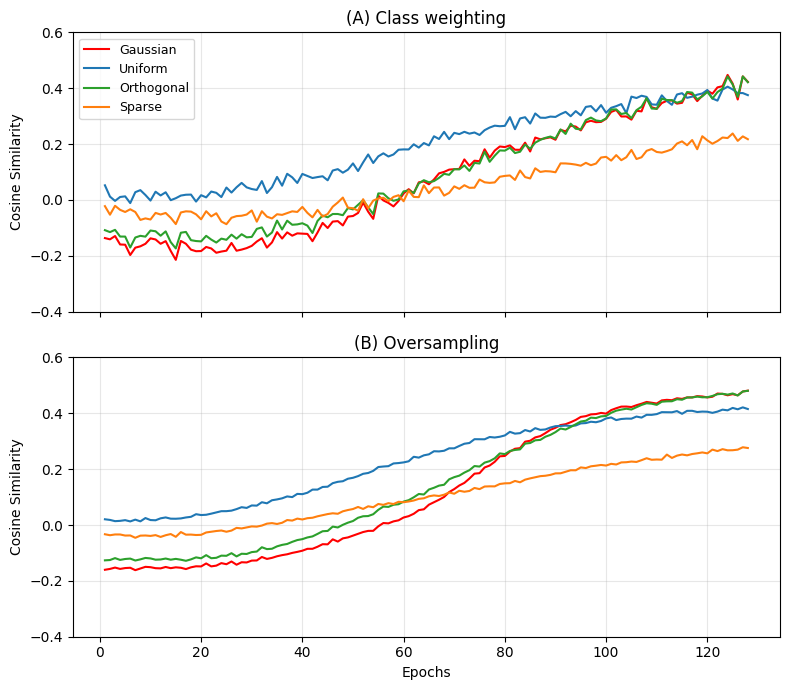

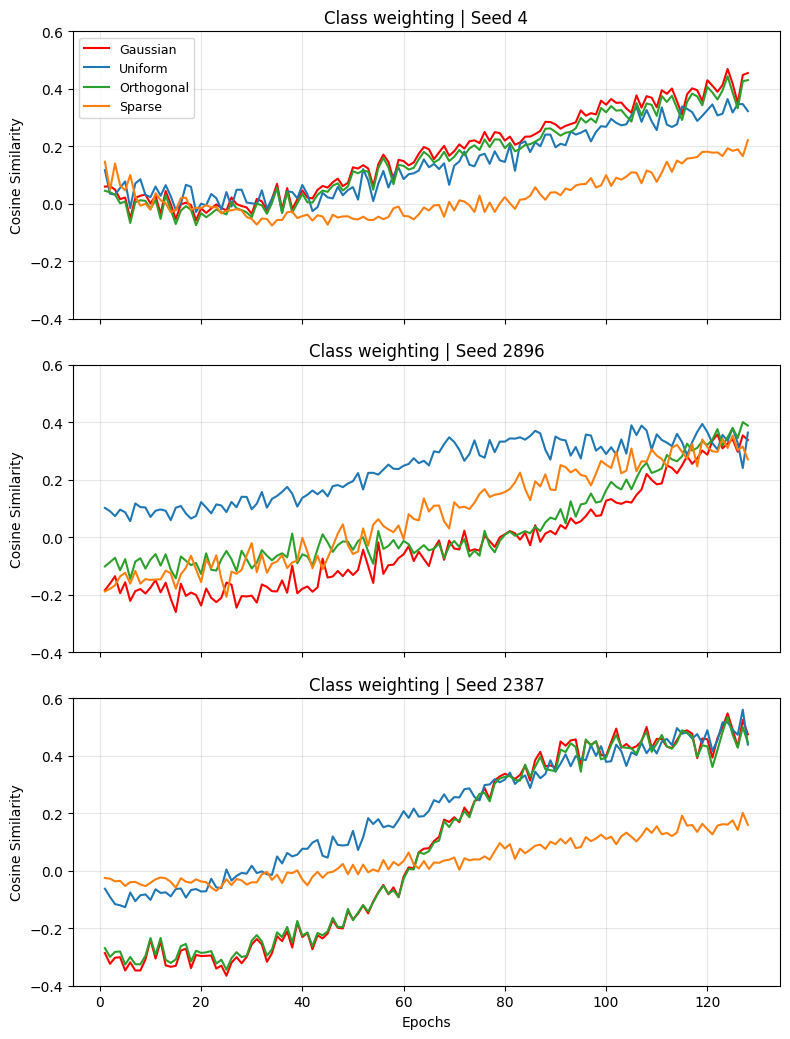

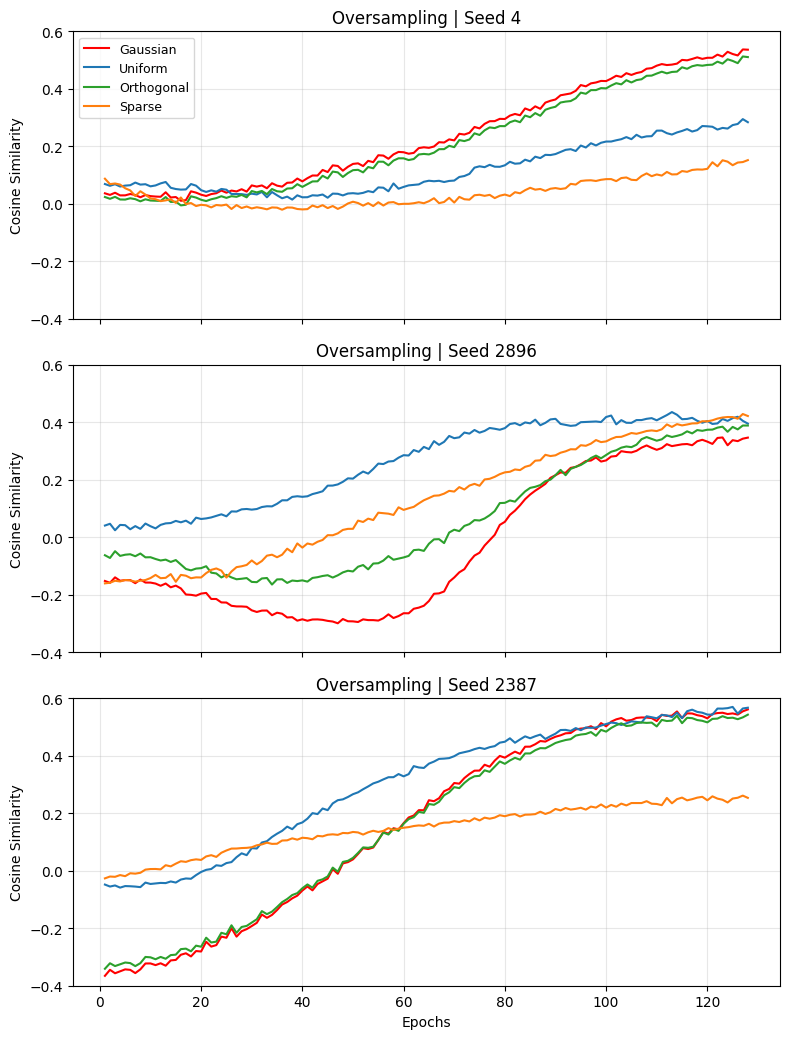

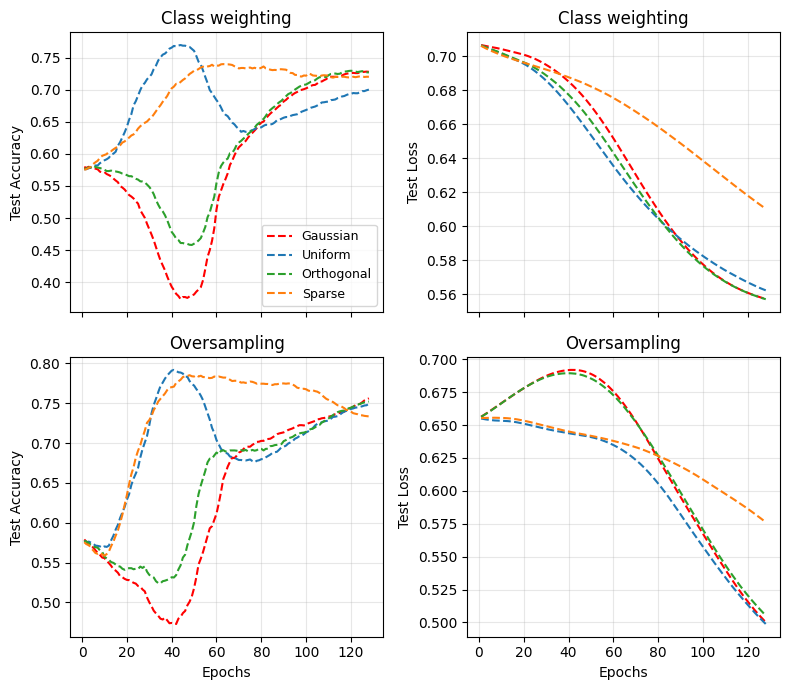

In [9]:
plt.rcdefaults()
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.titlesize": 12, "axes.labelsize": 10,
                     "legend.fontsize": 9, "lines.linewidth": 1.5,
                     "pdf.fonttype": 42})
colors = {"gaussian": "red", "uniform": "tab:blue", "orthogonal": "tab:green", "sparse": "tab:orange"}
mode_labels = {"class_weight": "Class weighting", "oversample": "Oversampling"}
epochs = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True, sharey=True)
for row, mode in enumerate(IMBALANCE_MODES):
    for init in FEEDBACK_INITS:
        curves = np.array([exp_results[init]["dfa"][mode]["base"][s]["results"]["hidden_gradient_cosines"] for s in SEEDS], dtype=float)
        axes[row].plot(epochs, np.nanmean(curves, axis=0), color=colors[init], label=init.title())
    axes[row].set_title(f"({chr(65+row)}) {mode_labels[mode]}")
    axes[row].set_ylabel("Cosine Similarity")
    axes[row].set_ylim(-0.4, 0.6)
    axes[row].grid(alpha=0.3)
axes[0].legend(loc="best")
axes[-1].set_xlabel("Epochs")
fig.tight_layout()
fig.savefig(RESULT_DIR / "plots" / "initialization_alignment.png", dpi=300)
fig.savefig(RESULT_DIR / "plots" / "initialization_alignment.pdf")
plt.show()

for mode in IMBALANCE_MODES:
    fig, axes = plt.subplots(3, 1, figsize=(8, 10.5), sharex=True, sharey=True)
    for ax, s in zip(axes, SEEDS):
        for init in FEEDBACK_INITS:
            curve = exp_results[init]["dfa"][mode]["base"][s]["results"]["hidden_gradient_cosines"]
            ax.plot(epochs, curve, color=colors[init], label=init.title())
        ax.set_title(f"{mode_labels[mode]} | Seed {s}")
        ax.set_ylabel("Cosine Similarity")
        ax.set_ylim(-0.4, 0.6)
        ax.grid(alpha=0.3)
    axes[0].legend(loc="best")
    axes[-1].set_xlabel("Epochs")
    fig.tight_layout()
    fig.savefig(RESULT_DIR / "plots" / f"initialization_seeds_{mode}.png", dpi=300)
    fig.savefig(RESULT_DIR / "plots" / f"initialization_seeds_{mode}.pdf")
    plt.show()

fig, axes = plt.subplots(2, 2, figsize=(8, 7), sharex=True)
for row, mode in enumerate(IMBALANCE_MODES):
    for col, (metric, ylabel) in enumerate([("test_accs", "Test Accuracy"), ("test_losses", "Test Loss")]):
        for init in FEEDBACK_INITS:
            curves = np.array([exp_results[init]["dfa"][mode]["base"][s]["results"][metric] for s in SEEDS])
            axes[row,col].plot(epochs, curves.mean(0), color=colors[init], linestyle="--", label=init.title())
        axes[row,col].set_title(mode_labels[mode])
        axes[row,col].set_ylabel(ylabel)
        axes[row,col].grid(alpha=0.3)
axes[0,0].legend(loc="best")
for ax in axes[-1]: ax.set_xlabel("Epochs")
fig.tight_layout()
fig.savefig(RESULT_DIR / "plots" / "initialization_learning.png", dpi=300)
fig.savefig(RESULT_DIR / "plots" / "initialization_learning.pdf")
plt.show()


In [10]:
feedback_rows = []
for feedback_init in FEEDBACK_INITS:
    for imbalance_mode in IMBALANCE_MODES:
        for model_name in MODEL_WIDTHS:
            for seed in SEEDS:
                for layer, d in enumerate(exp_results[feedback_init]["dfa"][imbalance_mode][model_name][seed]["results"]["feedback"]):
                    feedback_rows.append({"feedback_init": feedback_init, "imbalance_mode": imbalance_mode,
                        "model": model_name, "seed": seed, "layer": layer+1,
                        **{k:v for k,v in d.items() if k not in ["matrix", "shape", "singular_values"]}})
feedback_table = pd.DataFrame(feedback_rows)
feedback_table.to_csv(RESULT_DIR / "feedback_diagnostics.csv", index=False)
display(feedback_table.groupby("feedback_init")[["rank", "sparsity", "mean_square", "condition_number"]].agg(["min", "mean", "max"]))
print("Every output gradient matched true autograd to <1e-5 at every training step.")


rank               sparsity                  mean_square  \
               min      mean max      min      mean    max         min   
feedback_init                                                            
gaussian         2  2.000000   2  0.00000  0.000000  0.000    0.375850   
orthogonal       2  2.000000   2  0.00000  0.000000  0.000    0.500000   
sparse           1  1.972222   2  0.84375  0.849349  0.875    0.131671   
uniform          2  2.000000   2  0.00000  0.000000  0.000    0.359387   

                                  condition_number                        
                   mean       max              min      mean         max  
feedback_init                                                             
gaussian       0.556428  0.808842         1.057685  1.329514    1.540102  
orthogonal     0.500000  0.500000         1.000000  1.000000    1.000000  
sparse         0.579112  1.364035         1.132692  6.617046  125.912895  
uniform        0.483008  0.632382         1.035730  1.301408    2.059990

Every output gradient matched true autograd to <1e-5 at every training step.


## 8. Published linear result and what it predicts

Source: Lillicrap, Cownden, Tweed and Akerman (2016), *Random synaptic feedback weights support error backpropagation for deep learning*, [doi:10.1038/ncomms13276](https://doi.org/10.1038/ncomms13276), [published Supplementary Information](https://media.springernature.com/original/springer-static/esm/art%3A10.1038%2Fncomms13276/MediaObjects/41467_2016_BFncomms13276_MOESM954_ESM.pdf), Supplementary Note 11, pp. 22–26, equations (2)–(23). Note 12, pp. 27–28, discusses alignment through decoupled dynamics.

The following is an attributed restatement of the linear result and its algebra, not a new convergence theorem. In the paper's layer notation, let $A=W^{(1)}\in\mathbb{R}^{h\times d}$, $W=W^{(2)}\in\mathbb{R}^{o\times h}$, fixed $B\in\mathbb{R}^{h\times o}$, and $T\in\mathbb{R}^{o\times d}$. Here $o=2$, $h=32$, and $d=11$ includes a constant input. The source considers $y^*=Tx$, $y=WAx$, squared error, one linear hidden layer, no separate biases, an identity input second moment obtained there from i.i.d. standard normal inputs, infinite-batch averaging, equal infinitesimal learning rates, fixed full-column-rank $B$ ($B^+B=I_o$), and initial $AA^T=BW+W^TB^T$.

For $E=T-WA$, source equations (2)–(9) give

$$
\dot W=EA^T,\qquad \dot A=BE,\qquad \dot E=-EA^TA-WBE.
$$

Entrywise, $\dot W_{kj}=\sum_i E_{ki}A_{ji}$ and $\dot A_{ji}=\sum_k B_{jk}E_{ki}$. A second translation through indexed sums gives the same matrix equations and confirms their dimensions. Differentiating $C:=BW+W^TB^T-AA^T$ gives zero, since $BEA^T+AE^TB^T-BEA^T-AE^TB^T=0$. Thus $C=0$ remains zero for these continuous dynamics.

The source's Lyapunov quantity (15) is $V=\operatorname{tr}(BEE^TB^T)=\|BE\|_F^2\ge0$. Using cyclic permutation of the trace and $C=0$, equations (16)–(18) yield

$$
\dot V=-2\operatorname{tr}(BEA^TAE^TB^T)-\operatorname{tr}(A^TBEE^TB^TA)
=-2\|BEA^T\|_F^2-\|A^TBE\|_F^2\le0.
$$

The first squared norm is $\|BEA^T\|_F^2$, **not** $\|BEA^TA\|_F^2$. For $s=\|A\|_F^2$, source (19)–(20) gives $\dot s=2\langle BT,A\rangle_F-\|AA^T\|_F^2$. Consequently $\dot s\le2\|BT\|_F\sqrt{s}-s^2/h$, which is negative when $s>(2h\|BT\|_F)^{2/3}$; $A$ is bounded. This writes the source's boundedness argument using a valid trace inequality rather than reproducing its printed numerical bound.

Lillicrap et al. proceed through boundedness of $\ddot V$, Barbalat's lemma and a limiting argument to their Theorem 1 conclusion $E\to0$. Their terminal algebra uses $EA^T=0$, $BT E^TB^T=0$, full column rank of $B$, and $EE^T=ET^T-EA^TW^T=0$. This notebook attributes that conclusion to their theorem. It does not treat finite numerical trajectories or algebra checks as a new proof of all limiting steps.

Source-check qualifications: the supplement prints both signs for its constant $C$ and equation (10) disagrees with the definition immediately below it; the consistent definition above is used, and the theorem's $C=0$ case is unaffected. The text's claim that bounding $BW+W^TB^T$ alone bounds $BW$ needs additional justification, as does treating limiting matrices as fixed points without an established state limit. These are limitations of a literal proof transcription; numerical agreement cannot repair a proof gap. The notebook has one author's matrix and indexed checks, not an independent second-person proof review.

The theorem gives convergence under its assumptions and monotonic $V$, **not monotonic cosine similarity with BP**. Note 12's discussion of increasing $\operatorname{tr}(BW)$ in a decoupled construction is not a theorem about normalized gradient cosines under simultaneous training. Class balance is not an explicit assumption of Theorem 1. We therefore measure alignment reversals without asserting that any reversal contradicts it.

## 9. Stroke least squares and a continuous-flow reference

To keep the controlled study on stroke, use the original training observations and their actual one-hot labels $Y$. Balanced observation weights are $q_i=1/(2n_{y_i})$, with $\sum_iq_i=1$. Standardize using training statistics, append a constant input, and whiten the **uncentered second moment** under $q$, obtaining a matrix $Z$ with $Z^TQZ=I_d$. This is an exact finite-data second-moment construction, not a claim that stroke features are Gaussian.

For $T=Y^TQZ$ and $R=Y-ZT^T$, $R^TQZ=0$. The actual stroke squared loss decomposes exactly as

$$
\tfrac12\sum_i q_i\|WAz_i-y_i\|^2
=\tfrac12\|WA-T\|_F^2+\tfrac12\sum_iq_i\|R_i\|^2.
$$

Accordingly, the full-batch linear DFA dynamics on the original labels reduce to $\dot W=(T-WA)A^T$, $\dot A=B(T-WA)$. The label residual stays in the loss; it is not discarded, and zero clinical prediction error is not expected. This reduction follows from the empirical moment identities, rather than adding the source's Gaussian-input or realizable-label assumptions. It does not extend the published theorem to cross entropy or nonlinear models.

To satisfy $C=0$ with nonzero starting weights, draw a small $U\in\mathbb{R}^{o\times d}$ and set $A_0=BU$, $W_0=\tfrac12UU^TB^T$. Both are nonzero and $A_0A_0^T=BW_0+W_0^TB^T$. This avoids the degenerate zero-initialized ReLU control. The fixed Gaussian $B$ is checked for full column rank. A DOP853 integration of the reduced equations provides the continuous-flow reference for each existing seed. A second integration at tighter tolerances quantifies numerical error; it is not another initialization or another dataset.

In [11]:
from scipy.integrate import solve_ivp

control_scaler = StandardScaler().fit(X_train)
Z_raw = np.column_stack([control_scaler.transform(X_train), np.ones(len(X_train))])
Z_test_raw = np.column_stack([control_scaler.transform(X_test), np.ones(len(X_test))])
labels = y_train.to_numpy()
Y = np.eye(output_dim)[labels]
counts = np.bincount(labels)
q_balanced = 1 / (2 * counts[labels])
q_native = np.full(len(labels), 1 / len(labels))
second_moment = Z_raw.T @ (q_balanced[:, None] * Z_raw)
eigenvalues, eigenvectors = np.linalg.eigh(second_moment)
assert eigenvalues.min() > 1e-12, "Whitening requires full-rank empirical inputs"
whitening = (eigenvectors * eigenvalues**-0.5) @ eigenvectors.T
Z = Z_raw @ whitening
Z_test = Z_test_raw @ whitening
T = Y.T @ (q_balanced[:, None] * Z)
residual = Y - Z @ T.T
irreducible_loss = float(0.5 * np.sum(q_balanced[:, None] * residual**2))
identity_error = float(np.max(np.abs(Z.T @ (q_balanced[:, None] * Z) - np.eye(Z.shape[1]))))
orthogonality_error = float(np.max(np.abs(residual.T @ (q_balanced[:, None] * Z))))
assert identity_error < 1e-10 and orthogonality_error < 1e-10
print("Balanced mass:", [q_balanced[labels == k].sum() for k in range(2)])
print("Native class counts:", counts, "Second-moment error:", identity_error,
      "Residual orthogonality error:", orthogonality_error,
      "Irreducible weighted squared loss:", irreducible_loss)

control_initializations = {}
for seed in SEEDS:
    generator = torch.Generator(device=device).manual_seed(seed + 100000)
    B0 = initialize_feedback(32, 2, "gaussian", generator).cpu().numpy().astype(np.float64)
    U = np.random.default_rng(seed + 200000).normal(0, 0.05, size=(2, Z.shape[1]))
    A0 = B0 @ U
    W0 = 0.5 * U @ U.T @ B0.T
    assert np.linalg.matrix_rank(B0) == 2
    assert np.max(np.abs(B0@W0 + W0.T@B0.T - A0@A0.T)) < 1e-12
    control_initializations[seed] = (A0, W0, B0)
np.savez(RESULT_DIR / "control_data.npz", Z=Z, Z_test=Z_test, Y=Y,
         q_balanced=q_balanced, q_native=q_native, T=T, whitening=whitening,
         train_indices=X_train.index.to_numpy(), test_indices=X_test.index.to_numpy())


Balanced mass: [np.float64(0.5), np.float64(0.5)]
Native class counts: [3798  198] Second-moment error: 1.7763568394002505e-15 Residual orthogonality error: 9.419548474554063e-16 Irreducible weighted squared loss: 0.156413345737772


,seed,max_state_difference_tighter_solver,max_C_norm,max_invariant_derivative_error,max_lyapunov_identity_error,max_indexed_translation_error,V_increases_over_1e-8,initial_operator_error,final_operator_error,initial_V,final_V,final_stroke_loss
0,4,1.500331e-08,2.986215e-10,3.330669e-16,1.620622e-09,2.220446e-16,0,0.828422,2.241501e-11,13.583497,8.847682e-21,0.156413
1,2896,4.417381e-08,4.782107e-10,2.220446e-16,4.835695e-09,1.110223e-16,0,0.838547,1.159586e-09,14.086505,3.312903e-17,0.156413
2,2387,3.617245e-08,1.038288e-09,8.326673e-17,2.987107e-09,1.110223e-16,0,0.828006,1.167306e-10,8.164163,1.983365e-19,0.156413


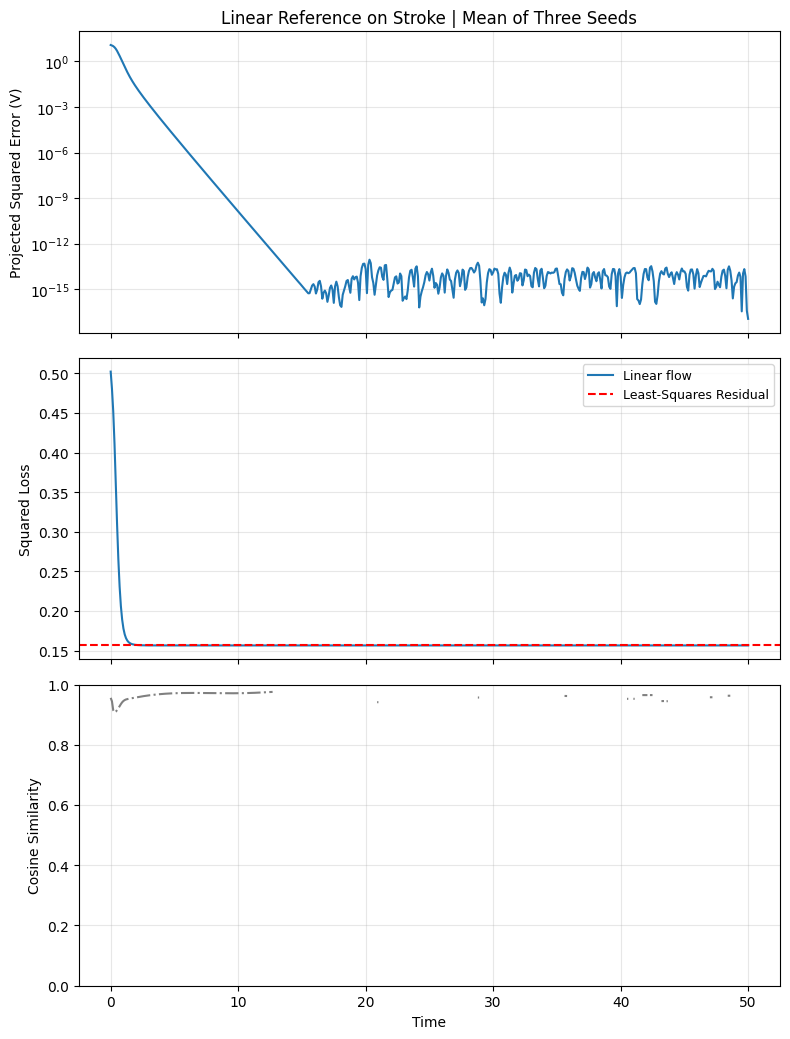

In [12]:
flow_results = {}
flow_checks = []
flow_times = np.linspace(0, 50, 501)
for seed in SEEDS:
    A0, W0, B0 = control_initializations[seed]
    a_size = A0.size
    def flow_rhs(t, state):
        A = state[:a_size].reshape(A0.shape)
        W = state[a_size:].reshape(W0.shape)
        E = T - W @ A
        return np.concatenate([(B0 @ E).ravel(), (E @ A.T).ravel()])
    initial_state = np.concatenate([A0.ravel(), W0.ravel()])
    solution = solve_ivp(flow_rhs, (0, 50), initial_state, method="DOP853",
                         t_eval=flow_times, rtol=1e-9, atol=1e-11)
    tighter = solve_ivp(flow_rhs, (0, 50), initial_state, method="DOP853",
                        t_eval=flow_times, rtol=1e-11, atol=1e-13)
    assert solution.success and tighter.success
    histories = {"time": flow_times.tolist(), "V": [], "dV": [], "C_norm": [],
                 "operator_error": [], "stroke_loss": [], "hidden_gradient_cosine": [], "fa_gradient_norm": [], "bp_gradient_norm": []}
    invariant_derivative_error, lyapunov_identity_error, indexed_translation_error = [], [], []
    for state in solution.y.T:
        A = state[:a_size].reshape(A0.shape)
        W = state[a_size:].reshape(W0.shape)
        E = T - W @ A
        dA, dW = B0 @ E, E @ A.T
        dE = -dW @ A - W @ dA
        # Independently compute the translated field with indexed contractions.
        dA_indexed = np.einsum("jk,ki->ji", B0, E)
        dW_indexed = np.einsum("ki,ji->kj", E, A)
        indexed_translation_error.append(max(np.max(np.abs(dA-dA_indexed)), np.max(np.abs(dW-dW_indexed))))
        invariant_derivative_error.append(np.max(np.abs(B0@dW+dW.T@B0.T-dA@A.T-A@dA.T)))
        derivative_direct = float(2 * np.sum((B0@E) * (B0@dE)))
        derivative_norms = float(-2*np.sum((B0@E@A.T)**2)-np.sum((A.T@B0@E)**2))
        lyapunov_identity_error.append(abs(derivative_direct-derivative_norms))
        gfa, gbp = B0 @ E, W.T @ E
        norm = np.linalg.norm(gfa) * np.linalg.norm(gbp)
        cosine = float(np.clip(np.sum(gfa*gbp)/norm,-1,1)) if norm > 1e-20 else None
        histories["V"].append(float(np.sum((B0@E)**2)))
        histories["dV"].append(derivative_direct)
        histories["C_norm"].append(float(np.linalg.norm(B0@W+W.T@B0.T-A@A.T)))
        histories["operator_error"].append(float(np.linalg.norm(E)))
        histories["stroke_loss"].append(float(0.5*np.sum(E**2)+irreducible_loss))
        histories["hidden_gradient_cosine"].append(cosine)
        histories["fa_gradient_norm"].append(float(np.linalg.norm(gfa)))
        histories["bp_gradient_norm"].append(float(np.linalg.norm(gbp)))
    flow_results[seed] = histories
    checks = {"seed": seed, "max_state_difference_tighter_solver": float(np.max(np.abs(solution.y-tighter.y))),
              "max_C_norm": max(histories["C_norm"]),
              "max_invariant_derivative_error": float(max(invariant_derivative_error)),
              "max_lyapunov_identity_error": float(max(lyapunov_identity_error)),
              "max_indexed_translation_error": float(max(indexed_translation_error)),
              "V_increases_over_1e-8": int(np.sum(np.diff(histories["V"]) > 1e-8)),
              "initial_operator_error": histories["operator_error"][0],
              "final_operator_error": histories["operator_error"][-1],
              "initial_V": histories["V"][0], "final_V": histories["V"][-1],
              "final_stroke_loss": histories["stroke_loss"][-1]}
    flow_checks.append(checks)
    np.savez(RESULT_DIR / f"flow_states_{seed}.npz", times=flow_times, states=solution.y,
             tighter_states=tighter.y, A0=A0, W0=W0, B=B0)
flow_check_table = pd.DataFrame(flow_checks)
flow_check_table.to_csv(RESULT_DIR / "flow_checks.csv", index=False)
with open(RESULT_DIR / "flow_results.json", "w") as f: json.dump(flow_results, f, indent=2, allow_nan=False)
display(flow_check_table)
fig, axes = plt.subplots(3, 1, figsize=(8, 10.5), sharex=True)
for ax, metric, ylabel in zip(axes, ["V", "stroke_loss", "hidden_gradient_cosine"],
                            ["Projected Squared Error (V)", "Squared Loss", "Cosine Similarity"]):
    curves = np.array([flow_results[s][metric] for s in SEEDS], dtype=float)
    if metric == "hidden_gradient_cosine":
        valid = np.ones(len(flow_times), dtype=bool)
        for seed in SEEDS:
            h = flow_results[seed]
            fa, bp = np.array(h["fa_gradient_norm"]), np.array(h["bp_gradient_norm"])
            valid &= (fa > fa[0]*1e-8) & (bp > bp[0]*1e-8)
        curves[:,~valid] = np.nan
    mean = np.mean(curves, axis=0)
    ax.plot(flow_times, mean, color="gray" if metric == "hidden_gradient_cosine" else "tab:blue",
            linestyle="-." if metric == "hidden_gradient_cosine" else "-", label="Linear flow")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
axes[0].set_yscale("log")
axes[0].set_title("Linear Reference on Stroke | Mean of Three Seeds")
axes[1].axhline(irreducible_loss, color="red", linestyle="--", label="Least-Squares Residual")
axes[1].legend(loc="best")
axes[2].set_ylim(0,1)
axes[-1].set_xlabel("Time")
fig.tight_layout()
fig.savefig(RESULT_DIR / "plots" / "linear_flow_reference.png",dpi=300)
fig.savefig(RESULT_DIR / "plots" / "linear_flow_reference.pdf")
plt.show()


## 10. One-factor controls on the same stroke observations

The baseline is a single linear hidden layer, weighted squared loss with balanced class mass, no dropout, no separate biases and full-batch GD. Starting from the same $A_0,W_0,B$, change one factor per condition:

| Condition | Hidden layers | Activation | Class mass in loss | Optimizer |
|---|---:|---|---|---|
| baseline | 1 | linear | 50/50 | GD |
| depth | 2 | linear | 50/50 | GD |
| relu | 1 | ReLU | 50/50 | GD |
| imbalance | 1 | linear | native prevalence | GD |
| adam | 1 | linear | 50/50 | Adam |

The additional depth layer starts at identity, giving exactly the same initial linear prediction function. Both hidden layers receive the same fixed $B$, so extra feedback randomness is not introduced. ReLU changes the initial function as an inherent consequence of changing the activation. Native prevalence changes observation weights, keeping the same data, whitening and starting weights. This isolates the effect of training class mass; it does not isolate every mechanism of rare-class learning. Both optimizers use learning rate 0.01 for 2,048 updates, fixed before examining outcomes; no optimizer-specific retuning is performed.

GD is a finite Euler discretization and does not exactly preserve the gradient-flow invariant. Its $C$ drift and learning curves are recorded. These controls use squared loss to retain a direct relationship to the published linear setting, whereas the full initialization grid uses the original cross entropy, ReLU, dropout and Adam. Isolated effects in this controlled system do not establish which interaction causes instability in the full clinical MLP.

The control alignment figures compare the **first hidden layer** in every condition. This keeps the parameter block comparable when the depth control adds a second layer. Concatenated all-hidden-layer cosines and per-layer cosines remain in the raw histories. Figures show unsmoothed means over the three seeds; individual seed summaries quantify decreases rather than relying on how smooth a mean curve appears.

Cosines divide by gradient norms and are undefined at zero gradient. For the controlled plots and reversal summaries, epochs are retained only while both the total DFA gradient norm and BP hidden gradient norm exceed $10^{-8}$ of their respective initial values. Raw cosines and norms are retained. Means are plotted only where all three seeds meet the criterion, avoiding changes in which seeds contribute to the mean; truncated lines do not indicate early stopping. The flow cosine uses the analogous threshold on the actual hidden-gradient norms. Loss histories always include every update.

In [13]:
CONTROL_CONDITIONS = ["baseline", "depth", "relu", "imbalance", "adam"]
CONTROL_EPOCHS = 2048
CONTROL_LR = 0.01
Z_tensor = torch.tensor(Z, dtype=torch.float64, device=device)
Z_test_tensor = torch.tensor(Z_test, dtype=torch.float64, device=device)
Y_tensor = torch.tensor(Y, dtype=torch.float64, device=device)


def train_controlled_dfa(condition, seed):
    set_seed(seed)
    A0, W0, B0 = control_initializations[seed]
    dims = [Z.shape[1], 32, 32, 2] if condition == "depth" else [Z.shape[1], 32, 2]
    model = MLP(dims, learning_rule="dfa").to(device=device, dtype=torch.float64)
    # Retain the existing MLP container, replacing only the specified control components.
    for i, layer in enumerate(model.net):
        if isinstance(layer, nn.Linear): layer.register_parameter("bias", None)
        elif isinstance(layer, nn.Dropout): model.net[i] = nn.Identity()
        elif isinstance(layer, nn.ReLU) and condition != "relu": model.net[i] = nn.Identity()
    layers = model.linear_layers
    with torch.no_grad():
        layers[0].weight.copy_(torch.tensor(A0,device=device))
        layers[-1].weight.copy_(torch.tensor(W0,device=device))
        if condition == "depth": layers[1].weight.copy_(torch.eye(32,dtype=torch.float64,device=device))
    feedback = torch.tensor(B0, dtype=torch.float64, device=device)
    q = torch.tensor(q_native if condition == "imbalance" else q_balanced, dtype=torch.float64, device=device)
    optimizer = optim.Adam(model.parameters(), lr=CONTROL_LR) if condition == "adam" else optim.SGD(model.parameters(), lr=CONTROL_LR)
    histories = {"train_losses": [], "test_losses": [], "train_accs": [], "test_accs": [],
                 "hidden_gradient_cosines": [], "layer_gradient_cosines": [],
                 "gradient_norms": [], "bp_hidden_gradient_norms": [], "C_norm": [],
                 "output_gradient_max_errors": []}
    start = perf_counter()
    for epoch in range(CONTROL_EPOCHS):
        model.train()
        optimizer.zero_grad()
        activations, gates = [Z_tensor], []
        for l, layer in enumerate(layers):
            z = layer(activations[-1])
            if l < len(layers)-1:
                activations.append(torch.relu(z) if condition == "relu" else z)
                gates.append((z>0).to(z.dtype) if condition == "relu" else torch.ones_like(z))
            else:
                activations.append(z)
        outputs = activations[-1]
        loss = 0.5 * (q[:,None] * (outputs-Y_tensor).square()).sum()
        bp_grads = torch.autograd.grad(loss, tuple(model.parameters()))
        with torch.no_grad():
            delta_L = q[:,None] * (outputs-Y_tensor)
            deltas = [delta_L @ feedback.T * gate for gate in gates] + [delta_L]
            dfa_grads = [delta.T @ activation for delta, activation in zip(deltas, activations[:-1])]
            output_error = float((dfa_grads[-1]-bp_grads[-1]).abs().max().item())
            assert output_error < 1e-10
            histories["output_gradient_max_errors"].append(output_error)
            histories["hidden_gradient_cosines"].append(gradient_cosine(dfa_grads[:-1],bp_grads[:-1]))
            histories["layer_gradient_cosines"].append([gradient_cosine([a],[b]) for a,b in zip(dfa_grads[:-1],bp_grads[:-1])])
            histories["gradient_norms"].append(float(torch.sqrt(sum(g.square().sum() for g in dfa_grads)).item()))
            histories["bp_hidden_gradient_norms"].append(float(torch.sqrt(sum(g.square().sum() for g in bp_grads[:-1])).item()))
            if condition != "depth":
                A, W = layers[0].weight, layers[-1].weight
                histories["C_norm"].append(float((feedback@W+W.T@feedback.T-A@A.T).norm().item()))
            for layer, grad in zip(layers, dfa_grads): layer.weight.grad = grad
            assert np.isfinite(loss.item()), f"Nonfinite loss: {condition}, seed {seed}, epoch {epoch}"
            histories["train_losses"].append(loss.item())
            histories["train_accs"].append(float((outputs.argmax(1).cpu().numpy()==labels).mean()))
            optimizer.step()
            model.eval()
            test_out = model(Z_test_tensor)
            targets_test = torch.nn.functional.one_hot(torch.tensor(y_test.to_numpy(),device=device),2)
            histories["test_losses"].append(float((0.5 * (test_out-targets_test).square().sum(1)).mean().item()))
            histories["test_accs"].append(float((test_out.argmax(1).cpu().numpy()==y_test.to_numpy()).mean()))
    if device.type == "cuda": torch.cuda.synchronize()
    histories["training time"] = perf_counter()-start
    torch.save({"dims":dims,"state_dict":model.state_dict(),"feedback":feedback.cpu(),
                "condition":condition,"seed":seed},RESULT_DIR/"models"/f"controlled_{condition}_{seed}.pt")
    print(f"{condition}, seed={seed}: loss {histories['train_losses'][-1]:.6f}, test accuracy {histories['test_accs'][-1]:.4f}")
    return histories


In [19]:
controlled_results = {}
for condition in CONTROL_CONDITIONS:
    controlled_results[condition] = {}
    for seed in SEEDS:
        controlled_results[condition][seed] = train_controlled_dfa(condition, seed)
        with open(RESULT_DIR / "controlled_results.json", "w") as f:
            json.dump(controlled_results, f, indent=2, allow_nan=False)
print("All 15 stroke one-factor controlled runs are complete.")


baseline, seed=4: loss 0.156413, test accuracy 0.7417


baseline, seed=2896: loss 0.156413, test accuracy 0.7417


baseline, seed=2387: loss 0.156413, test accuracy 0.7417


depth, seed=4: loss 0.156413, test accuracy 0.7417


depth, seed=2896: loss 0.156413, test accuracy 0.7417


...

imbalance, seed=2387: loss 0.043144, test accuracy 0.9499


adam, seed=4: loss 0.156417, test accuracy 0.7417


adam, seed=2896: loss 0.156413, test accuracy 0.7417


adam, seed=2387: loss 0.156413, test accuracy 0.7417


All 15 stroke one-factor controlled runs are complete.


,condition,seed,initial_loss,final_loss,final_test_accuracy,initial_cosine,last_valid_cosine,last_valid_epoch,valid_epochs,raw_final_cosine,all_hidden_final_cosine,cosine_decreases_gt_1e-6,largest_cosine_drop,cosine_total_variation,negative_cosine_epochs,max_C_norm
0,baseline,4,0.499555,0.156413,0.741742,0.993543,0.940511,1269,1269,0.926077,0.926077,601,0.009691,0.282312,0,0.045021
1,baseline,2896,0.507994,0.156413,0.741742,0.958940,0.993558,1497,1497,0.993566,0.993566,24,0.002282,0.101466,0,0.054247
2,baseline,2387,0.499211,0.156413,0.741742,0.914704,0.991942,1559,1559,0.990766,0.990766,490,0.001546,0.116017,0,0.034395
3,depth,4,0.499555,0.156413,0.741742,0.993543,0.891689,1037,1037,0.890068,0.888487,565,0.014696,0.432450,0,NaN
4,depth,2896,0.507994,0.156413,0.741742,0.958940,0.998074,1191,1191,0.998046,0.997944,48,0.003506,0.158002,0,NaN
5,depth,2387,0.499211,0.156413,0.741742,0.914704,0.958367,1257,1257,0.954225,0.954223,704,0.003450,0.163897,0,NaN
6,relu,4,0.506455,0.153283,0.728729,0.992359,0.598990,2048,2048,0.598990,0.598990,1126,0.099225,26.305849,0,2.620542
7,relu,2896,0.499008,0.153762,0.746747,0.957714,0.650002,2048,2048,0.650002,0.650002,1165,0.039566,11.346767,0,2.235303
8,relu,2387,0.499650,0.153773,0.734735,0.914918,0.694483,2048,2048,0.694483,0.694483,1039,0.052857,15.089901,0,1.632824
9,imbalance,4,0.493930,0.043144,0.949950,0.987433,0.787899,2048,2048,0.787899,0.787899,248,0.006494,0.843382,0,0.052299


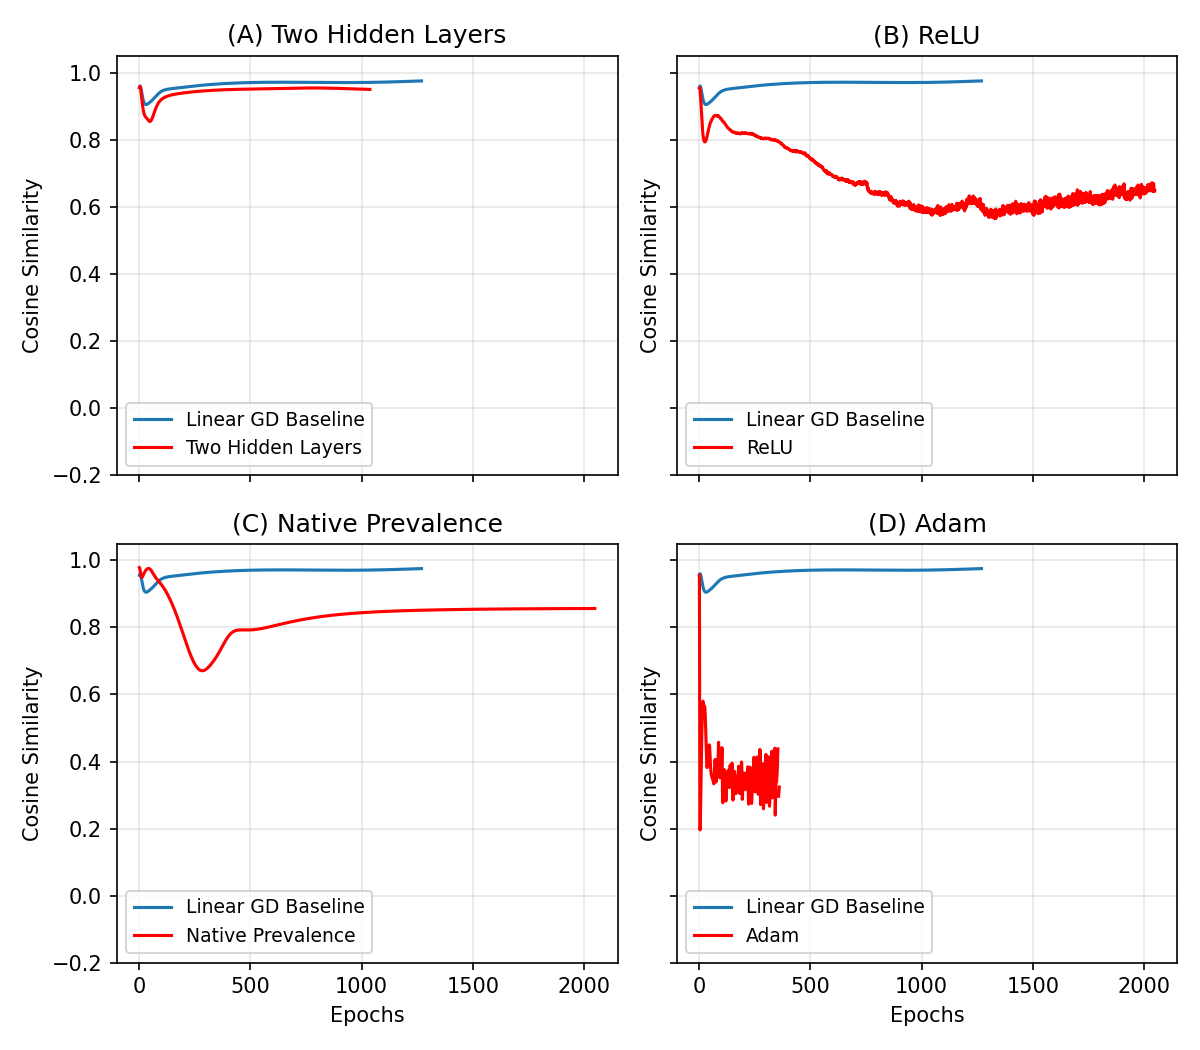

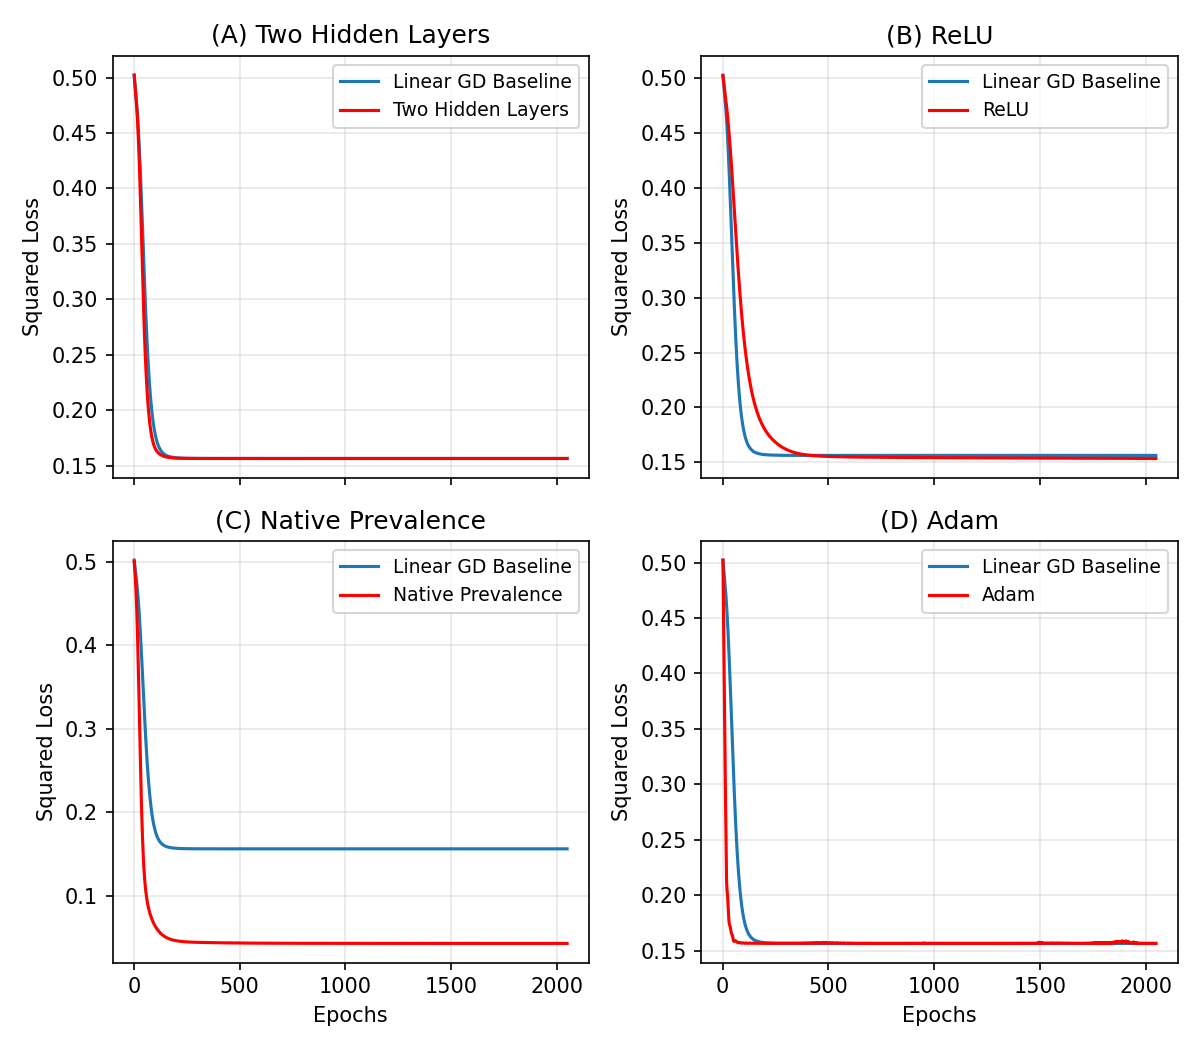

In [14]:
with open(RESULT_DIR / "controlled_results.json") as f:
    controlled_results = json.load(f)
for condition in CONTROL_CONDITIONS:
    controlled_results[condition] = {int(s):r for s,r in controlled_results[condition].items()}

ALIGNMENT_RELATIVE_FLOOR = 1e-8
control_alignment = {}
control_rows = []
for condition in CONTROL_CONDITIONS:
    for seed in SEEDS:
        r = controlled_results[condition][seed]
        curve = np.array([v[0] for v in r["layer_gradient_cosines"]],dtype=float)
        dfa_norm = np.array(r["gradient_norms"])
        bp_norm = np.array(r["bp_hidden_gradient_norms"])
        valid = (dfa_norm > dfa_norm[0]*ALIGNMENT_RELATIVE_FLOOR) & (bp_norm > bp_norm[0]*ALIGNMENT_RELATIVE_FLOOR)
        differences = np.diff(curve)
        valid_pairs = valid[:-1] & valid[1:]
        valid_differences = differences[valid_pairs]
        control_alignment[(condition,seed)] = np.where(valid,curve,np.nan)
        last_valid = np.flatnonzero(valid)[-1]
        control_rows.append({"condition":condition,"seed":seed,
            "initial_loss":r["train_losses"][0],"final_loss":r["train_losses"][-1],
            "final_test_accuracy":r["test_accs"][-1],
            "initial_cosine":curve[0],"last_valid_cosine":curve[last_valid],
            "last_valid_epoch":int(last_valid+1),"valid_epochs":int(valid.sum()),
            "raw_final_cosine":curve[-1],
            "all_hidden_final_cosine":r["hidden_gradient_cosines"][-1],
            "cosine_decreases_gt_1e-6":int(np.sum(valid_differences < -1e-6)),
            "largest_cosine_drop":float(max(0,-np.nanmin(valid_differences))),
            "cosine_total_variation":float(np.nansum(np.abs(valid_differences))),
            "negative_cosine_epochs":int(np.sum((curve<0)&valid)),
            "max_C_norm":max(r["C_norm"]) if r["C_norm"] else None})
control_summary = pd.DataFrame(control_rows)
control_summary.to_csv(RESULT_DIR / "controlled_summary.csv", index=False)
display(control_summary.round(7))

condition_labels = {"depth": "Two Hidden Layers", "relu": "ReLU", "imbalance": "Native Prevalence", "adam": "Adam"}
updates = np.arange(1, CONTROL_EPOCHS + 1)
fig, axes = plt.subplots(2, 2, figsize=(8, 7), sharex=True, sharey=True)
axes = axes.flatten()
for i, (ax, condition) in enumerate(zip(axes, CONTROL_CONDITIONS[1:])):
    for name, color, label in [("baseline", "tab:blue", "Linear GD Baseline"), (condition, "red", condition_labels[condition])]:
        curves = np.array([control_alignment[(name,s)] for s in SEEDS], dtype=float)
        # Keep a constant three-seed mean: no changes in the number of contributing seeds.
        ax.plot(updates, np.mean(curves,axis=0), color=color, label=label)
    ax.set_title(f"({chr(65+i)}) {condition_labels[condition]}")
    ax.set_ylabel("Cosine Similarity")
    ax.set_ylim(-0.2,1.05)
    ax.legend(loc="best")
    ax.grid(alpha=0.3)
for ax in axes[-2:]: ax.set_xlabel("Epochs")
fig.tight_layout()
fig.savefig(RESULT_DIR/"plots"/"controlled_alignment.png",dpi=300)
fig.savefig(RESULT_DIR/"plots"/"controlled_alignment.pdf")
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(8,7), sharex=True)
axes = axes.flatten()
for i,(ax,condition) in enumerate(zip(axes, CONTROL_CONDITIONS[1:])):
    for name,color,label in [("baseline","tab:blue","Linear GD Baseline"),(condition,"red",condition_labels[condition])]:
        curves=np.array([controlled_results[name][s]["train_losses"] for s in SEEDS])
        ax.plot(updates,curves.mean(0),color=color,label=label)
    ax.set_title(f"({chr(65+i)}) {condition_labels[condition]}")
    ax.set_ylabel("Squared Loss")
    ax.legend(loc="best")
    ax.grid(alpha=0.3)
for ax in axes[-2:]: ax.set_xlabel("Epochs")
fig.tight_layout()
fig.savefig(RESULT_DIR/"plots"/"controlled_losses.png",dpi=300)
fig.savefig(RESULT_DIR/"plots"/"controlled_losses.pdf")
plt.show()


## 11. Completed-run audit

The checks below verify coverage of the prescribed grid, complete histories, finite metrics and saved artifacts. They use the actual completed experiments and do not replace any experiment with a smaller run. Sections 14–18 interpret the completed runs and the saved numerical results.

In [15]:
assert len(run_metrics) == 144
assert len(control_summary) == 15
assert len(flow_check_table) == 3
assert np.isfinite(run_metrics[metric_names].to_numpy()).all()
for init in FEEDBACK_INITS:
    for mode in IMBALANCE_MODES:
        for name in MODEL_WIDTHS:
            for s in SEEDS:
                r=exp_results[init]["dfa"][mode][name][s]["results"]
                assert len(r["train_losses"]) == EPOCHS
                assert len(r["hidden_gradient_cosines"]) == EPOCHS
                assert all(np.isfinite(r[k]).all() for k in ["train_losses","test_losses","train_accs","test_accs"])
for condition in CONTROL_CONDITIONS:
    for s in SEEDS:
        assert len(controlled_results[condition][s]["train_losses"]) == CONTROL_EPOCHS
print("Completed: 144 initialization runs; 15 one-factor controls; 3 continuous-flow references with tighter integrations.")
print("Saved raw results, predictions, model states, statistics and figures:",RESULT_DIR.resolve())


Completed: 144 initialization runs; 15 one-factor controls; 3 continuous-flow references with tighter integrations.
Saved raw results, predictions, model states, statistics and figures: C:\Users\89\Desktop\DFA\code\reviewer7_results


## 12. Class-specific interpretation of the controlled models

The controlled models minimize squared loss, so their raw two-dimensional outputs are not reported as calibrated stroke probabilities. The following evaluation uses argmax predictions and the output difference for ROC-AUC, directly from the saved final checkpoints. It verifies the class-specific behavior behind accuracy, without fitting another model or using another dataset.

In [5]:
control_data = np.load(RESULT_DIR / "control_data.npz")
Z_probe = torch.tensor(control_data["Z_test"],dtype=torch.float64)
y_probe = y.loc[control_data["test_indices"]].to_numpy()
saved_controls = json.loads((RESULT_DIR / "controlled_results.json").read_text())
control_classification_rows = []
for condition in ["baseline", "depth", "relu", "imbalance", "adam"]:
    for seed in SEEDS:
        checkpoint = torch.load(RESULT_DIR / "models" / f"controlled_{condition}_{seed}.pt",map_location="cpu",weights_only=True)
        state = checkpoint["state_dict"]
        keys = sorted(state, key=lambda k:int(k.split(".")[1]))
        outputs = Z_probe.clone()
        for layer, key in enumerate(keys):
            outputs = outputs @ state[key].T
            if condition == "relu" and layer < len(keys)-1: outputs = torch.relu(outputs)
        predictions = outputs.argmax(1).numpy()
        scores = (outputs[:,1]-outputs[:,0]).numpy()
        accuracy = accuracy_score(y_probe,predictions)
        saved = saved_controls[condition][str(seed)]["test_accs"][-1]
        assert abs(accuracy-saved)<1e-12
        report = classification_report(y_probe,predictions,output_dict=True,zero_division=0)
        control_classification_rows.append({"condition":condition,"seed":seed,"accuracy":accuracy,
            "f1_macro":f1_score(y_probe,predictions,average="macro"),"roc_auc":roc_auc_score(y_probe,scores),
            "stroke_precision":report["1"]["precision"],"stroke_recall":report["1"]["recall"],
            "predicted_stroke_cases":int(predictions.sum())})
control_classification = pd.DataFrame(control_classification_rows)
control_classification.to_csv(RESULT_DIR / "controlled_classification.csv",index=False)
display(control_classification.groupby("condition").mean(numeric_only=True).drop(columns="seed").round(6))


,accuracy,f1_macro,roc_auc,stroke_precision,stroke_recall,predicted_stroke_cases
condition,,,,,,
adam,0.741742,0.536248,0.817373,0.133803,0.760000,284.000000
baseline,0.741742,0.536248,0.817366,0.133803,0.760000,284.000000
depth,0.741742,0.536248,0.817366,0.133803,0.760000,284.000000
imbalance,0.949950,0.487166,0.816024,0.000000,0.000000,0.000000
relu,0.736737,0.533617,0.820344,0.132440,0.766667,289.666667


## 13. Feedback coverage in binary cross entropy

In binary softmax cross entropy the two output-error components sum to zero: $\delta_L=(-u,u)$. Thus the hidden feedback is $u(B_{:,1}-B_{:,0})$. Full matrix rank alone does not describe how feedback acts on this one-dimensional error subspace. A row with both entries zero provides no feedback to that hidden unit at any epoch. With the current Adam settings (no weight decay), its incoming weights and bias receive zero DFA gradients and stay at their initial values. This is a direct consequence of the training equation, although it does not isolate all causes of a performance difference. The following table measures coverage from the actual saved feedback matrices; it does not assume that entry sparsity equals hidden-unit sparsity.

In [6]:
with open(RESULT_DIR / "exp_results.json") as f:
    recorded_experiments = json.load(f)
coverage_rows = []
for init, conditions in recorded_experiments.items():
    for mode, architectures in conditions["dfa"].items():
        for model_name, seeds in architectures.items():
            for seed, run in seeds.items():
                for layer, diagnostic in enumerate(run["results"]["feedback"]):
                    B = np.array(diagnostic["matrix"])
                    contrast = B[:,1]-B[:,0]
                    coverage_rows.append({"feedback_init":init,"imbalance_mode":mode,"model":model_name,
                        "seed":int(seed),"layer":layer+1,"zero_feedback_row_fraction":float(np.mean(np.all(B==0,axis=1))),
                        "zero_contrast_fraction":float(np.mean(contrast==0)),
                        "contrast_mean_square":float(np.mean(contrast**2))})
coverage_table = pd.DataFrame(coverage_rows)
coverage_table.to_csv(RESULT_DIR / "feedback_coverage.csv",index=False)
display(coverage_table.groupby("feedback_init")[["zero_feedback_row_fraction","zero_contrast_fraction","contrast_mean_square"]].agg(["min","mean","max"]).round(6))


zero_feedback_row_fraction                    \
                                     min      mean     max   
feedback_init                                                
gaussian                          0.0000  0.000000  0.0000   
orthogonal                        0.0000  0.000000  0.0000   
sparse                            0.6875  0.720399  0.8125   
uniform                           0.0000  0.000000  0.0000   

              zero_contrast_fraction                   contrast_mean_square  \
                                 min      mean     max                  min   
feedback_init                                                                 
gaussian                      0.0000  0.000000  0.0000             0.694531   
orthogonal                    0.0000  0.000000  0.0000             1.000000   
sparse                        0.6875  0.720399  0.8125             0.263342   
uniform                       0.0000  0.000000  0.0000             0.461010   

                                   
                   mean       max  
feedback_init                      
gaussian       1.002146  1.336812  
orthogonal     1.000000  1.000000  
sparse         1.196786  2.728069  
uniform        0.901782  1.198921

## 14. Observed initialization sensitivity

All 144 prescribed stroke initialization runs completed for 128 updates each. Each distribution has 18 architecture–seed pairs per imbalance method. The following values are means ± population SD across those 18 runs; the SD combines variation across architectures and seeds and is not a standard error. Higher accuracy, F1 and ROC-AUC are preferable; lower Brier and ECE are preferable.

### Class weighting

| Initialization | Accuracy | Macro F1 | ROC-AUC | Brier | ECE |
|---|---:|---:|---:|---:|---:|
| Gaussian | 0.6838 ± 0.0710 | 0.4988 ± 0.0402 | 0.7974 ± 0.0178 | 0.2002 ± 0.0274 | 0.3620 ± 0.0554 |
| Uniform | 0.6695 ± 0.1553 | 0.4862 ± 0.1083 | 0.7937 ± 0.0244 | 0.1992 ± 0.0366 | 0.3554 ± 0.0618 |
| Orthogonal | 0.6646 ± 0.1474 | 0.4838 ± 0.0994 | 0.7970 ± 0.0193 | 0.2015 ± 0.0337 | 0.3628 ± 0.0608 |
| Sparse | 0.6342 ± 0.1673 | 0.4643 ± 0.1029 | 0.7628 ± 0.0516 | 0.2205 ± 0.0332 | 0.4037 ± 0.0577 |

### Oversampling

| Initialization | Accuracy | Macro F1 | ROC-AUC | Brier | ECE |
|---|---:|---:|---:|---:|---:|
| Gaussian | 0.7272 ± 0.0773 | 0.5133 ± 0.0439 | 0.7457 ± 0.0292 | 0.1782 ± 0.0369 | 0.3189 ± 0.0816 |
| Uniform | 0.7194 ± 0.1657 | 0.5034 ± 0.1124 | 0.7486 ± 0.0355 | 0.1733 ± 0.0446 | 0.3064 ± 0.0848 |
| Orthogonal | 0.7049 ± 0.1604 | 0.4971 ± 0.1052 | 0.7455 ± 0.0324 | 0.1801 ± 0.0430 | 0.3202 ± 0.0873 |
| Sparse | 0.6639 ± 0.1502 | 0.4741 ± 0.0854 | 0.7107 ± 0.0678 | 0.2078 ± 0.0412 | 0.3815 ± 0.0790 |

Gaussian had the highest mean accuracy and macro F1 under both imbalance methods. Orthogonal had nearly the same mean ROC-AUC as Gaussian, but greater variation in accuracy across the grid. Uniform's mean calibration errors were slightly lower than Gaussian's. None of the Uniform or Orthogonal comparisons rejected the null after Holm correction; this does not establish equivalence or initialization independence.

Sparse feedback had lower mean ROC-AUC and higher Brier/ECE than Gaussian in both modes. These six differences remained significant under the stated paired Wilcoxon/Holm procedure. Accuracy and macro-F1 differences did not remain significant after correction. In particular, the unadjusted bootstrap interval for sparse oversampling accuracy excludes zero, whereas the Holm-adjusted Wilcoxon result does not reject; the interval and adjusted test are different procedures with different multiplicity treatment.


### Paired evidence and scope

| Handling | Metric | Sparse minus Gaussian | Unadjusted 95% bootstrap CI | Holm p |
|---|---|---:|---:|---:|
| Class weighting | ROC-AUC | -0.034511 | [-0.053851, -0.017932] | 0.001717 |
| Class weighting | Brier | +0.020302 | [+0.011781, +0.029209] | 0.001640 |
| Class weighting | ECE | +0.041755 | [+0.029217, +0.054766] | 0.000229 |
| Oversampling | ROC-AUC | -0.034997 | [-0.060313, -0.014311] | 0.025269 |
| Oversampling | Brier | +0.029643 | [+0.018562, +0.042597] | 0.000725 |
| Oversampling | ECE | +0.062637 | [+0.044833, +0.082710] | 0.000092 |

Pairing holds architecture, seed, split, forward initialization and dropout random sequence fixed; only feedback construction changes. The 18 pairs share the same patients and reuse three seeds across architectures. The reported tests reproduce the manuscript's architecture–seed pairing, rather than providing 18 independent clinical datasets or 18 independently sampled seeds. Their conclusions concern this fixed split and grid. A confidence interval for population-level clinical performance would require a different sampling design.

The Gaussian values here are a fresh baseline. They include the corrected dropout forward and weighted cross-entropy normalization and therefore should not be substituted silently into the archived BP–DFA tables. The calibration slope and intercept retain the existing L2-regularized logistic regression estimator; they are descriptive diagnostics rather than unpenalized maximum-likelihood calibration coefficients.


## 15. Alignment and the sparse feedback mechanism

The Base model's mean hidden-gradient cosine increased between the first and last epoch for every distribution. Gaussian and Orthogonal followed similar trajectories and ended with higher mean cosine than Uniform or Sparse. Uniform started with a more favorable mean angle but ended below Gaussian; an earlier positive cosine alone therefore does not establish superior learning. The trajectories are unsmoothed and are not monotonic. With dropout active, fluctuations include mask variation as well as parameter evolution.

| Handling | Initialization | Epoch 1 cosine | Epoch 128 cosine |
|---|---|---:|---:|
| Class weighting | Gaussian | -0.1367 | 0.4226 |
| Class weighting | Uniform | 0.0523 | 0.3751 |
| Class weighting | Orthogonal | -0.1084 | 0.4213 |
| Class weighting | Sparse | -0.0224 | 0.2173 |
| Oversampling | Gaussian | -0.1603 | 0.4811 |
| Oversampling | Uniform | 0.0205 | 0.4153 |
| Oversampling | Orthogonal | -0.1265 | 0.4805 |
| Oversampling | Sparse | -0.0331 | 0.2757 |

The sparse matrices gave **72.04% of hidden units zero feedback rows on average** across the recorded layer instances (range 68.75–81.25%). The dense distributions had no zero rows. Those sparse units cannot update their incoming weights or biases through the specified DFA signal, although their outputs can change when upstream features change and downstream weights can still learn to use them. This is a concrete mechanism by which entry sparsity reduces learned hidden representations in this implementation.

Only the second hidden layer of Outglass at seed 4 was rank deficient; the same matrix was used in both imbalance modes. The broad sparse-performance pattern therefore cannot be explained solely by full-matrix rank deficiency. Binary softmax errors occupy a one-dimensional contrast subspace, making feedback coverage and the projected contrast relevant alongside rank.

Variance matching was in expectation. The recorded mean squared entries were Gaussian 0.5564, Uniform 0.4830, Orthogonal 0.5000 and Sparse 0.5791, against an ensemble target of 0.5. Finite-draw scale and conditioning consequently vary. The association between sparse feedback, lower alignment and poorer discrimination/calibration is consistent with the coverage mechanism, but this study does not isolate coverage from every other property of the sparse distribution. Nor does it demonstrate that Orthogonal feedback universally aligns faster or improves accuracy.


## 16. What the linear reference established

The continuous-flow reference reduced the fitted operator error to 2.242e-11–1.160e-09 across the three seeds. No sampled increase in $V$ exceeded $10^{-8}$. The invariant norm stayed below 1.038e-09, and repeating integration at tighter tolerances changed a state coordinate by at most 4.417e-08. These are observed numerical results and solver-error checks, not a proof of asymptotic convergence.

| Seed | Initial operator error | Final operator error | Largest invariant norm |
|---|---:|---:|---:|
| 4 | 0.828422 | 2.242e-11 | 2.986e-10 |
| 2896 | 0.838547 | 1.160e-09 | 4.782e-10 |
| 2387 | 0.828006 | 1.167e-10 | 1.038e-09 |

The final actual balanced stroke squared loss was **0.156413345738**, equal to the residual floor computed from the original labels. The operator can converge to its least-squares target without fitting every clinical label. Reporting this as zero stroke error would be incorrect.

Reliable flow-cosine values still had decreases larger than $10^{-6}$ between sampled times (seed 4: 96; seed 2896: 17; seed 2387: 70). Thus monotonic projected-error decrease coexisted with non-monotonic gradient alignment even in this constrained linear setting. This observation agrees with the distinction between the source's Lyapunov result and an unsupported monotonic-angle claim. Numerical agreement with the flow does not resolve the source-proof qualifications listed in Section 8 or establish a multilayer nonlinear Adam convergence theorem.


## 17. Controlled departures from the linear setting

Every condition had alignment decreases before the gradient-norm floor, including the baseline. Adding depth increased the largest one-update drop for each seed, while reaching the same final balanced squared-loss floor. ReLU produced larger discontinuities than the linear baseline: its activation gates change when preactivations cross zero, changing which units receive the direct feedback signal. It also reduced training loss below the linear residual floor because the model class changed, without improving mean held-out accuracy.

Adam produced the largest one-update drops among the tested conditions for all three seeds. Two seeds had reliable epochs with negative cosine; the third did not. Adam rescales and accumulates the prescribed gradients, so its parameter update is not the unmodified gradient-flow field. These results support optimizer sensitivity in this controlled system; they do not establish a universal ranking of optimizers or attribute every fluctuation in the full MLP to Adam.

| Condition | Largest one-update cosine drop: seed 4 / 2896 / 2387 | Mean final training loss |
|---|---:|---:|
| Linear GD baseline | 0.0097 / 0.0023 / 0.0015 | 0.156413 |
| Two hidden layers | 0.0147 / 0.0035 / 0.0034 | 0.156413 |
| ReLU | 0.0992 / 0.0396 / 0.0529 | 0.153606 |
| Native prevalence | 0.0065 / 0.0125 / 0.0022 | 0.043144 |
| Adam | 0.7592 / 0.5896 / 0.4077 | 0.156414 |

These drops use first-hidden-layer cosines only and consecutive epochs meeting the stated gradient-norm criterion. Near-zero-gradient cosines remain in the raw histories but are excluded from the interpreted curves and reversal counts. The number of reliable epochs differs by condition and seed; total reversal counts should therefore not be read as equally exposed event rates. All conditions were trained for 2,048 updates regardless of how far their alignment lines extend.

| Condition | Test accuracy | ROC-AUC | Stroke recall |
|---|---:|---:|---:|
| Linear GD baseline | 74.17% | 0.8174 | 76.00% |
| Two hidden layers | 74.17% | 0.8174 | 76.00% |
| ReLU | 73.67% | 0.8203 | 76.67% |
| Native prevalence | 94.99% | 0.8160 | 0.00% |
| Adam | 74.17% | 0.8174 | 76.00% |

The native-prevalence control made no positive predictions and missed all 50 held-out stroke cases in every seed, despite 94.995% accuracy. Its ROC-AUC remained about 0.816. Accuracy here reflects the decision behavior under rare-class training mass, not an improvement in stroke detection. The balanced linear baseline detected 76% of held-out strokes but had lower overall accuracy. Loss 0.043144 under native weighting and loss 0.156413 under balanced weighting average different observation weights and cannot be interpreted as a common performance ranking.

Native prevalence changed the alignment trajectory relative to the balanced baseline, but it was not the only condition with reversals and did not produce the largest one-update drops. The results therefore do not support the guide's suggested claim that imbalance alone is the primary cause of the original stroke alignment instability. Class balance is also not itself an explicit assumption of Lillicrap et al.'s theorem. Here the class-mass intervention changes the training objective and its input second moment while keeping observations and whitening fixed.


## 18. Interpretation for the scoped reviewer concerns

The feedback-initialization concern now has a complete stroke grid with matched pairs, fresh Gaussian baselines, calibration/discrimination tests and representative alignment curves. Sparse feedback affected the observed ROC-AUC and calibration errors; the dense alternatives did not show corrected statistical evidence of a difference in this grid. This is evidence of sensitivity to a particular sparse construction, rather than a claim that all sparsity levels or all initialization schemes behave the same way.

The theory concern now has a dimension-tracked, attributed source account, explicit algebra checks, a stroke-derived continuous-flow reference and isolated changes in depth, activation, training class mass and optimizer. The reference supports monotonic decrease of the specified Lyapunov quantity within numerical tolerance. It does not support a monotonic gradient-angle theorem. The controls identify conditional mechanisms and empirical departures; squared-loss controls with constrained initial weights cannot by themselves explain all interactions in the original cross-entropy, dropout, multilayer Adam models.

No image architecture experiments were performed, and the manuscript and response letter were not edited. All training histories, test predictions for the initialization grid, final model checkpoints, numerical checks, tables and vector/raster figures are retained alongside the executed notebook. The observations above are based on these completed runs.


## 19. Linear-flow precision and manuscript presentation

The full three-panel diagnostic above retains the original observations. At late times, projected error approaches numerical precision and gradient cosine becomes sensitive to very small residuals. The manuscript figure below shows projected error and actual stroke-label loss; the separate control figure shows gradient alignment under the four changes to the baseline.

Non-monotonic linear-flow alignment is already present in the initial interval $t\in[0,1]$, before gradients become negligible. The greatest sampled cosine drops in that interval are 0.064431, 0.016865 and 0.011596 for seeds 4, 2896 and 2387. Recomputing cosines from the saved tighter integrations preserves these values; the largest absolute cosine discrepancy in that interval was below $2.142\times10^{-10}$. This supports the early reversals independently of the later near-zero-gradient fluctuations. These remain finite-time numerical observations, rather than an asymptotic proof.


Seed 4: initial-window largest cosine drop 0.064430922; tighter integration 0.064430922; largest cosine discrepancy 4.209e-11
Seed 2896: initial-window largest cosine drop 0.016864672; tighter integration 0.016864672; largest cosine discrepancy 7.078e-11
Seed 2387: initial-window largest cosine drop 0.011595905; tighter integration 0.011595905; largest cosine discrepancy 2.141e-10


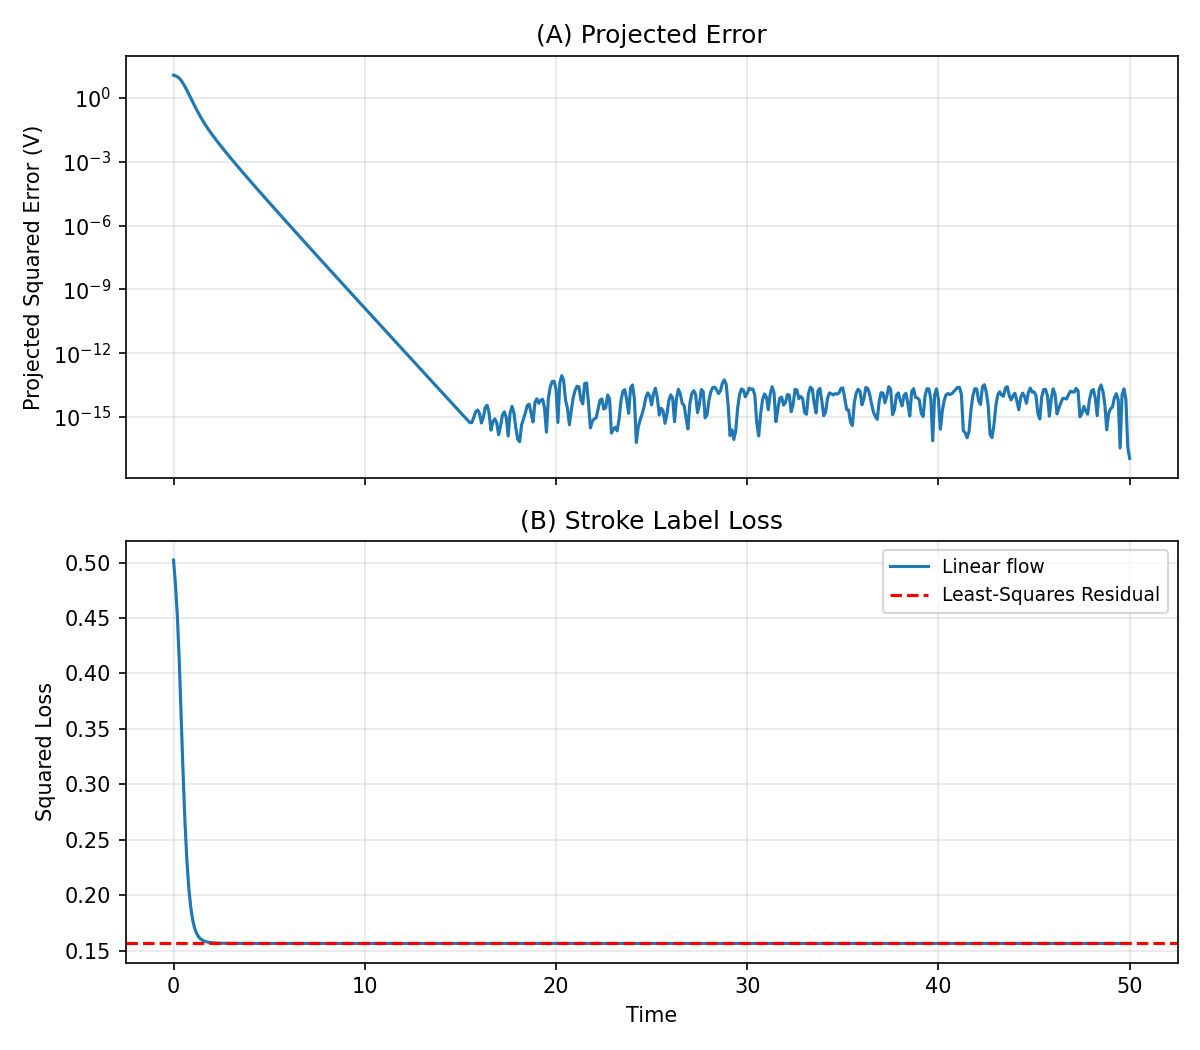

In [20]:
flow_saved = json.loads((RESULT_DIR / "flow_results.json").read_text())
T_saved = np.load(RESULT_DIR / "control_data.npz")["T"]
for seed in SEEDS:
    saved = np.load(RESULT_DIR / f"flow_states_{seed}.npz")
    B = saved["B"]
    a_shape, w_shape = saved["A0"].shape, saved["W0"].shape
    a_size = int(np.prod(a_shape))
    in_window = saved["times"] <= 1.0
    tighter_cosines = []
    for state in saved["tighter_states"][:, in_window].T:
        A = state[:a_size].reshape(a_shape)
        W = state[a_size:].reshape(w_shape)
        E = T_saved - W @ A
        gfa, gbp = B @ E, W.T @ E
        tighter_cosines.append(np.sum(gfa * gbp) / (np.linalg.norm(gfa) * np.linalg.norm(gbp)))
    original = np.asarray(flow_saved[str(seed)]["hidden_gradient_cosine"], dtype=float)[in_window]
    tighter_cosines = np.asarray(tighter_cosines)
    print(f"Seed {seed}: initial-window largest cosine drop {-np.min(np.diff(original)):.9f}; "
          f"tighter integration {-np.min(np.diff(tighter_cosines)):.9f}; "
          f"largest cosine discrepancy {np.max(np.abs(original-tighter_cosines)):.3e}")

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
for ax, metric, ylabel in zip(axes, ["V", "stroke_loss"],
                             ["Projected Squared Error (V)", "Squared Loss"]):
    times = np.asarray(flow_saved[str(SEEDS[0])]["time"])
    curves = np.asarray([flow_saved[str(seed)][metric] for seed in SEEDS])
    ax.plot(times, curves.mean(axis=0), color="tab:blue", label="Linear flow")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
axes[0].set_yscale("log")
axes[0].set_title("(A) Projected Error")
axes[1].set_title("(B) Stroke Label Loss")
residual_floor = float(flow_saved[str(SEEDS[0])]["stroke_loss"][-1])
axes[1].axhline(residual_floor, color="red", linestyle="--", label="Least-Squares Residual")
axes[1].legend(loc="best")
axes[-1].set_xlabel("Time")
fig.tight_layout()
fig.savefig(RESULT_DIR / "plots" / "linear_flow_manuscript.png", dpi=300)
fig.savefig(RESULT_DIR / "plots" / "linear_flow_manuscript.pdf")
plt.show()


# Reviewer 7: additional PCam DenseNet experiments

## 20. Scope and experimental question

This section sets up an additional **PCam image study**. The completed stroke sections above are retained. Run this section from its imports in a fresh kernel with `code/` as the working directory; the stroke training cells do not need to be rerun.

The added architecture is a compact two-stage DenseNet-BC. Within each dense block, a unit receives the concatenated feature maps from all earlier units and contributes new maps to later units. This changes the connectivity family represented by the existing ResNet-style CNN, which combines paths through addition. Bottleneck convolutions and transition compression follow the [original DenseNet formulation and implementation](https://github.com/liuzhuang13/DenseNet). The architecture below is explicitly specified; it is not DenseNet-121 or a pretrained model.

The revision adds this one architecture and one paired BP/DFA seed (42). Another ResNet experiment would repeat the family already studied. Larger ResNets, larger DenseNets, and depth/width sweeps belong to a separate scaling study. Transformer training remains outside the manuscript's stated scope. Concerns about its from-scratch data, training-budget, and tuning requirements motivate that boundary; PCam's size alone does not establish that a transformer would fail, and no transformer result is claimed here.

The question is whether the BP/DFA performance, calibration, and attribution differences persist in this densely connected model under the specified protocol. A second family adds architectural evidence; it does not establish arbitrary-depth scalability or isolate connectivity from every other architectural difference. Comparisons to the earlier CNN remain descriptive because both studies provide single-run observations without replicated uncertainty.

The two study runs are **not executed during setup**. The short verification below uses actual PCam minibatches and the complete model to check routing, mixed precision, memory, and throughput. Those disposable models supply no study performance estimates.

In [1]:
import gc
import json
import time
import random
import hashlib
import platform
import importlib.metadata
import subprocess
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             average_precision_score, precision_recall_fscore_support,
                             brier_score_loss, classification_report)
from sklearn.linear_model import LogisticRegression
from scipy.stats import rankdata

import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingWarmRestarts
from torchvision import transforms

assert torch.cuda.is_available(), 'This PCam setup is configured for the local CUDA GPU.'
image_device = torch.device('cuda')
PCAM_DATA_PATH = Path('pcam_cnn/pcam_data')
IMAGE_RESULT_DIR = Path('reviewer7_image_results')
for image_folder in ['models', 'plots', 'predictions', 'attributions']:
    (IMAGE_RESULT_DIR / image_folder).mkdir(parents=True, exist_ok=True)

IMAGE_SEEDS = [42]
IMAGE_BATCH_SIZE = 128
IMAGE_ATTRIBUTION_BATCH_SIZE = 64
IMAGE_BP_EPOCHS = 32
IMAGE_DFA_EPOCHS = 48
IMAGE_MATCHED_EPOCH = 32
DENSE_CONFIG = {'growth_rate': 12, 'block_layers': (4, 4), 'stem_channels': 32}
image_mean = [0.2222222222222222] * 3
image_std = [0.41573970964154905] * 3

# Match the CNN notebook's cuDNN configuration; seeded runs are not a bitwise guarantee.
torch.use_deterministic_algorithms(False)
torch.backends.cudnn.benchmark = True
torch.backends.cudnn.deterministic = False

def set_image_seed(image_seed):
    random.seed(image_seed)
    np.random.seed(image_seed)
    torch.manual_seed(image_seed)
    torch.cuda.manual_seed_all(image_seed)

plt.rcdefaults()
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'axes.titlesize': 12, 'axes.labelsize': 10,
                     'legend.fontsize': 9, 'lines.linewidth': 1.5, 'pdf.fonttype': 42})
print('PCam device:', torch.cuda.get_device_name(0))
print('GPU memory (GiB):', torch.cuda.get_device_properties(0).total_memory / 2**30)

PCam device: NVIDIA GeForce RTX 3050 6GB Laptop GPU
GPU memory (GiB): 5.99951171875


## 21. Existing PCam data and transformations

The supplied files use the same named splits as `CNN_FA.ipynb`: 262,144 training patches and 32,768 patches in each validation/test split. There is no new patch-level resplit. PCam labels indicate metastatic tissue in the central region of each 96-by-96 RGB patch; the [dataset authors describe the split and label definition](https://github.com/basveeling/pcam).

The augmentation function and numerical normalization constants are copied from the existing CNN notebook. The constants are retained as its training convention, rather than represented as newly calculated image statistics. Only training images receive rotation, affine transformation, and color jitter.

The dataset class keeps the existing image/label/transform interface but reads images on demand from HDF5. The supplied images occupy approximately 8.44 GiB before any float conversion, exceeding the RAM available during setup. The uncompressed HDF5 files have 32-image chunks; disabling their raw chunk cache avoids reading a whole chunk for every shuffled single-image request. No images are dropped, resized, replaced, or converted into tabular proxies. `num_workers=0` retains the original Windows notebook configuration and avoids replicated file handles and image arrays.

The physical training/evaluation batch is 128 for both learning rules, rather than the earlier CNN's 256. Full-precision attribution uses a separate batch of 64. Both DenseNet conditions therefore use the same training batch size and optimizer-step opportunities. The change is recorded explicitly when using the earlier CNN as a descriptive reference; this is not a pure connectivity-only comparison. Gradient accumulation is not used because it would not reproduce batch-256 BatchNorm statistics.

In [2]:
# Image trasnformations
def get_transform(split, mean, std):
    # robustness, overfitting prevention
    if split.lower() == 'train':
        return transforms.Compose([
            transforms.ToPILImage(),

            transforms.RandomRotation(20), # +- 20 degrees

            # transforms.RandomResizedCrop(
            #     size=96,            # output size is 96x96
            #     scale=(0.8, 1.0),   # crop 80-100% of area
            #     ratio=(0.9, 1.1)    # keep aspect ratio roughly square
            # ),

            transforms.RandomAffine(
                degrees=0,                 # rotation already applied
                translate=(0.1, 0.1),      # shift up to +-10% of image
                scale=(0.9, 1.1),          # zoom in/out
                shear=10                   # slant up to 10 degrees
            ),

            transforms.ColorJitter(
                brightness=0.2,
                contrast=0.2,
                saturation=0.2,
                hue=0.1
            ),

            # transforms.GaussianBlur(
            #     kernel_size=(3, 7), 
            #     sigma=(0.1, 2.0)
            # ),


            transforms.ToTensor(),
            transforms.Normalize(mean=mean, std=std)
        ])
    
    else:  # 'val', 'test' --> no transforms
        return transforms.Compose([
            transforms.ToPILImage(),
            transforms.ToTensor(),
            transforms.Normalize(mean=mean, std=std)
        ])

In [3]:
class PCamImageDataset(Dataset):
    def __init__(self, images_path, labels_path, transform=None):
        self.images_path = Path(images_path)
        self.labels_path = Path(labels_path)
        self.transform = transform
        with h5py.File(self.labels_path, 'r') as f:
            self.labels = np.asarray(f['y']).reshape(-1).astype(np.int64)
        self.images_file = h5py.File(self.images_path, 'r', rdcc_nbytes=0)
        self.images = self.images_file['x']
        assert self.images.shape == (len(self.labels), 96, 96, 3)
        assert self.images.dtype == np.uint8
        assert np.isin(self.labels, [0, 1]).all()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        image = self.images[int(idx)].astype(np.uint8)
        label = int(self.labels[int(idx)])
        if self.transform:
            image = self.transform(image)
        return image, label

    def close(self):
        self.images_file.close()

image_train_dataset = PCamImageDataset(
    PCAM_DATA_PATH / 'train/train_img.h5', PCAM_DATA_PATH / 'train/train_label.h5',
    get_transform('train', image_mean, image_std))
image_val_dataset = PCamImageDataset(
    PCAM_DATA_PATH / 'val/val_img.h5', PCAM_DATA_PATH / 'val/val_label.h5',
    get_transform('val', image_mean, image_std))
image_test_dataset = PCamImageDataset(
    PCAM_DATA_PATH / 'test/test_img.h5', PCAM_DATA_PATH / 'test/test_label.h5',
    get_transform('test', image_mean, image_std))

assert [len(d) for d in [image_train_dataset, image_val_dataset, image_test_dataset]] == [262144, 32768, 32768]
image_split_table = pd.DataFrame([
    {'Split': name, 'Images': len(dataset), 'Class 0': int((dataset.labels == 0).sum()),
     'Class 1': int((dataset.labels == 1).sum())}
    for name, dataset in [('Train', image_train_dataset), ('Validation', image_val_dataset),
                          ('Test', image_test_dataset)]])
display(image_split_table)

def make_image_loaders(image_seed):
    generator = torch.Generator().manual_seed(image_seed)
    train_loader = DataLoader(image_train_dataset, batch_size=IMAGE_BATCH_SIZE, shuffle=True,
                              generator=generator, num_workers=0, pin_memory=True)
    val_loader = DataLoader(image_val_dataset, batch_size=IMAGE_BATCH_SIZE, shuffle=False,
                            generator=torch.Generator().manual_seed(image_seed + 1),
                            num_workers=0, pin_memory=True)
    test_loader = DataLoader(image_test_dataset, batch_size=IMAGE_BATCH_SIZE, shuffle=False,
                             generator=torch.Generator().manual_seed(image_seed + 2),
                             num_workers=0, pin_memory=True)
    return train_loader, val_loader, test_loader

def image_file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(8 * 1024**2), b''):
            digest.update(chunk)
    return digest.hexdigest()

image_file_manifest = []
for dataset in [image_train_dataset, image_val_dataset, image_test_dataset]:
    for path in [dataset.images_path, dataset.labels_path]:
        image_file_manifest.append({'path': str(path), 'bytes': path.stat().st_size,
                                    'sha256': image_file_sha256(path)})
image_metadata = {
    'dataset': 'PCam', 'files': image_file_manifest,
    'source_notebook_sha256': image_file_sha256('pcam_cnn/CNN_FA.ipynb'),
    'python': platform.python_version(),
    'packages': {p: importlib.metadata.version(p) for p in
                 ['torch', 'torchvision', 'h5py', 'numpy', 'scipy', 'scikit-learn']},
    'cpu': subprocess.check_output(['powershell', '-NoProfile', '-Command',
                                   '(Get-CimInstance Win32_Processor).Name'], text=True).strip(),
    'gpu': torch.cuda.get_device_name(0), 'architecture': DENSE_CONFIG,
    'seeds': IMAGE_SEEDS, 'physical_batch_size': IMAGE_BATCH_SIZE,
    'epochs': {'bp': IMAGE_BP_EPOCHS, 'dfa': IMAGE_DFA_EPOCHS},
    'matched_epoch': IMAGE_MATCHED_EPOCH,
    'normalization': {'mean': image_mean, 'std': image_std},
    'optimizer': {'name': 'AdamW', 'lr': 3e-4, 'weight_decay': 1e-4,
                  'betas': [0.9, 0.999], 'eps': 1e-8},
    'scheduler': {'name': 'CosineAnnealingWarmRestarts', 'T_0': 8, 'T_mult': 2,
                  'eta_min': 1e-6, 'step': 'each minibatch'},
    'precision': 'CUDA float16 autocast with float32 parameters and scaled gradients',
    'grad_scaler_initial_scale': 1024, 'feedback_seed_offset': 100000,
    'attribution_batch_size': IMAGE_ATTRIBUTION_BATCH_SIZE,
    'cudnn_benchmark': True, 'cudnn_deterministic': False,
    'attribution_target': 'stage2.layers.3.conv2', 'positive_class': 1,
    'gradcam_resolution': [48, 48], 'display_resolution': [96, 96],
    'setup_only': True}
(IMAGE_RESULT_DIR / 'metadata.json').write_text(json.dumps(image_metadata, indent=2))

,Split,Images,Class 0,Class 1
0,Train,262144,131072,131072
1,Validation,32768,16399,16369
2,Test,32768,16391,16377


2695

## 22. Compact DenseNet-BC

The stem produces 32 channels at 96-by-96. Each dense block has four units with growth rate 12; each unit uses BN-ReLU-1-by-1 convolution to 48 bottleneck channels, followed by BN-ReLU-3-by-3 convolution to 12 new channels. The first block concatenates to 80 channels. A BN-ReLU-1-by-1 transition compresses this to 40 channels and average-pools to 48-by-48. The second block concatenates to 88 channels. The last unit uses spatial dropout 0.2, as the earlier two-stage CNN did in its last block. The 128/64/two-class classifier and its 0.5/0.3 dropout are retained.

BP and DFA have identical forward models. Within-architecture comparisons therefore hold capacity, initialization, inputs, and augmentation fixed. Bottlenecks, transition pooling, widths, and dense concatenation differ from the earlier ResNet-style model, so between-architecture results cannot identify connectivity as the sole cause.

In [4]:
class PCamDenseLayer(nn.Module):
    def __init__(self, in_ch, growth_rate, use_dropout=False):
        super().__init__()
        self.bn1 = nn.BatchNorm2d(in_ch)
        self.conv1 = nn.Conv2d(in_ch, 4 * growth_rate, kernel_size=1, bias=False)
        self.bn2 = nn.BatchNorm2d(4 * growth_rate)
        self.conv2 = nn.Conv2d(4 * growth_rate, growth_rate, kernel_size=3, padding=1, bias=False)
        self.drop = nn.Dropout2d(p=0.2) if use_dropout else nn.Identity()

    def forward(self, x):
        out = self.conv1(F.relu(self.bn1(x)))
        out = self.conv2(F.relu(self.bn2(out)))
        return self.drop(out)

class PCamDenseBlock(nn.Module):
    def __init__(self, in_ch, growth_rate, num_layers, dropout_last=False):
        super().__init__()
        self.layers = nn.ModuleList([
            PCamDenseLayer(in_ch + i * growth_rate, growth_rate,
                           use_dropout=dropout_last and i == num_layers - 1)
            for i in range(num_layers)])

    def forward(self, x):
        features = [x]
        for layer in self.layers:
            features.append(layer(torch.cat(features, dim=1)))
        return torch.cat(features, dim=1)

class PCamDenseNet(nn.Module):
    def __init__(self, growth_rate=12, block_layers=(4, 4), stem_channels=32, num_classes=2):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, stem_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(stem_channels), nn.ReLU())
        self.stage1 = PCamDenseBlock(stem_channels, growth_rate, block_layers[0])
        stage1_channels = stem_channels + block_layers[0] * growth_rate
        transition_channels = stage1_channels // 2
        self.transition = nn.Sequential(
            nn.BatchNorm2d(stage1_channels), nn.ReLU(),
            nn.Conv2d(stage1_channels, transition_channels, kernel_size=1, bias=False),
            nn.AvgPool2d(2))
        self.stage2 = PCamDenseBlock(transition_channels, growth_rate, block_layers[1],
                                    dropout_last=True)
        final_channels = transition_channels + block_layers[1] * growth_rate
        self.final_features = nn.Sequential(nn.BatchNorm2d(final_channels), nn.ReLU())
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(final_channels, 128), nn.ReLU(), nn.Dropout(p=0.5),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(p=0.3), nn.Linear(64, num_classes))

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.transition(x)
        x = self.stage2(x)
        x = self.final_features(x)
        return self.classifier(self.pool(x))

image_model_description = PCamDenseNet(**DENSE_CONFIG)
print(image_model_description)
print('Trainable parameters:', sum(p.numel() for p in image_model_description.parameters()))
del image_model_description

PCamDenseNet(
  (stem): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
  )
  (stage1): PCamDenseBlock(
    (layers): ModuleList(
      (0): PCamDenseLayer(
        (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv1): Conv2d(32, 48, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn2): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(48, 12, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (drop): Identity()
      )
      (1): PCamDenseLayer(
        (bn1): BatchNorm2d(44, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv1): Conv2d(44, 48, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn2): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats

## 23. Direct feedback at dense-unit outputs

The CNN's tensor-hook approach is retained. Each projected boundary is a stem, transition, or individual dense unit's **new feature maps**, before those maps are concatenated with earlier features. A unit's output gradient is accumulated across all its later uses and then replaced once by the fixed projection. Hooking an entire concatenation instead would also overwrite error on copied earlier maps. No tensor is detached from the forward concatenation.

For mean two-class cross-entropy on a batch of size $m$, the output error is $D=(P-Y)/m$. A projected feature map with $f$ entries per image receives $DB_l$, where $B_l\in\mathbb{R}^{2\times f}$ has fixed independent Gaussian entries with variance $1/2$, matching the original CNN convention. Both its construction and storage use float32. It has a separate seed generator so it does not change paired forward initialization, minibatch ordering, augmentation, or dropout sampling.

This is dense-unit/block DFA, matching the original CNN's use of composite boundaries: local autograd still trains the convolutions and BatchNorm parameters inside each unit, while the classifier uses exact BP. It is not presented as a separate direct projection into every internal bottleneck convolution or classifier layer.

Both rules use loss scaling. If the current scaler is $s$, the backward pass differentiates $s\mathcal L$ and each replaced tensor gradient is $sDB_l$. The optimizer unscales once before applying the update. Mixing an unscaled projection with a scaled backward pass would change the effective hidden learning rate. Projection is disabled during evaluation, true-gradient checks, and Grad-CAM, so attribution uses the trained forward model's ordinary gradient.

In [5]:
def init_image_B(act_shape, rng, num_classes=2):
    flat = int(np.prod(act_shape[1:]))
    B_np = rng.normal(0, 1 / np.sqrt(num_classes), (num_classes, flat)).astype(np.float32)
    return torch.from_numpy(B_np).to(image_device)

def attach_dense_feedback(model, image_seed):
    rng = np.random.RandomState(image_seed + 100000)
    context = {'B': {}, 'error': None, 'calls': {}}
    layer_names = (['stem'] + [f'stage1.layers.{i}' for i in range(len(model.stage1.layers))]
                   + ['transition'] + [f'stage2.layers.{i}' for i in range(len(model.stage2.layers))])

    def make_forward_hook(layer_name):
        def forward_hook(module, inputs, out):
            if not out.requires_grad:
                return
            if layer_name not in context['B']:
                context['B'][layer_name] = init_image_B(out.shape, rng)

            def tensor_hook(grad):
                if context['error'] is None:
                    return grad
                with torch.no_grad():
                    projected = context['error'].float() @ context['B'][layer_name]
                    grad_new = projected.reshape_as(grad).to(grad.dtype)
                context['calls'][layer_name] = context['calls'].get(layer_name, 0) + 1
                return grad_new
            out.register_hook(tensor_hook)
        return forward_hook

    modules = dict(model.named_modules())
    handles = [modules[name].register_forward_hook(make_forward_hook(name)) for name in layer_names]
    return context, handles

def image_initial_state_hash(model):
    digest = hashlib.sha256()
    for name, tensor in model.state_dict().items():
        digest.update(name.encode())
        digest.update(tensor.detach().cpu().numpy().tobytes())
    return digest.hexdigest()

def dense_training_step(model, optimizer, scaler, images, labels, feedback_context=None):
    optimizer.zero_grad(set_to_none=True)
    with torch.amp.autocast(device_type='cuda', dtype=getattr(model, 'image_amp_dtype', torch.float16)):
        outputs = model(images)
        loss = F.cross_entropy(outputs.float(), labels)
    if not torch.isfinite(loss):
        raise FloatingPointError('Nonfinite training loss; no metric will be substituted.')
    if feedback_context is not None:
        probs = outputs.detach().float().softmax(dim=1)
        y_onehot = F.one_hot(labels, num_classes=2).float()
        feedback_context['error'] = ((probs - y_onehot) / labels.numel()) * scaler.get_scale()
        feedback_context['calls'].clear()
    try:
        scaler.scale(loss).backward()
    finally:
        if feedback_context is not None:
            feedback_context['error'] = None
    scaler.unscale_(optimizer)
    old_scale = scaler.get_scale()
    scaler.step(optimizer)
    scaler.update()
    skipped = int(scaler.get_scale() < old_scale)
    return float(loss.item()), int((outputs.argmax(1) == labels).sum().item()), skipped

## 24. Training, checkpoints, and evaluation

Each seed begins with the same BP/DFA forward weights, augmentation RNG state, shuffled minibatch order, and dropout RNG state. Feedback matrices use their independent NumPy generator. Matching seeds reduce these sources of variation; cuDNN's original nondeterministic configuration still prevents a promise of bitwise replay.

AdamW ($3\times10^{-4}$, weight decay $10^{-4}$) and the cosine warm-restart schedule ($T_0=8$, $T_{\mathrm{mult}}=2$, minimum $10^{-6}$, updated each minibatch) follow the existing CNN. BP runs for 32 epochs and DFA for 48, retaining the original duration convention. **The primary paired comparison is BP epoch 32 versus DFA epoch 32**, with equal data passes and optimizer-step opportunities. DFA epoch 48 is a secondary comparison to BP epoch 32 under the earlier unequal-duration protocol. It cannot isolate the learning rule from the extra training budget. No best-test checkpoint selection, early stopping, or test-driven tuning is performed.

Every epoch saves loss, accuracy, learning rate, elapsed time, AMP scale, and skipped optimizer updates. A rolling recovery checkpoint contains weights, optimizer/scheduler/scaler states, feedback matrices, and RNG states. Endpoint checkpoints and ordered test probabilities are saved at epoch 32 and, for DFA, epoch 48. The rolling checkpoint is removed only after the run completes. Endpoint predictions are sufficient to recompute the discrimination and calibration tables. If a run fails, its rolling checkpoint and history remain available; a fresh run requires `resume=False`, while `resume=True` explicitly restores the rolling checkpoint and continues its run identifier. The continuation below restores the last completed epoch, including all saved training and random states.

Test accuracy, macro-F1, ROC-AUC, positive-class average precision, precision, and recall are calculated on the complete held-out test split. Calibration uses the earlier notebook's Brier score, ten-bin positive-probability ECE, and regularized logistic slope/intercept calculation. Slope/intercept are descriptive fitted diagnostics, not a recalibration applied to test predictions. Validation selects nothing and only monitors training. Test-label use in these summaries and attribution comparisons must not become a tuning loop.

In [6]:
def calibration_metrics(y_true, y_prob, n_bins=10):
    # Brier Score
    brier = brier_score_loss(y_true, y_prob)

    # Expected Calibration Error (ECE)
    bin_edges = np.linspace(0.0, 1.0, n_bins+1)
    binids = np.digitize(y_prob, bin_edges[1:-1])
    ece = 0.0
    for i in range(n_bins):
        bin_mask = binids == i
        if np.sum(bin_mask) > 0:
            bin_conf = np.mean(y_prob[bin_mask])
            bin_acc = np.mean(y_true[bin_mask])
            ece += np.abs(bin_conf - bin_acc) * np.sum(bin_mask)
    ece /= len(y_true)

    # Calibration slope and intercept
    eps = 1e-7
    y_prob_safe = np.clip(y_prob, eps, 1-eps)
    logit_preds = np.log(y_prob_safe / (1-y_prob_safe))
    lr = LogisticRegression(solver="lbfgs")
    lr.fit(logit_preds.reshape(-1, 1), y_true)
    slope = lr.coef_[0][0]
    intercept = lr.intercept_[0]

    return brier, ece, slope, intercept

In [7]:
@torch.no_grad()
def dense_evaluate(model, loader, keep_predictions=False):
    model.eval()
    loss_sum = 0.0
    correct = 0
    count = 0
    probabilities = []
    targets = []
    for images, labels in loader:
        images = images.to(image_device, non_blocking=True)
        labels = labels.to(image_device, non_blocking=True)
        with torch.amp.autocast(device_type='cuda', dtype=getattr(model, 'image_amp_dtype', torch.float16)):
            outputs = model(images)
        loss = F.cross_entropy(outputs.float(), labels, reduction='sum')
        if not torch.isfinite(loss):
            raise FloatingPointError('Nonfinite evaluation output.')
        loss_sum += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        count += labels.numel()
        if keep_predictions:
            probabilities.append(outputs.float().softmax(1).cpu().numpy())
            targets.append(labels.cpu().numpy())
    result = {'loss': loss_sum / count, 'accuracy': correct / count, 'count': count}
    if keep_predictions:
        result['probabilities'] = np.concatenate(probabilities)
        result['labels'] = np.concatenate(targets)
    return result

def dense_prediction_metrics(labels, probabilities):
    assert probabilities.shape == (len(labels), 2)
    assert np.isfinite(probabilities).all()
    assert np.allclose(probabilities.sum(1), 1, atol=1e-5)
    predictions = probabilities.argmax(1)
    positive_probability = probabilities[:, 1]
    precision, recall, _, _ = precision_recall_fscore_support(
        labels, predictions, labels=[1], zero_division=0)
    brier, ece, slope, intercept = calibration_metrics(labels, positive_probability)
    return {'accuracy': accuracy_score(labels, predictions),
            'macro_f1': f1_score(labels, predictions, average='macro'),
            'roc_auc': roc_auc_score(labels, positive_probability),
            'average_precision': average_precision_score(labels, positive_probability),
            'positive_precision': float(precision[0]), 'positive_recall': float(recall[0]),
            'brier': brier, 'ece_10': ece, 'calibration_slope': slope,
            'calibration_intercept': intercept}

def dense_checkpoint(model, rule, seed, epoch, initial_hash, history, optimizer,
                     scheduler, scaler, feedback, train_loader):
    return {'architecture': DENSE_CONFIG, 'rule': rule, 'seed': seed, 'epoch': epoch,
            'initial_state_sha256': initial_hash, 'state_dict': model.state_dict(),
            'run_id': history[0]['run_id'] if history else 'setup_diagnostic',
            'optimizer': optimizer.state_dict(), 'scheduler': scheduler.state_dict(),
            'scaler': scaler.state_dict(), 'history': history,
            'feedback': {} if feedback is None else feedback['B'],
            'rng': {'python': random.getstate(), 'numpy': np.random.get_state(),
                    'torch': torch.get_rng_state(), 'cuda': torch.cuda.get_rng_state_all(),
                    'shuffle_generator': train_loader.generator.get_state()},
            'metadata': image_metadata,
            'amp_dtype': str(getattr(model, 'image_amp_dtype', torch.float16)),
            'continuation': getattr(model, 'image_continuation', None)}

def save_dense_endpoint(model, rule, seed, epoch, checkpoint, test_loader):
    stem = f'{rule}_seed{seed}_epoch{epoch}'
    torch.save(checkpoint, IMAGE_RESULT_DIR / 'models' / f'{stem}.pt')
    result = dense_evaluate(model, test_loader, keep_predictions=True)
    labels, probabilities = result['labels'], result['probabilities']
    assert np.array_equal(labels, image_test_dataset.labels)
    np.savez_compressed(IMAGE_RESULT_DIR / 'predictions' / f'{stem}.npz',
                        labels=labels, probabilities=probabilities,
                        sample_indices=np.arange(len(labels)))
    metrics = {'rule': rule, 'seed': seed, 'epoch': epoch,
               'initial_state_sha256': checkpoint['initial_state_sha256'],
               'run_id': checkpoint.get('run_id', 'setup_diagnostic'),
               **dense_prediction_metrics(labels, probabilities)}
    (IMAGE_RESULT_DIR / f'{stem}_metrics.json').write_text(json.dumps(metrics, indent=2))
    report = classification_report(labels, probabilities.argmax(1), output_dict=True,
                                   zero_division=0)
    pd.DataFrame(report).T.to_csv(IMAGE_RESULT_DIR / f'{stem}_classification.csv')
    display(pd.DataFrame([metrics]).drop(columns=['initial_state_sha256', 'run_id']))
    return metrics

def train_dense_image(rule, seed, epochs, resume=False):
    assert rule in ['bp', 'dfa']
    set_image_seed(seed)
    train_loader, val_loader, test_loader = make_image_loaders(seed)
    model = PCamDenseNet(**DENSE_CONFIG).to(image_device)
    initial_hash = image_initial_state_hash(model)
    run_id = hashlib.sha256(f'{rule}:{seed}:{time.time_ns()}'.encode()).hexdigest()[:16]
    optimizer = optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
    scheduler = CosineAnnealingWarmRestarts(optimizer, T_0=8, T_mult=2, eta_min=1e-6)
    scaler = torch.amp.GradScaler('cuda', init_scale=1024)
    feedback, handles = attach_dense_feedback(model, seed) if rule == 'dfa' else (None, [])
    history, endpoint_metrics = [], []
    rolling_path = IMAGE_RESULT_DIR / 'models' / f'{rule}_seed{seed}_last.pt'
    start_epoch = 0
    model.image_amp_dtype = torch.float16
    model.image_continuation = None
    if resume:
        assert rule == 'dfa' and seed == 42 and epochs == 48
        assert torch.cuda.is_bf16_supported(), 'BF16 continuation requires native GPU support.'
        saved = torch.load(rolling_path, map_location='cpu', weights_only=False)
        assert (saved['rule'], saved['seed'], saved['architecture']) == (rule, seed, DENSE_CONFIG)
        assert saved['initial_state_sha256'] == initial_hash, 'Forward initialization differs.'
        assert 0 < saved['epoch'] < epochs
        assert [row['epoch'] for row in saved['history']] == list(range(1, saved['epoch'] + 1))
        assert all(row['run_id'] == saved['run_id'] for row in saved['history'])
        for tensors in [saved['state_dict'], saved['feedback']]:
            assert all(torch.isfinite(t).all() for t in tensors.values()), 'Nonfinite checkpoint tensor.'
        for state in saved['optimizer']['state'].values():
            assert all(not torch.is_tensor(t) or torch.isfinite(t).all() for t in state.values())
        model.load_state_dict(saved['state_dict'])
        optimizer.load_state_dict(saved['optimizer'])
        scheduler.load_state_dict(saved['scheduler'])
        scaler.load_state_dict(saved['scaler'])
        feedback['B'] = {name: tensor.to(image_device) for name, tensor in saved['feedback'].items()}
        assert len(feedback['B']) == 10, 'Missing fixed feedback boundaries.'
        history = saved['history']
        start_epoch, run_id = saved['epoch'], saved['run_id']
        model.image_amp_dtype = torch.bfloat16
        model.image_continuation = saved.get('continuation') or {
            'checkpoint_epoch': start_epoch, 'first_resumed_epoch': start_epoch + 1,
            'previous_precision': 'float16', 'resumed_precision': 'bfloat16',
            'reason': 'Nonfinite FP16 loss during original epoch 33; overflow suspected but not proven.',
            'restored': ['model', 'optimizer', 'scheduler', 'scaler', 'feedback',
                         'python_rng', 'numpy_rng', 'torch_rng', 'cuda_rng', 'shuffle_generator'],
            'partial_epoch_33_updates': 'Discarded; replay starts from the end of saved epoch 32.'}
        image_metadata['setup_only'] = False
        image_metadata['continuation'] = model.image_continuation
        (IMAGE_RESULT_DIR / 'metadata.json').write_text(json.dumps(image_metadata, indent=2))
        for endpoint in [IMAGE_MATCHED_EPOCH, epochs]:
            if endpoint <= start_epoch:
                metrics = json.loads((IMAGE_RESULT_DIR / f'{rule}_seed{seed}_epoch{endpoint}_metrics.json').read_text())
                assert metrics['run_id'] == run_id and metrics['initial_state_sha256'] == initial_hash
                endpoint_metrics.append(metrics)
        train_loader.generator.set_state(saved['rng']['shuffle_generator'])
        random.setstate(saved['rng']['python'])
        np.random.set_state(saved['rng']['numpy'])
        torch.set_rng_state(saved['rng']['torch'])
        torch.cuda.set_rng_state_all(saved['rng']['cuda'])
        print(f'Restored seed {seed}, run {run_id}, end of epoch {start_epoch}; continuing in BF16.')
        display(pd.DataFrame(history).tail(1))
        del saved
    torch.cuda.reset_peak_memory_stats()
    run_start = time.perf_counter()
    progress = tqdm(range(start_epoch, epochs), desc=f'DenseNet {rule.upper()}, seed {seed}')
    for epoch in progress:
        model.train()
        torch.cuda.synchronize()
        epoch_start = time.perf_counter()
        loss_sum, correct, skipped, count = 0.0, 0, 0, 0
        for batch_idx, (images, labels) in enumerate(train_loader):
            images = images.to(image_device, non_blocking=True)
            labels = labels.to(image_device, non_blocking=True)
            loss, batch_correct, batch_skipped = dense_training_step(
                model, optimizer, scaler, images, labels, feedback)
            scheduler.step(epoch + batch_idx / len(train_loader))
            n = labels.numel()
            loss_sum += loss * n
            correct += batch_correct
            skipped += batch_skipped
            count += n
        torch.cuda.synchronize()
        training_seconds = time.perf_counter() - epoch_start
        validation_start = time.perf_counter()
        validation = dense_evaluate(model, val_loader)
        torch.cuda.synchronize()
        history.append({'epoch': epoch + 1, 'run_id': run_id, 'train_loss': loss_sum / count,
                        'train_accuracy': correct / count,
                        'val_loss': validation['loss'], 'val_accuracy': validation['accuracy'],
                        'lr': optimizer.param_groups[0]['lr'], 'amp_scale': scaler.get_scale(),
                        'skipped_updates': skipped, 'amp_dtype': str(model.image_amp_dtype),
                        'train_seconds': training_seconds,
                        'val_seconds': time.perf_counter() - validation_start})
        progress.set_postfix({'Train Loss': f'{loss_sum / count:.4f}',
                              'Val Loss': f'{validation["loss"]:.4f}',
                              'Val Acc': f'{validation["accuracy"]:.4f}', 'AMP skips': skipped})
        pd.DataFrame(history).to_csv(IMAGE_RESULT_DIR / f'{rule}_seed{seed}_history.csv', index=False)
        checkpoint = dense_checkpoint(model, rule, seed, epoch + 1, initial_hash,
                                      history, optimizer, scheduler, scaler, feedback, train_loader)
        torch.save(checkpoint, rolling_path)
        if epoch + 1 in [IMAGE_MATCHED_EPOCH, epochs]:
            endpoint_metrics.append(save_dense_endpoint(model, rule, seed, epoch + 1,
                                                        checkpoint, test_loader))
        del checkpoint
    torch.cuda.synchronize()
    runtime = {'rule': rule, 'seed': seed, 'run_id': run_id, 'completed_epochs': epochs, 'seconds': None if resume else time.perf_counter() - run_start,
               'resume_session_seconds': time.perf_counter() - run_start if resume else None,
               'completed_epoch_train_val_seconds': sum(row['train_seconds'] + row['val_seconds'] for row in history),
               'timing_note': 'Total original wall time was not captured before interruption; epoch timing sums and continuation wall time are reported separately.' if resume else None,
               'continuation': model.image_continuation,
               'peak_allocated_GiB': torch.cuda.max_memory_allocated() / 2**30,
               'peak_reserved_GiB': torch.cuda.max_memory_reserved() / 2**30}
    (IMAGE_RESULT_DIR / f'{rule}_seed{seed}_runtime.json').write_text(json.dumps(runtime, indent=2))
    for handle in handles:
        handle.remove()
    rolling_path.unlink(missing_ok=True)
    del model, optimizer, scheduler, scaler, feedback
    gc.collect()
    torch.cuda.empty_cache()
    return endpoint_metrics

## 25. Single-run descriptive summaries

The study uses **seed 42 only**, with one BP run and one DFA run, following the single-seed scope of the earlier ResNet-style PCam CNN. Forward initialization and minibatch/augmentation/dropout seeds are paired within DenseNet. BP epoch 32 versus DFA epoch 32 is the matched-budget comparison; BP epoch 32 versus DFA epoch 48 is the additional-duration comparison. These are three saved endpoints from two training runs, not three independent repetitions.

Tables report the actual single-run test metrics and DFA-minus-BP differences. Positive accuracy/F1/AUC differences favor DFA; positive Brier/ECE differences indicate worse DFA calibration. Between-seed SD, seed-bootstrap intervals, Wilcoxon tests, and Holm correction are not calculated from one seed. Zero SD must not be displayed as if it established reproducibility. No significance or equivalence claim is supported by this one-seed comparison.

The archived two-stage classification results in `pcam_cnn/CNN_FA.ipynb` remain a single-run descriptive reference. They are not substituted for the separate CNN attribution checkpoint results reported in the manuscript. Its missing replicated quantities and calibration diagnostics cannot be reconstructed from archived outputs. Physical batch size also differs, so the cross-family table is descriptive and does not isolate connectivity as the sole cause.

In [8]:
def summarize_dense_results():
    assert IMAGE_SEEDS == [42], 'This study has one paired seed: 42.'
    seed = IMAGE_SEEDS[0]
    rows = []
    for rule, epoch in [('bp', IMAGE_BP_EPOCHS), ('dfa', IMAGE_MATCHED_EPOCH), ('dfa', IMAGE_DFA_EPOCHS)]:
        rows.append(json.loads((IMAGE_RESULT_DIR / f'{rule}_seed{seed}_epoch{epoch}_metrics.json').read_text()))
    per_run = pd.DataFrame(rows)
    for rule, expected_epochs in [('bp', IMAGE_BP_EPOCHS), ('dfa', IMAGE_DFA_EPOCHS)]:
        history = pd.read_csv(IMAGE_RESULT_DIR / f'{rule}_seed{seed}_history.csv', dtype={'run_id': str})
        runtime = json.loads((IMAGE_RESULT_DIR / f'{rule}_seed{seed}_runtime.json').read_text())
        assert np.array_equal(history.epoch.to_numpy(), np.arange(1, expected_epochs + 1)), 'Incomplete history'
        endpoints = per_run.loc[per_run.rule == rule]
        assert history.run_id.nunique() == 1 and endpoints.run_id.nunique() == 1
        assert runtime['completed_epochs'] == expected_epochs
        assert history.run_id.iloc[0] == runtime['run_id'] == endpoints.run_id.iloc[0], 'Mixed run artifacts'
    assert per_run.initial_state_sha256.nunique() == 1, 'Unpaired BP/DFA forward initialization'
    per_run.to_csv(IMAGE_RESULT_DIR / 'dense_per_run_metrics.csv', index=False)
    metric_names = ['accuracy', 'macro_f1', 'roc_auc', 'average_precision',
                    'positive_precision', 'positive_recall', 'brier', 'ece_10',
                    'calibration_slope', 'calibration_intercept']
    bp = per_run.loc[per_run.rule == 'bp'].iloc[0]
    differences = []
    for endpoint in [IMAGE_MATCHED_EPOCH, IMAGE_DFA_EPOCHS]:
        dfa = per_run.loc[(per_run.rule == 'dfa') & (per_run.epoch == endpoint)].iloc[0]
        for metric in metric_names:
            differences.append({'comparison': f'BP{IMAGE_BP_EPOCHS} vs DFA{endpoint}',
                                'seed': seed, 'metric': metric, 'bp': float(bp[metric]),
                                'dfa': float(dfa[metric]),
                                'dfa_minus_bp': float(dfa[metric] - bp[metric])})
    differences = pd.DataFrame(differences)
    differences.to_csv(IMAGE_RESULT_DIR / 'dense_descriptive_differences.csv', index=False)
    archived = pd.DataFrame([
        {'architecture': 'Archived ResNet-style CNN', 'rule': 'bp', 'epochs': 32,
         'seeds': 1, 'batch_size': 256, 'accuracy': 0.8790, 'macro_f1': 0.8786, 'roc_auc': 0.9535},
        {'architecture': 'Archived ResNet-style CNN', 'rule': 'dfa', 'epochs': 48,
         'seeds': 1, 'batch_size': 256, 'accuracy': 0.7131, 'macro_f1': 0.7025, 'roc_auc': 0.8341}])
    archived.to_csv(IMAGE_RESULT_DIR / 'archived_cnn_descriptive_reference.csv', index=False)
    comparison = []
    for _, row in archived.iterrows():
        comparison.append({'Architecture': 'Earlier ResNet-style CNN', 'Rule': row.rule.upper(),
                           'Epochs': int(row.epochs), 'Seed': 42, 'Runs': 1, 'Batch': 256,
                           **{metric: float(row[metric]) for metric in ['accuracy', 'macro_f1', 'roc_auc']}})
    for _, row in per_run.iterrows():
        comparison.append({'Architecture': 'Compact DenseNet-BC', 'Rule': row.rule.upper(),
                           'Epochs': int(row.epoch), 'Seed': seed, 'Runs': 1, 'Batch': IMAGE_BATCH_SIZE,
                           **{metric: float(row[metric]) for metric in ['accuracy', 'macro_f1', 'roc_auc']}})
    comparison = pd.DataFrame(comparison).rename(columns={'accuracy': 'Accuracy',
                                                         'macro_f1': 'Macro-F1', 'roc_auc': 'ROC-AUC'})
    comparison.to_csv(IMAGE_RESULT_DIR / 'cross_architecture_descriptive_summary.csv', index=False)
    display(per_run.drop(columns=['initial_state_sha256', 'run_id']).round(5))
    display(differences.round(5))
    display(comparison.round(4))
    return per_run, differences

## 26. Grad-CAM agreement on the complete test split

Both methods are attributed to the same **positive class**, rather than each model's predicted class. The target is the last dense unit's 3-by-3 convolution (`stage2.layers.3.conv2`), before dropout/concatenation; it produces 12 new maps at 48-by-48. Grad-CAM uses ordinary gradients of the class-1 logit in eval mode, spatially averages channel gradients, takes the weighted channel sum, and applies ReLU. DFA hooks are absent from the loaded attribution models. This target describes the last unit's new features, not every feature in the final concatenation.

Agreement is measured separately at the native 48-by-48 resolution and after bilinear interpolation to the 96-by-96 image resolution (`align_corners=False`). It uses raw nonnegative maps, without per-image display normalization: IoU of the highest 10% and 20% of pixels, and Spearman rank correlation. Exactly $\lceil qN\rceil$ pixels are selected; equal scores are resolved by flattened pixel index, identically for both rules. A constant map has no spatial ranking and is marked undefined for all three metrics, including IoU, rather than assigning arbitrary agreement through a tie rule. Counts of zero, constant, and valid map pairs accompany every summary.

Every test patch is retained. Maps are processed batchwise; only per-patch metrics/validity are saved, avoiding several GiB of map storage. Tables contain means, medians, population SD, IQR, class-stratified means, and 10,000-resample patch bootstrap intervals per seed. Patch intervals are conditional on the split and trained models. PCam patches from the same slide can be correlated, and slide identifiers are not supplied here, so these intervals are not independent-patient uncertainty. Reported SD describes variation across valid patches within the single trained model pair; no between-seed SD is estimated. Undefined values are never replaced by zero.

The existing manuscript's Grad-CAM layout is retained: a two-by-three grid (input, BP, DFA), with lower/higher agreement cases, true labels, predicted class/probability, and three agreement values in the same positions. For seed 42, cases nearest the 10th and 90th percentiles of $[\mathrm{IoU}_{10}+\mathrm{IoU}_{20}+(\rho+1)/2]/3$ at image resolution are selected, matching the manuscript selection convention. Each map is min-max normalized for display only, using `magma` and alpha 0.45. Selection is descriptive and not a performance test. Since original CNN checkpoint/attribution source files are unavailable, the implementation here explicitly follows the documented manuscript metric, tie-handling, selection, and display definitions, with the corresponding final DenseNet convolution as its target.

In [9]:
def load_dense_image(rule, seed, epoch):
    path = IMAGE_RESULT_DIR / 'models' / f'{rule}_seed{seed}_epoch{epoch}.pt'
    # These are locally generated, trusted checkpoints with NumPy/Python RNG states.
    checkpoint = torch.load(path, map_location='cpu', weights_only=False)
    assert checkpoint['rule'] == rule and checkpoint['seed'] == seed and checkpoint['epoch'] == epoch
    assert checkpoint['architecture'] == DENSE_CONFIG
    model = PCamDenseNet(**checkpoint['architecture']).to(image_device)
    model.load_state_dict(checkpoint['state_dict'])
    model.eval()
    del checkpoint
    return model

def dense_gradcam(model, images):
    activations = []
    handle = model.stage2.layers[-1].conv2.register_forward_hook(
        lambda module, inputs, out: activations.append(out))
    try:
        with torch.enable_grad(), torch.amp.autocast(device_type='cuda', enabled=False):
            logits = model(images.float())
            gradients, = torch.autograd.grad(logits[:, 1].sum(), activations[0])
            weights = gradients.mean(dim=(2, 3), keepdim=True)
            cam = F.relu((weights * activations[0]).sum(dim=1))
            interpolated = F.interpolate(cam[:, None], size=(96, 96), mode='bilinear',
                                         align_corners=False)[:, 0]
        assert cam.shape[1:] == (48, 48)
        assert torch.isfinite(cam).all() and torch.isfinite(interpolated).all()
        return cam.detach().cpu().numpy(), interpolated.detach().cpu().numpy()
    finally:
        handle.remove()

def dense_map_agreement(bp_maps, dfa_maps):
    assert bp_maps.shape == dfa_maps.shape
    bp = bp_maps.reshape(len(bp_maps), -1).astype(np.float64)
    dfa = dfa_maps.reshape(len(dfa_maps), -1).astype(np.float64)
    assert np.isfinite(bp).all() and np.isfinite(dfa).all()
    bp_constant = np.ptp(bp, axis=1) == 0
    dfa_constant = np.ptp(dfa, axis=1) == 0
    valid = ~(bp_constant | dfa_constant)
    result = {'bp_zero': np.all(bp == 0, axis=1), 'dfa_zero': np.all(dfa == 0, axis=1),
              'bp_constant': bp_constant, 'dfa_constant': dfa_constant, 'valid': valid}
    for fraction in [0.1, 0.2]:
        k = int(np.ceil(bp.shape[1] * fraction))
        values = np.full(len(bp), np.nan)
        if valid.any():
            bp_order = np.argsort(-bp[valid], axis=1, kind='stable')[:, :k]
            dfa_order = np.argsort(-dfa[valid], axis=1, kind='stable')[:, :k]
            bp_masks = np.zeros((valid.sum(), bp.shape[1]), dtype=bool)
            dfa_masks = np.zeros_like(bp_masks)
            np.put_along_axis(bp_masks, bp_order, True, axis=1)
            np.put_along_axis(dfa_masks, dfa_order, True, axis=1)
            intersection = (bp_masks & dfa_masks).sum(axis=1)
            values[valid] = intersection / (2 * k - intersection)
        result[f'iou_{int(fraction * 100)}'] = values
    rho = np.full(len(bp), np.nan)
    if valid.any():
        bp_ranks = rankdata(bp[valid], axis=1, method='average')
        dfa_ranks = rankdata(dfa[valid], axis=1, method='average')
        bp_ranks -= bp_ranks.mean(axis=1, keepdims=True)
        dfa_ranks -= dfa_ranks.mean(axis=1, keepdims=True)
        rho[valid] = np.clip((bp_ranks * dfa_ranks).sum(1) /
                            np.sqrt((bp_ranks**2).sum(1) * (dfa_ranks**2).sum(1)), -1, 1)
    result['spearman'] = rho
    return result

def dense_attribution_rows(bp_maps, dfa_maps, indices, labels, seed, endpoint, resolution):
    agreement = dense_map_agreement(bp_maps, dfa_maps)
    return pd.DataFrame({'sample_index': indices, 'label': labels, 'seed': seed,
                         'dfa_epoch': endpoint, 'resolution': resolution, **agreement})

def compute_dense_attributions():
    test_loader = DataLoader(image_test_dataset, batch_size=IMAGE_ATTRIBUTION_BATCH_SIZE,
                             shuffle=False, num_workers=0, pin_memory=True,
                             generator=torch.Generator().manual_seed(IMAGE_SEEDS[0] + 2))
    for seed in IMAGE_SEEDS:
        models = {'bp': load_dense_image('bp', seed, IMAGE_BP_EPOCHS),
                  f'dfa{IMAGE_MATCHED_EPOCH}': load_dense_image('dfa', seed, IMAGE_MATCHED_EPOCH),
                  f'dfa{IMAGE_DFA_EPOCHS}': load_dense_image('dfa', seed, IMAGE_DFA_EPOCHS)}
        rows = {IMAGE_MATCHED_EPOCH: [], IMAGE_DFA_EPOCHS: []}
        offset = 0
        for images, labels in tqdm(test_loader, desc=f'Grad-CAM, seed {seed}'):
            images = images.to(image_device, non_blocking=True)
            bp_native, bp_image = dense_gradcam(models['bp'], images)
            indices = np.arange(offset, offset + len(labels))
            for endpoint in [IMAGE_MATCHED_EPOCH, IMAGE_DFA_EPOCHS]:
                dfa_native, dfa_image = dense_gradcam(models[f'dfa{endpoint}'], images)
                for resolution, bp_maps, dfa_maps in [('native48', bp_native, dfa_native),
                                                     ('image96', bp_image, dfa_image)]:
                    rows[endpoint].append(dense_attribution_rows(
                        bp_maps, dfa_maps, indices, labels.numpy(), seed, endpoint, resolution))
            offset += len(labels)
        assert offset == len(image_test_dataset)
        for endpoint in [IMAGE_MATCHED_EPOCH, IMAGE_DFA_EPOCHS]:
            pd.concat(rows[endpoint], ignore_index=True).to_csv(
                IMAGE_RESULT_DIR / 'attributions' / f'seed{seed}_BP{IMAGE_BP_EPOCHS}_DFA{endpoint}.csv', index=False)
        del models, rows, images
        gc.collect()
        torch.cuda.empty_cache()

def image_patch_mean_interval(values, rng):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) == 0:
        return np.nan, np.nan
    means = np.empty(10000)
    for start in range(0, 10000, 32):
        stop = min(start + 32, 10000)
        indices = rng.integers(0, len(values), size=(stop - start, len(values)))
        means[start:stop] = values[indices].mean(axis=1)
    return tuple(np.quantile(means, [0.025, 0.975]))

def summarize_dense_attributions():
    rows = []
    rng = np.random.default_rng(20260720)
    for seed in IMAGE_SEEDS:
        for endpoint in [IMAGE_MATCHED_EPOCH, IMAGE_DFA_EPOCHS]:
            table = pd.read_csv(IMAGE_RESULT_DIR / 'attributions' / f'seed{seed}_BP{IMAGE_BP_EPOCHS}_DFA{endpoint}.csv')
            for resolution, group in table.groupby('resolution', sort=False):
                assert len(group) == len(image_test_dataset) and group.sample_index.nunique() == len(group)
                for metric in ['iou_10', 'iou_20', 'spearman']:
                    valid = group[metric].dropna().to_numpy()
                    low, high = image_patch_mean_interval(valid, rng)
                    rows.append({'seed': seed, 'dfa_epoch': endpoint, 'resolution': resolution,
                                 'metric': metric, 'total_pairs': len(group), 'valid_pairs': len(valid),
                                 'bp_zero': int(group.bp_zero.sum()), 'dfa_zero': int(group.dfa_zero.sum()),
                                 'bp_constant': int(group.bp_constant.sum()),
                                 'dfa_constant': int(group.dfa_constant.sum()),
                                 'mean': valid.mean() if len(valid) else np.nan,
                                 'median': np.median(valid) if len(valid) else np.nan,
                                 'sd_population': valid.std(ddof=0) if len(valid) else np.nan,
                                 'iqr': np.quantile(valid, .75) - np.quantile(valid, .25) if len(valid) else np.nan,
                                 'ci_low': low, 'ci_high': high,
                                 'class0_valid_pairs': int(group.loc[group.label == 0, metric].notna().sum()),
                                 'class1_valid_pairs': int(group.loc[group.label == 1, metric].notna().sum()),
                                 'class0_mean': group.loc[group.label == 0, metric].mean(),
                                 'class1_mean': group.loc[group.label == 1, metric].mean()})
    per_seed = pd.DataFrame(rows)
    per_seed.to_csv(IMAGE_RESULT_DIR / 'attribution_single_seed_summary.csv', index=False)
    display(per_seed.round(5))
    return per_seed

## 27. Figures in the existing manuscript style

Learning curves retain the CNN figure's two-by-two arrangement: BP loss/accuracy above DFA loss/accuracy, training in blue and validation in orange, epochs on the horizontal axis, white background, conventional labels, and teal panel letters. Lines show the actual seed-42 histories; no averaging or between-seed uncertainty is displayed. Unequal 32/48 durations remain visible. The attribution figures retain input/BP/DFA columns and lower/higher agreement rows, without an additional dashboard, categorical score colors, or embedded statistical annotations. Full numerical comparisons remain in the adjacent tables. PDF and 300-dpi PNG outputs are saved under this notebook's image-result directory.

In [10]:
def plot_dense_learning_curves():
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for row, rule in enumerate(['bp', 'dfa']):
        history = pd.read_csv(IMAGE_RESULT_DIR / f'{rule}_seed{IMAGE_SEEDS[0]}_history.csv')
        epochs = history.epoch.to_numpy()
        for column, metric in enumerate(['loss', 'accuracy']):
            ax = axes[row, column]
            for split, color in [('train', 'tab:blue'), ('val', 'tab:orange')]:
                values = history[f'{split}_{metric}'].to_numpy()
                ax.plot(epochs, values, label='Train' if split == 'train' else 'Validation',
                        color=color)
            ax.set(title=f'{rule.upper()} {metric.title()}', xlabel='Epoch', ylabel=metric.title())
            ax.text(-.10, 1.06, f'({"ABCD"[row * 2 + column]})', transform=ax.transAxes,
                    color='#00838f', fontsize=14, fontweight='bold')
            ax.legend()
    fig.tight_layout()
    for suffix in ['pdf', 'png']:
        fig.savefig(IMAGE_RESULT_DIR / 'plots' / f'dense_learning_curves.{suffix}', dpi=300, bbox_inches='tight')
    plt.show()

def plot_dense_attribution_examples(endpoint):
    seed = IMAGE_SEEDS[0]
    table = pd.read_csv(IMAGE_RESULT_DIR / 'attributions' / f'seed{seed}_BP{IMAGE_BP_EPOCHS}_DFA{endpoint}.csv')
    native = table.loc[table.resolution == 'image96'].dropna(subset=['iou_10', 'iou_20', 'spearman']).copy()
    if native.empty:
        print(f'BP{IMAGE_BP_EPOCHS}/DFA{endpoint}: no nonconstant paired maps; example figure is undefined.')
        return
    native['agreement_score'] = (native.iou_10 + native.iou_20 + (native.spearman + 1) / 2) / 3
    selected = []
    for quantile in [.1, .9]:
        target = native.agreement_score.quantile(quantile)
        row = native.assign(distance=(native.agreement_score - target).abs()).sort_values(
            ['distance', 'sample_index'], kind='stable').iloc[0]
        selected.append(int(row.sample_index))
    bp = load_dense_image('bp', seed, IMAGE_BP_EPOCHS)
    dfa = load_dense_image('dfa', seed, endpoint)
    images = torch.stack([image_test_dataset[i][0] for i in selected]).to(image_device)
    _, bp_maps = dense_gradcam(bp, images)
    _, dfa_maps = dense_gradcam(dfa, images)
    fig, axes = plt.subplots(2, 3, figsize=(9, 6))
    for row, index in enumerate(selected):
        image = np.asarray(image_test_dataset.images[index])
        axes[row, 0].imshow(image)
        for column, cam in [(1, bp_maps[row]), (2, dfa_maps[row])]:
            axes[row, column].imshow(image)
            display_map = (cam - cam.min()) / (cam.max() - cam.min())
            axes[row, column].imshow(display_map, cmap='magma', vmin=0, vmax=1, alpha=.45)
        for ax in axes[row]:
            ax.set_xticks([])
            ax.set_yticks([])
        axes[row, 0].set_title(('Lower agreement' if row == 0 else 'Higher agreement') +
                               '\nOriginal; true: ' + ('malignant' if image_test_dataset.labels[index] else 'benign'))
        score = native.set_index('sample_index').loc[index]
        axes[row, 0].set_ylabel(f'IoU10={score.iou_10:.3f}; IoU20={score.iou_20:.3f}\nSpearman={score.spearman:.3f}')
    with torch.no_grad():
        bp_probs = bp(images).float().softmax(1).cpu().numpy()
        dfa_probs = dfa(images).float().softmax(1).cpu().numpy()
    for row in range(2):
        for column, name, probabilities in [(1, 'BP', bp_probs), (2, 'DFA', dfa_probs)]:
            prediction = 'malignant' if probabilities[row].argmax() else 'benign'
            axes[row, column].set_title(f'{name} Grad-CAM\n{prediction}, p={probabilities[row, 1]:.3f}')
    fig.tight_layout()
    for suffix in ['pdf', 'png']:
        fig.savefig(IMAGE_RESULT_DIR / 'plots' / f'dense_gradcam_BP{IMAGE_BP_EPOCHS}_DFA{endpoint}.{suffix}',
                    dpi=300, bbox_inches='tight')
    pd.DataFrame({'sample_index': selected, 'case': ['lower', 'higher'], 'seed': seed,
                  'bp_epoch': IMAGE_BP_EPOCHS, 'dfa_epoch': endpoint}).to_csv(
                      IMAGE_RESULT_DIR / 'plots' / f'dense_gradcam_BP{IMAGE_BP_EPOCHS}_DFA{endpoint}_selection.csv', index=False)
    plt.show()
    del bp, dfa, images
    gc.collect()
    torch.cuda.empty_cache()

## 28. Local verification and runtime estimate

This cell verifies the full architecture on real train/validation/test patches. It checks identical BP/DFA initialization, all ten projected boundaries, exactly one injection per boundary, the scaled projection equation, finite gradients for all parameters, and exact classifier gradients against BP when dropout is disabled. It then performs ordinary mixed-precision optimizer updates at physical training batch 128, measures end-to-end batch throughput including image reads and transformations, evaluates real test probabilities/calibration, reloads a scratch checkpoint, and computes native/interpolated Grad-CAM and agreement. Scratch weights are discarded; this is a setup diagnostic, not one of the two study runs.

Timing uses warm-up batches and CUDA synchronization. The estimate extrapolates to 32 BP training epochs and 48 DFA training epochs, all 80 validation passes, three endpoint test passes, and one complete test attribution pass through three endpoint models per seed. It includes a separate allowance for checkpoint/statistical/figure work. This short measurement cannot establish sustained temperature, clock, power, or disk behavior over days. Memory is measured, while thermal stability remains an empirical condition during the eventual full run. The original notebook's epoch timings are not used as measurements of this machine.

In [ ]:
def verify_dense_image_setup():
    global IMAGE_RESULT_DIR, image_test_dataset
    import tempfile
    import copy
    from IPython.utils.capture import capture_output
    from torch.utils.data import Subset

    seed = IMAGE_SEEDS[0]
    set_image_seed(seed)
    train_loader, val_loader, test_loader = make_image_loaders(seed)
    train_images, train_labels = next(iter(train_loader))
    train_images = train_images.to(image_device)
    train_labels = train_labels.to(image_device)
    set_image_seed(seed)
    model = PCamDenseNet(**DENSE_CONFIG).to(image_device)
    initial_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    initial_hash = image_initial_state_hash(model)
    set_image_seed(seed)
    paired_model = PCamDenseNet(**DENSE_CONFIG).to(image_device)
    assert image_initial_state_hash(paired_model) == initial_hash
    del paired_model
    model.eval()
    model.zero_grad(set_to_none=True)
    audit_images, audit_labels = train_images[:8], train_labels[:8]
    logits = model(audit_images)
    scale = 128.0
    (F.cross_entropy(logits, audit_labels) * scale).backward()
    bp_head_gradients = {name: parameter.grad.detach().clone() for name, parameter in model.named_parameters()
                         if name.startswith('classifier.') or name.startswith('final_features.')}
    del logits
    model.zero_grad(set_to_none=True)
    feedback, handles = attach_dense_feedback(model, seed)
    observed = {}
    audit_handles = []

    def audit_boundary(name):
        def observe_forward(module, inputs, output):
            def observe_gradient(gradient):
                expected = (feedback['error'].float() @ feedback['B'][name]).reshape_as(gradient).to(gradient.dtype)
                assert torch.equal(gradient, expected), f'Incorrect scaled projection: {name}'
                observed[name] = tuple(output.shape)
                return gradient
            output.register_hook(observe_gradient)
        return observe_forward

    modules = dict(model.named_modules())
    boundaries = ['stem'] + [f'stage1.layers.{i}' for i in range(4)] + ['transition'] + [f'stage2.layers.{i}' for i in range(4)]
    for name in boundaries:
        audit_handles.append(modules[name].register_forward_hook(audit_boundary(name)))
    logits = model(audit_images)
    feedback['error'] = (logits.detach().softmax(1) - F.one_hot(audit_labels, 2)) / len(audit_labels) * scale
    (F.cross_entropy(logits, audit_labels) * scale).backward()
    assert set(observed) == set(boundaries)
    assert all(feedback['calls'][name] == 1 for name in boundaries)
    for name, parameter in model.named_parameters():
        assert parameter.grad is not None and torch.isfinite(parameter.grad).all(), name
        if name in bp_head_gradients:
            torch.testing.assert_close(parameter.grad, bp_head_gradients[name], rtol=1e-5, atol=1e-6)
    assert observed['stem'][1:] == (32, 96, 96)
    assert observed['transition'][1:] == (40, 48, 48)
    assert all(observed[f'stage1.layers.{i}'][1:] == (12, 96, 96) for i in range(4))
    assert all(observed[f'stage2.layers.{i}'][1:] == (12, 48, 48) for i in range(4))
    feedback['error'] = None
    for handle in audit_handles + handles:
        handle.remove()
    del logits, bp_head_gradients, feedback, handles
    model.zero_grad(set_to_none=True)
    gc.collect()
    torch.cuda.empty_cache()

    timings = {}
    memory = {}
    scratch_models = {}
    for rule in ['bp', 'dfa']:
        set_image_seed(seed)
        model.load_state_dict(initial_state)
        model.train()
        optimizer = optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
        scheduler = CosineAnnealingWarmRestarts(optimizer, T_0=8, T_mult=2, eta_min=1e-6)
        scaler = torch.amp.GradScaler('cuda', init_scale=1024)
        feedback, handles = attach_dense_feedback(model, seed) if rule == 'dfa' else (None, [])
        loader, _, _ = make_image_loaders(seed)
        iterator = iter(loader)
        skipped = 0
        # Warm up kernels and the scaler before timing another twelve real batches.
        for batch_idx in range(8):
            images, labels = next(iterator)
            _, _, dropped = dense_training_step(model, optimizer, scaler,
                                                images.to(image_device), labels.to(image_device), feedback)
            scheduler.step(batch_idx / len(loader))
            skipped += dropped
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
        batch_times = []
        timed_skips = 0
        for batch_idx in range(8, 20):
            start = time.perf_counter()
            images, labels = next(iterator)
            loss, _, dropped = dense_training_step(model, optimizer, scaler,
                                                   images.to(image_device), labels.to(image_device), feedback)
            scheduler.step(batch_idx / len(loader))
            if feedback is not None:
                assert len(feedback['calls']) == 10 and set(feedback['calls'].values()) == {1}
            torch.cuda.synchronize()
            batch_times.append(time.perf_counter() - start)
            timed_skips += dropped
        timings[rule] = {'batch_seconds_mean': float(np.mean(batch_times)),
                         'batch_seconds_min': min(batch_times), 'batch_seconds_max': max(batch_times),
                         'warmup_skipped_updates': skipped, 'timed_skipped_updates': timed_skips,
                         'amp_scale': scaler.get_scale(), 'last_loss': loss}
        for name, parameter in model.named_parameters():
            assert parameter.grad is not None and torch.isfinite(parameter.grad).all(), name
        assert timed_skips == 0, 'AMP still overflows after warm-up; resolve before starting study.'
        memory[rule] = {'peak_allocated_GiB': torch.cuda.max_memory_allocated() / 2**30,
                        'peak_reserved_GiB': torch.cuda.max_memory_reserved() / 2**30}
        scratch_models[rule] = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        if rule == 'dfa':
            assert all(B.dtype == torch.float32 and torch.isfinite(B).all() for B in feedback['B'].values())
        with tempfile.TemporaryDirectory(prefix='dfa_dense_checkpoint_') as temporary:
            checkpoint_path = Path(temporary) / 'scratch.pt'
            checkpoint = dense_checkpoint(model, rule, seed, 1, initial_hash, [], optimizer,
                                          scheduler, scaler, feedback, loader)
            torch.save(checkpoint, checkpoint_path)
            recovered = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
            assert recovered['initial_state_sha256'] == initial_hash
            recovered_model = PCamDenseNet(**recovered['architecture']).to(image_device)
            recovered_model.load_state_dict(recovered['state_dict'])
            recovered_model.eval()
            model.eval()
            with torch.no_grad():
                torch.testing.assert_close(model(audit_images), recovered_model(audit_images))
            del checkpoint, recovered, recovered_model
        for handle in handles:
            handle.remove()
        del optimizer, scheduler, scaler, feedback, handles, iterator, images, labels
        gc.collect()
        torch.cuda.empty_cache()

    # Real validation and test batches use their unaugmented transforms.
    model.eval()
    iterator = iter(val_loader)
    for _ in range(2):
        images, labels = next(iterator)
        with torch.no_grad(), torch.amp.autocast('cuda'):
            model(images.to(image_device))
    torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(12):
        images, labels = next(iterator)
        with torch.no_grad(), torch.amp.autocast('cuda'):
            logits = model(images.to(image_device))
            F.cross_entropy(logits.float(), labels.to(image_device), reduction='sum').item()
            logits.float().softmax(1).cpu().numpy()
    torch.cuda.synchronize()
    eval_batch_seconds = (time.perf_counter() - start) / 12
    short_test_loader = DataLoader(Subset(image_test_dataset, range(64)), batch_size=64, shuffle=False)
    test_result = dense_evaluate(model, short_test_loader, keep_predictions=True)
    assert np.array_equal(test_result['labels'], image_test_dataset.labels[:64])
    metrics = dense_prediction_metrics(test_result['labels'], test_result['probabilities'])
    assert np.isfinite(list(metrics.values())).all()
    bp = PCamDenseNet(**DENSE_CONFIG).to(image_device)
    dfa = PCamDenseNet(**DENSE_CONFIG).to(image_device)
    bp.load_state_dict(scratch_models['bp'])
    dfa.load_state_dict(scratch_models['dfa'])
    bp.eval()
    dfa.eval()
    images, labels = next(iter(short_test_loader))
    images = images.to(image_device)
    dense_gradcam(bp, images[:2])
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()
    start = time.perf_counter()
    bp_native, bp_image = dense_gradcam(bp, images)
    # Two DFA endpoint models incur the same architecture cost; this check uses scratch weights.
    dfa_native, dfa_image = dense_gradcam(dfa, images)
    dense_gradcam(dfa, images)
    for resolution, a, b in [('native48', bp_native, dfa_native), ('image96', bp_image, dfa_image)]:
        frame = dense_attribution_rows(a, b, np.arange(64), labels.numpy(), seed, 32, resolution)
        assert len(frame) == 64
        values = frame[['iou_10', 'iou_20', 'spearman']].to_numpy()
        assert np.isfinite(values[frame.valid]).all()
        identical = dense_map_agreement(a, a)
        assert np.allclose(identical['iou_10'][identical['valid']], 1)
        assert np.allclose(identical['iou_20'][identical['valid']], 1)
        assert np.allclose(identical['spearman'][identical['valid']], 1)
        constant = dense_map_agreement(np.zeros_like(a[:1]), b[:1])
        assert not constant['valid'][0] and np.isnan(constant['iou_10'][0])
    torch.cuda.synchronize()
    attribution_batch_seconds = time.perf_counter() - start
    attribution_peak = torch.cuda.max_memory_allocated() / 2**30
    low, high = image_patch_mean_interval(frame.spearman.to_numpy(), np.random.default_rng(4))
    if frame.valid.any():
        assert np.isfinite([low, high]).all() and low <= high
    # Scratch endpoint writer and reader use real subset labels; all global state is restored.
    original_directory, original_dataset = IMAGE_RESULT_DIR, image_test_dataset
    try:
        with tempfile.TemporaryDirectory(prefix='dfa_dense_endpoint_') as temporary:
            IMAGE_RESULT_DIR = Path(temporary)
            for folder in ['models', 'predictions']:
                (IMAGE_RESULT_DIR / folder).mkdir()
            image_test_dataset = copy.copy(original_dataset)
            image_test_dataset.labels = original_dataset.labels[:64]
            scratch_checkpoint = {'architecture': DENSE_CONFIG, 'rule': 'bp', 'seed': seed,
                                  'epoch': 32, 'initial_state_sha256': initial_hash,
                                  'state_dict': bp.state_dict()}
            with capture_output():
                save_dense_endpoint(bp, 'bp', seed, 32, scratch_checkpoint, short_test_loader)
            restored = load_dense_image('bp', seed, 32)
            with torch.no_grad():
                torch.testing.assert_close(bp(images[:8]), restored(images[:8]))
            with np.load(IMAGE_RESULT_DIR / 'predictions' / f'bp_seed{seed}_epoch32.npz') as archive:
                assert np.array_equal(archive['labels'], original_dataset.labels[:64])
            del restored, scratch_checkpoint
    finally:
        IMAGE_RESULT_DIR, image_test_dataset = original_directory, original_dataset

    train_batches = len(train_loader)
    eval_batches = len(val_loader)
    train_hours = (len(IMAGE_SEEDS) * IMAGE_BP_EPOCHS * train_batches * timings['bp']['batch_seconds_mean'] +
                   len(IMAGE_SEEDS) * IMAGE_DFA_EPOCHS * train_batches * timings['dfa']['batch_seconds_mean']) / 3600
    validation_test_hours = (len(IMAGE_SEEDS) * (IMAGE_BP_EPOCHS + IMAGE_DFA_EPOCHS + 3)) * eval_batches * eval_batch_seconds / 3600
    attribution_batches = int(np.ceil(len(image_test_dataset) / IMAGE_ATTRIBUTION_BATCH_SIZE))
    attribution_hours = len(IMAGE_SEEDS) * attribution_batches * attribution_batch_seconds / 3600
    measured_hours = train_hours + validation_test_hours + attribution_hours
    report = {'purpose': 'Setup checks only; scratch weights discarded; no study result',
              'gpu': torch.cuda.get_device_name(0), 'batch_size': IMAGE_BATCH_SIZE,
              'routing_boundaries': observed, 'classifier_gradients_match_bp': True,
              'training_batch_timings': timings, 'gpu_memory': memory,
              'eval_batch_seconds': eval_batch_seconds,
              'three_model_attribution_batch_seconds_including_metrics_and_checks': attribution_batch_seconds,
              'attribution_peak_allocated_GiB': attribution_peak,
              'full_study_estimate_hours': {'training': train_hours,
                  'validation_and_endpoint_tests': validation_test_hours, 'attributions': attribution_hours,
                  'measured_component_total': measured_hours,
                  'planning_lower': measured_hours + 1, 'planning_upper': measured_hours * 1.5 + 3},
              'planning_allowance': '1 to 3 h for file/checkpoint/bootstrap/figure work; upper includes 50% sustained-throughput margin',
              'full_runs_executed': 0}
    (IMAGE_RESULT_DIR / 'setup_verification.json').write_text(json.dumps(report, indent=2))
    display(pd.DataFrame(timings).T)
    display(pd.DataFrame(memory).T)
    print(json.dumps(report['full_study_estimate_hours'], indent=2))
    print('Ten projections, exact classifier gradients, finite AMP updates, checkpoint reload, real evaluation and Grad-CAM: verified.')
    del model, bp, dfa, images, train_images, audit_images, scratch_models
    gc.collect()
    torch.cuda.empty_cache()
    return report

image_setup_verification = verify_dense_image_setup()

### Setup observations on this machine

The local CPU is AMD Ryzen 7 7735HS (eight cores, sixteen logical processors); the GPU is an NVIDIA GeForce RTX 3050 6GB Laptop GPU. The specified DenseNet-BC has 88,082 trainable parameters. All ten projected boundaries injected once, the scaled projection equation was verified, and classifier/final-BatchNorm gradients matched ordinary BP with dropout disabled. Scratch checkpoint reloads reproduced the same eval logits. Real held-out minibatches passed discrimination/calibration and native/interpolated Grad-CAM calculations, including identical-map and constant-map checks.

| Rule | Training batch | Mean batch time (s) | Peak allocated GPU memory (GiB) | Peak reserved GPU memory (GiB) | Timed AMP skips |
|---|---:|---:|---:|---:|---:|
| BP | 128 | 0.478 | 3.05 | 3.44 | 0 |
| DFA | 128 | 0.464 | 3.06 | 3.43 | 0 |

The final scaler starts at 1024 for both rules. A preliminary DFA check at scale 8192 required scale reduction; the final configuration had no skipped updates in either the eight warm-up or twelve timed batches per rule. The eventual full-run histories record later scale changes and skipped updates. A batch of 64 for full-precision attribution used about 3.06 GiB peak allocated GPU memory in the verification. These measurements demonstrate headroom for this setup, not a guarantee against thermal throttling or memory use by other applications.

For the updated one-seed scope, the same measured batch throughput extrapolates to approximately 21.4 hours for training, 0.8 hours for validation and endpoint tests, and 0.2 hours for attribution processing. The measured-component estimate is about 22.4 hours. A planning range of **23-37 hours** adds saving/statistical/figure work and a sustained-throughput allowance. The actual completed BP epoch timings observed during the superseded seed-4 run were approximately 17.6 minutes per epoch; at that pace, the new 80-epoch study plus analysis is around 24.5 hours. These estimates describe a fresh BP/DFA pair, not remaining time after partial progress. The first complete seed-42 epochs will refine them.

An additional disposable end-to-end check used the full architecture and actual PCam subsets (128 train, 64 validation, 64 test images), with three seeds, two BP epochs and three DFA epochs. It exercised the complete training loop, nine real endpoint checkpoints/prediction files, ten paired comparisons, six attribution CSV files, bootstrap summaries, and PDF/PNG figure generation. The displayed layouts were compared with the manuscript's existing CNN and Grad-CAM figures. All of those scratch models, predictions, tables, and previews were discarded; only diagnostic provenance remains. **No predictive or attribution outcome is inferred from these setup checks.** The historical verification used three diagnostic seeds; the actual study scope was subsequently reduced to one seed (42) at the user's request. The superseded partial seed-4 run was excluded from the completed seed-42 study and removed during final cleanup.

## 29. Run the two seed-42 experiments

Run the BP cell and then the DFA cell below after the setup checks. There is one seed (42) in each cell: BP first, then DFA. No additional seeds or parallel GPU runs are launched. Monitor epoch times and AMP skipped-update counts during the first epochs. Do not compare an incomplete/failed run with a completed condition. The complete split sizes, architecture, normalization, batch size, optimizer, schedule, seeds, and endpoints are fixed in the cells above.

### Repeating the recorded protocol

The cells retain the execution configuration and outputs of the completed study. Preserve these results separately before starting a new run. To reproduce its precision schedule, run BP for 32 epochs, then run DFA to the FP16 endpoint with `train_dense_image('dfa', 42, 32, resume=False)`. Copy `models/dfa_seed42_epoch32.pt` to `models/dfa_seed42_last.pt` inside the results directory, then execute the DFA cell below to restore that checkpoint and complete epochs 33-48 in BF16. The discarded partial FP16 epoch is not part of the saved trajectory. This procedure does not guarantee bitwise reproduction under the recorded cuDNN settings.

### Continuation after the epoch-33 interruption

The original seed-42 DFA run stopped on 8 October 2026 at 21:38 IST because the FP16 training loss became nonfinite during epoch 33. BP completed all 32 epochs; DFA completed and saved epoch 32. Both endpoint checkpoints and their full-test predictions remain unchanged. All saved model, optimizer, and feedback tensors at DFA epoch 32 were finite. A diagnostic on the first augmented batch after this checkpoint gave finite losses in FP16, BF16, and FP32; the largest FP32 convolution activation was approximately 29,714. This supports concern about FP16 range but does not establish the cause of the failed later batch. No failed-batch snapshot was saved, so forward overflow remains a hypothesis.

The continuation restores the model, AdamW moments, scheduler position, GradScaler state, fixed feedback matrices, Python/NumPy/Torch/CUDA random states, and shuffle-generator state from the end of epoch 32. Unsaved updates from the interrupted epoch 33 are discarded, and epoch 33 is repeated in full. The GPU supports native BF16. Epochs 33-48 now use CUDA BF16 autocast, with float32 parameters, loss, feedback matrices, and error projection. Loss scaling is restored and remains consistent with scaled feedback. The model, data splits, physical batch size, seed 42, learning rates, schedule, and endpoint definitions are retained. cuDNN nondeterminism and the precision change preclude a claim of bitwise continuation of the original FP16 trajectory.

The primary BP32/DFA32 comparison uses the preserved original FP16 endpoints. DFA48 describes the continued trajectory with FP16 epochs 1-32 and BF16 epochs 33-48; it must not be described as an uninterrupted all-FP16 run or used to isolate a precision-independent learning-rule effect. Grad-CAM remains float32 for every endpoint. The original failure traceback, activation diagnostics, and pre-continuation endpoint hashes are retained in `reviewer7_image_results/metadata.json`. Endpoint metrics, whole-test attribution analysis, and figures follow the remaining training automatically.


In [12]:
image_bp_metrics = []
for image_seed in IMAGE_SEEDS:
    image_bp_metrics.extend(train_dense_image('bp', image_seed, IMAGE_BP_EPOCHS))

DenseNet BP, seed 42:   0%|          | 0/32 [00:00<?, ?it/s]

BP, seed 42, epoch 1/32, batch 256/2048; loss 0.4845, AMP skips 0


BP, seed 42, epoch 1/32, batch 512/2048; loss 0.3548, AMP skips 0


BP, seed 42, epoch 1/32, batch 768/2048; loss 0.3608, AMP skips 0


BP, seed 42, epoch 1/32, batch 1024/2048; loss 0.4047, AMP skips 0


...

BP, seed 42, epoch 32/32, batch 1280/2048; loss 0.1803, AMP skips 20


BP, seed 42, epoch 32/32, batch 1536/2048; loss 0.1265, AMP skips 20


BP, seed 42, epoch 32/32, batch 1792/2048; loss 0.1639, AMP skips 20


BP, seed 42, epoch 32/32, batch 2048/2048; loss 0.1820, AMP skips 20


,rule,seed,epoch,accuracy,macro_f1,roc_auc,average_precision,positive_precision,positive_recall,brier,ece_10,calibration_slope,calibration_intercept
0,bp,42,32,0.884399,0.884191,0.954768,0.959155,0.919605,0.84234,0.088104,0.049695,0.659282,0.318926


In [12]:
image_dfa_metrics = []
for image_seed in IMAGE_SEEDS:
    image_dfa_metrics.extend(train_dense_image('dfa', image_seed, IMAGE_DFA_EPOCHS, resume=True))

Restored seed 42, run 7c293ca6ae90600a, end of epoch 32; continuing in BF16.


,epoch,run_id,train_loss,train_accuracy,val_loss,val_accuracy,lr,amp_scale,skipped_updates,train_seconds,val_seconds
31,32,7c293ca6ae90600a,0.466175,0.785858,0.459154,0.763489,0.000256,2.0,2,1037.74735,34.747159


DenseNet DFA, seed 42:   0%|          | 0/16 [00:00<?, ?it/s]

DFA, seed 42, epoch 33/48, batch 256/2048; loss 0.5221, AMP skips 37


DFA, seed 42, epoch 33/48, batch 512/2048; loss 0.4924, AMP skips 37


...

DFA, seed 42, epoch 48/48, batch 1280/2048; loss 0.3786, AMP skips 37


DFA, seed 42, epoch 48/48, batch 1536/2048; loss 0.4552, AMP skips 37


DFA, seed 42, epoch 48/48, batch 1792/2048; loss 0.4031, AMP skips 37


DFA, seed 42, epoch 48/48, batch 2048/2048; loss 0.4696, AMP skips 37


,rule,seed,epoch,accuracy,macro_f1,roc_auc,average_precision,positive_precision,positive_recall,brier,ece_10,calibration_slope,calibration_intercept
0,dfa,42,48,0.764374,0.76335,0.850601,0.836065,0.804018,0.698907,0.161035,0.055505,0.936206,0.34736


## 30. Summarize completed runs and generate figures

Run these cells only after both seed-42 training runs complete. They read the actual endpoint predictions/checkpoints/histories, verify paired initialization, display the complete numerical summaries, and create the manuscript-style figures. Missing artifacts raise an error. Complete epoch histories and matching run identifiers are required, so interrupted reruns cannot silently combine stale endpoint files with a newer partial run.

,rule,seed,epoch,accuracy,macro_f1,roc_auc,average_precision,positive_precision,positive_recall,brier,ece_10,calibration_slope,calibration_intercept
0,bp,42,32,0.88440,0.88419,0.95477,0.95915,0.91961,0.84234,0.08810,0.04970,0.65928,0.31893
1,dfa,42,32,0.76605,0.76576,0.84829,0.83122,0.78578,0.73127,0.16013,0.03854,0.90323,0.15430
2,dfa,42,48,0.76437,0.76335,0.85060,0.83606,0.80402,0.69891,0.16103,0.05550,0.93621,0.34736


,comparison,seed,metric,bp,dfa,dfa_minus_bp
0,BP32 vs DFA32,42,accuracy,0.88440,0.76605,-0.11835
1,BP32 vs DFA32,42,macro_f1,0.88419,0.76576,-0.11843
2,BP32 vs DFA32,42,roc_auc,0.95477,0.84829,-0.10648
3,BP32 vs DFA32,42,average_precision,0.95915,0.83122,-0.12794
4,BP32 vs DFA32,42,positive_precision,0.91961,0.78578,-0.13383
5,BP32 vs DFA32,42,positive_recall,0.84234,0.73127,-0.11107
6,BP32 vs DFA32,42,brier,0.08810,0.16013,0.07202
7,BP32 vs DFA32,42,ece_10,0.04970,0.03854,-0.01115
8,BP32 vs DFA32,42,calibration_slope,0.65928,0.90323,0.24395
9,BP32 vs DFA32,42,calibration_intercept,0.31893,0.15430,-0.16462


,Architecture,Rule,Epochs,Seed,Runs,Batch,Accuracy,Macro-F1,ROC-AUC
0,Earlier ResNet-style CNN,BP,32,42,1,256,0.8790,0.8786,0.9535
1,Earlier ResNet-style CNN,DFA,48,42,1,256,0.7131,0.7025,0.8341
2,Compact DenseNet-BC,BP,32,42,1,128,0.8844,0.8842,0.9548
3,Compact DenseNet-BC,DFA,32,42,1,128,0.7661,0.7658,0.8483
4,Compact DenseNet-BC,DFA,48,42,1,128,0.7644,0.7634,0.8506


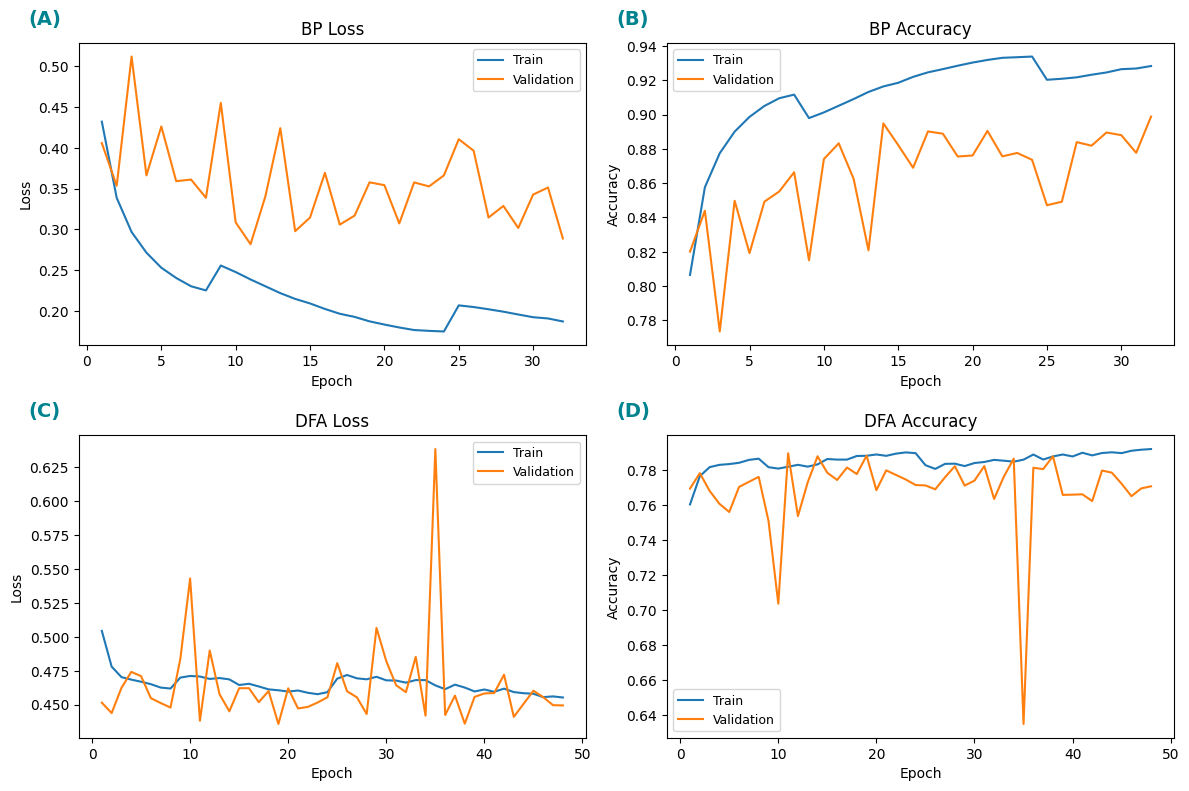

In [13]:
image_per_run, image_descriptive_differences = summarize_dense_results()
plot_dense_learning_curves()

Grad-CAM, seed 42:   0%|          | 0/512 [00:00<?, ?it/s]

,seed,dfa_epoch,resolution,metric,total_pairs,valid_pairs,bp_zero,dfa_zero,bp_constant,dfa_constant,mean,median,sd_population,iqr,ci_low,ci_high,class0_valid_pairs,class1_valid_pairs,class0_mean,class1_mean
0,42,32,native48,iou_10,32768,32754,1,13,1,13,0.05764,0.04289,0.05688,0.05455,0.05703,0.05827,16377,16377,0.05735,0.05792
1,42,32,native48,iou_20,32768,32754,1,13,1,13,0.12101,0.10684,0.07826,0.08165,0.12017,0.12184,16377,16377,0.11773,0.12429
2,42,32,native48,spearman,32768,32754,1,13,1,13,-0.01626,-0.02646,0.15523,0.17342,-0.01796,-0.01457,16377,16377,-0.02396,-0.00856
3,42,32,image96,iou_10,32768,32754,1,13,1,13,0.05621,0.04181,0.05765,0.05456,0.05559,0.05684,16377,16377,0.05627,0.05615
4,42,32,image96,iou_20,32768,32754,1,13,1,13,0.11329,0.10254,0.07090,0.07786,0.11252,0.11407,16377,16377,0.11151,0.11508
5,42,32,image96,spearman,32768,32754,1,13,1,13,-0.02097,-0.03083,0.17992,0.21685,-0.02293,-0.01907,16377,16377,-0.02502,-0.01692
6,42,48,native48,iou_10,32768,32763,1,4,1,4,0.06025,0.04525,0.06000,0.05957,0.05960,0.06090,16386,16377,0.05956,0.06093
7,42,48,native48,iou_20,32768,32763,1,4,1,4,0.11977,0.10552,0.07979,0.08413,0.11892,0.12063,16386,16377,0.11839,0.12114
8,42,48,native48,spearman,32768,32763,1,4,1,4,-0.02846,-0.03477,0.16506,0.19679,-0.03021,-0.02664,16386,16377,-0.04877,-0.00813
9,42,48,image96,iou_10,32768,32763,1,4,1,4,0.05972,0.04358,0.06128,0.06140,0.05904,0.06037,16386,16377,0.05897,0.06046


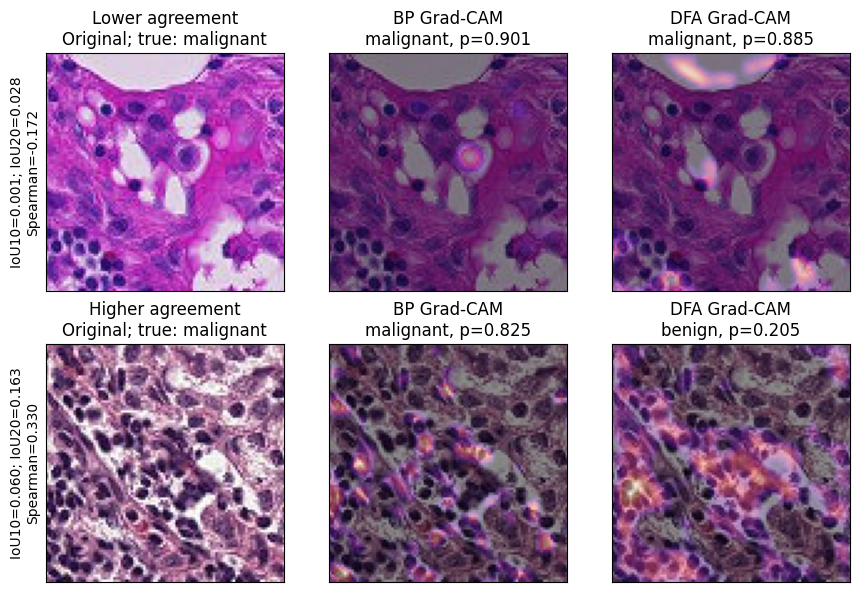

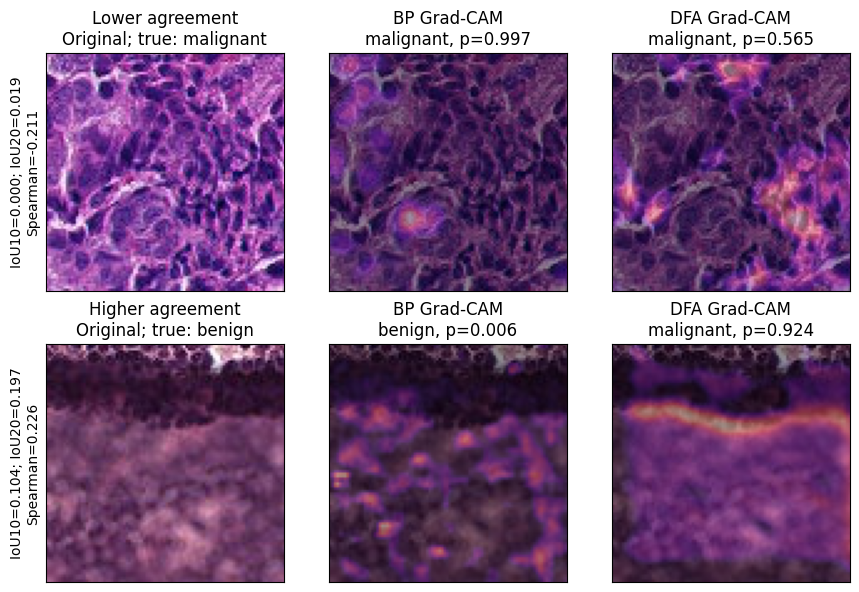

In [14]:
compute_dense_attributions()
image_attribution_summary = summarize_dense_attributions()
plot_dense_attribution_examples(IMAGE_MATCHED_EPOCH)
plot_dense_attribution_examples(IMAGE_DFA_EPOCHS)

## 31. Reading the eventual results

Begin with the matched 32-epoch comparison, checking the actual seed-42 endpoints and descriptive metric differences. The sign of DFA-minus-BP differences is interpreted in the metric's direction: positive accuracy/F1/AUC favors DFA, whereas positive Brier/ECE indicates worse DFA calibration. Report the extra-budget 48-epoch DFA endpoint separately, disclosing the epoch-33 interruption and BF16 continuation described above. Its improvement or deterioration can describe the chosen training trajectory, but cannot resolve a learning-rule effect independently of duration. Check per-epoch losses, AMP skip counts, and individual runs before interpreting endpoint values.

Grad-CAM agreement and predictive performance answer different questions. Similar maps are not evidence of pathology localization correctness or causal faithfulness. Different maps do not alone imply failure. Interpret native versus interpolated agreement with interpolation's smoothing in mind, show constant/zero-map rates, and qualify any conditional-on-valid-map averages. The lower/higher examples are declared quantile selections; the whole-test distribution is the evidence. Calibration slope/intercept are regularized descriptive fits. A single seed does not estimate reproducibility over initialization or training randomness, and no between-seed statistical significance or equivalence claim is made. Patch-bootstrap attribution intervals remain conditional on the trained models and supplied split.

The additional dense connectivity family can strengthen or narrow the manuscript's empirical architectural claim, depending on observed results. It does not establish large-model scalability, transformer suitability, mechanistic equivalence, or unchanged behavior across datasets. The older ResNet-style results remain authoritative and descriptive; their missing replicated quantities must not be invented. No DenseNet outcome or manuscript/reviewer-letter revision is asserted at setup time. Actual result interpretation belongs here after the full notebook outputs are available.

### Observations from the completed seed-42 study

The following values use all 32,768 held-out test patches.

| Endpoint | Accuracy (%) | Macro-F1 | ROC-AUC | Brier | ECE |
|---|---:|---:|---:|---:|---:|
| BP32 | 88.44 | 0.8842 | 0.9548 | 0.0881 | 0.0497 |
| DFA32 | 76.61 | 0.7658 | 0.8483 | 0.1601 | 0.0385 |
| DFA48 | 76.44 | 0.7634 | 0.8506 | 0.1610 | 0.0555 |

At the matched 32-epoch endpoint, DFA-minus-BP accuracy is -11.83 percentage points; the macro-F1 and ROC-AUC differences are -0.1184 and -0.1065. These are descriptive differences from one paired seed.

Between DFA epochs 32 and 48, test accuracy changes by -0.17 percentage points, macro-F1 by -0.0024, and ROC-AUC by +0.0023. This trajectory includes extra training and the documented BF16 continuation; their contributions are not separated.

At image resolution (96-by-96), whole-test Grad-CAM agreement is summarized below. Intervals are 10,000-resample patch-bootstrap intervals for the valid-pair mean, conditional on these models and this split.

| Model pair | Metric | Valid pairs | Mean | 95% interval |
|---|---|---:|---:|---|
| BP32 / DFA32 | iou_10 | 32754 / 32768 | 0.0562 | [0.0556, 0.0568] |
| BP32 / DFA32 | iou_20 | 32754 / 32768 | 0.1133 | [0.1125, 0.1141] |
| BP32 / DFA32 | spearman | 32754 / 32768 | -0.0210 | [-0.0229, -0.0191] |
| BP32 / DFA48 | iou_10 | 32763 / 32768 | 0.0597 | [0.0590, 0.0604] |
| BP32 / DFA48 | iou_20 | 32763 / 32768 | 0.1132 | [0.1124, 0.1140] |
| BP32 / DFA48 | spearman | 32763 / 32768 | -0.0349 | [-0.0369, -0.0328] |

Undefined constant-map pairs are excluded from these agreement means and remain counted in the adjacent full tables. Map agreement does not establish pathology localization accuracy or causal faithfulness. Native-resolution results, class-stratified means, map validity counts, calibration diagnostics, and manuscript-style figures are retained in the executed outputs. No between-seed significance or reproducibility estimate is supported.


In [15]:
for image_dataset in [image_train_dataset, image_val_dataset, image_test_dataset]:
    image_dataset.close()
print('PCam HDF5 handles closed. Recreate the datasets before another training run.')

PCam HDF5 handles closed. Recreate the datasets before another training run.
